# Flood DEM Sensitivity: SRTM vs Copernicus GLO-30 vs ALOS AW3D30

**Studi kasus:** Kota Semarang dan Kabupaten Demak.
**Kerangka:** eksperimen terkontrol untuk mengukur sensitivitas hasil *flood susceptibility mapping* terhadap **sumber produk elevasi**.

Notebook ini adalah implementasi langsung desain kunci proposal Metodologi Penelitian, dibangun sebagai kelanjutan (*sambung tangan*) dari notebook artikel SMDS (`Flood Susceptibility Mapping Notebook.ipynb`). Yang **dikunci identik** di semua konfigurasi:

1. flood inventory Sentinel-1 (dibentuk satu kali),
2. prediktor non-DEM,
3. wilayah penelitian (AOI),
4. prosedur sampling + seed,
5. pembagian data latih-uji + seed,
6. algoritme dan parameter Random Forest (sklearn untuk evaluasi, GEE untuk peta spasial).

Yang **diubah (faktor perlakuan)**: hanya sumber produk elevasi — SRTM, Copernicus DEM GLO-30, ALOS AW3D30 — dari mana prediktor topografi (elevasi, slope, aspect) dihitung.

**Output:**

- 3 peta probabilitas *flood susceptibility* (satu per konfigurasi DEM),
- tabel perbandingan metrik performa (ROC-AUC, accuracy, precision, recall, F1),
- peta dan ringkasan perubahan probabilitas (sensitivitas spasial),
- kesesuaian kelas dan matriks perpindahan kelas antarproduk,
- stratifikasi sensitivitas berdasarkan kelas tutupan lahan ESA WorldCover.

---
**Catatan v27 (reproducibility).** Notebook ini adalah refactor lokal dari v26 untuk memisahkan *pembentukan dataset* dari *eksperimen model*.
Tiga mode eksekusi (variabel `RUN_MODE`, cell konfigurasi):

| Mode | GEE | Fungsi |
|---|---|---|
| `USE_CACHED_DATA` (default) | tidak | Validasi artefak beku (checksum, baris, fitur), lalu seluruh evaluasi dari file beku. |
| `PREPARE_DATA` | ya | Sampling utama + multi-seed dari GEE, bekukan (Parquet + CSV), `manifest.json`, SHA-256. |
| `PREPARE_MAPS` | ya | Latih RF GEE (300 pohon) pada sampel utama beku, unduh GeoTIFF, status ekspor. Tidak ada sampling ulang. |

Desain eksperimen, parameter, dan metode tidak diubah dari v26. RF peta GEE (300 pohon) dan RF evaluasi sklearn (400 pohon) tetap dua model berbeda.

## 0. Dataset yang dipakai

- Sentinel-1 GRD: `COPERNICUS/S1_GRD` — pembentukan *flood inventory* (change detection backscatter).
- Sentinel-2 SR: `COPERNICUS/S2_SR_HARMONIZED` — NDVI, NDWI, MNDWI, NDBI.
- SRTM: `USGS/SRTMGL1_003` — **perlakuan elevasi 1**.
- Copernicus DEM GLO-30: `COPERNICUS/DEM/GLO30` — **perlakuan elevasi 2**.
- ALOS AW3D30: `JAXA/ALOS/AW3D30/V4_1` — **perlakuan elevasi 3**.
- CHIRPS Daily: `UCSB-CHG/CHIRPS/DAILY` — curah hujan antecedent 7 dan 30 hari.
- ESA WorldCover 2021: `ESA/WorldCover/v200` — stratifikasi tutupan lahan.
- MERIT Hydro: `MERIT/Hydro/v1_0_1` — HAND, upstream drainage area, river width.
- JRC Global Surface Water: `JRC/GSW1_4/GlobalSurfaceWater` — masking perairan permanen.

**Catatan desain:** set prediktor di notebook ini mengikuti set baseline artikel SMDS sebagai titik awal. Daftar final prediktor belum dikunci di proposal (menunggu audit literatur); bila nanti berubah, cukup modifikasi bagian *prediktor non-DEM* dan *DEM-derived predictors* — kerangka eksperimen tidak berubah.

## 1. Import library

In [1]:
# Kaggle/Colab: pastikan paket tersedia (diabaikan jika sudah terpasang).
!pip install -q earthengine-api geemap rasterio pyarrow

## 1a. Mode eksekusi, lingkungan, dan path (v27)

Semua path terpusat di kamus `PATHS`. Mode default `USE_CACHED_DATA` tidak menyentuh GEE.

In [2]:
# =========================================================
# v27 - KONFIGURASI TERPUSAT: lingkungan, mode eksekusi, path.
# Semua path dibaca dari kamus PATHS. Jangan menulis path di cell lain.
# =========================================================
import os, sys, json, glob

# --- 1. MODE EKSEKUSI ------------------------------------------------
#   'USE_CACHED_DATA' : DEFAULT. Membaca dataset beku dan menjalankan seluruh
#                       evaluasi. TIDAK ada autentikasi dan TIDAK ada koneksi GEE.
#   'PREPARE_DATA'    : GEE -> sampling utama + multi-seed -> bekukan -> manifest
#                       + checksum. Evaluasi lalu dijalankan dari file beku.
#   'PREPARE_MAPS'    : GEE -> latih RF GEE (300 pohon) pada sampel utama beku ->
#                       GeoTIFF + status ekspor. TIDAK melakukan sampling ulang.
RUN_MODE = 'PREPARE_MAPS'
RUN_MODE = os.environ.get('FLOOD_DEM_RUN_MODE', RUN_MODE)   # override untuk run tanpa UI

_VALID_MODES = ('USE_CACHED_DATA', 'PREPARE_DATA', 'PREPARE_MAPS')
if RUN_MODE not in _VALID_MODES:
    raise ValueError(f'RUN_MODE={RUN_MODE!r} tidak dikenal. Pilih salah satu dari {_VALID_MODES}.')

GEE_REQUIRED = RUN_MODE in ('PREPARE_DATA', 'PREPARE_MAPS')   # hanya dua mode ini yang menyentuh GEE
RUN_EVALUATION = RUN_MODE != 'PREPARE_MAPS'                   # evaluasi RF selalu dari data beku

# Perlindungan artefak: PREPARE_DATA menolak menimpa dataset beku yang sudah ada,
# PREPARE_MAPS melewati raster yang sudah berstatus COMPLETED (bisa dilanjutkan).
OVERWRITE_FROZEN = False
OVERWRITE_RASTERS = False

# Parameter ekspor peta (PREPARE_MAPS).
EXPORT_NODATA = -9999.0
MAP_TILE_PX = 1024            # ukuran tile unduhan (piksel). Perkecil jika GEE menolak karena kompleksitas.

# Opsi lama (v26) yang terbukti gagal/boros di Kaggle. Default MATI, kode lama dipertahankan.
ENABLE_GEE_INTERACTIVE = False   # geemap.Map (ipyleaflet) tidak tersimpan di output Kaggle
ENABLE_GEE_THUMBNAILS = False    # getThumbURL untuk citra hasil RF gagal HTTP 400 di v26
EXPORT_TO_DRIVE_LEGACY = False   # Export.toDrive oleh service account masuk ke Drive service account

# --- 2. DETEKSI LINGKUNGAN -------------------------------------------
def _detect_env():
    if os.path.isdir('/kaggle/working') or os.environ.get('KAGGLE_KERNEL_RUN_TYPE'):
        return 'kaggle'
    if (os.environ.get('COLAB_RELEASE_TAG') or os.environ.get('COLAB_GPU') is not None
            or 'google.colab' in sys.modules):
        return 'colab'
    return 'local'

ENV = _detect_env()

# --- 3. PATH TERPUSAT --------------------------------------------------
_ROOT_BY_ENV = {
    'colab':  '/content/drive/MyDrive/Analisis Flood DEM Susceptibility',
    'kaggle': '/kaggle/working/Analisis Flood DEM Susceptibility',
    'local':  os.path.abspath('Analisis Flood DEM Susceptibility'),
}
ROOT = os.environ.get('FLOOD_DEM_ROOT', _ROOT_BY_ENV[ENV])

def _build_paths(root, data_dir=None):
    data = data_dir or os.path.join(root, 'data')
    return {
        'root': root,
        'sa_json': os.path.join(root, 'gee-service-account.json'),
        'data': data,
        'frozen_main': os.path.join(data, 'frozen', 'main'),
        'frozen_multiseed': os.path.join(data, 'frozen', 'multiseed'),
        'gee_tables': os.path.join(data, 'gee_tables'),
        'rasters': os.path.join(data, 'rasters'),
        'reference_v26': os.path.join(data, 'reference_v26'),
        'manifest': os.path.join(data, 'manifest.json'),
        'export_status': os.path.join(data, 'export_status.json'),
        'outputs': os.path.join(root, 'outputs'),
        'maps_local': os.path.join(root, 'outputs', 'maps_local'),
    }

PATHS = _build_paths(ROOT)

# Kaggle, mode cached: folder data beku biasanya dipasang sebagai Kaggle Dataset
# (read-only) di /kaggle/input. Cari manifest.json milik proyek ini di sana.
DATA_READ_ONLY = False
if ENV == 'kaggle' and RUN_MODE == 'USE_CACHED_DATA' and not os.path.isfile(PATHS['manifest']):
    for _mp in sorted(glob.glob('/kaggle/input/**/manifest.json', recursive=True)):
        try:
            with open(_mp, 'r', encoding='utf-8') as _fh:
                if json.load(_fh).get('artifact_type') == 'flood_dem_frozen_data':
                    PATHS = _build_paths(ROOT, data_dir=os.path.dirname(_mp))
                    DATA_READ_ONLY = True
                    break
        except Exception:
            continue

def ensure_dirs():
    # Buat struktur folder. Folder data tidak disentuh bila read-only (Kaggle Dataset).
    keys = ['outputs', 'maps_local'] if DATA_READ_ONLY else \
           ['frozen_main', 'frozen_multiseed', 'gee_tables', 'rasters', 'reference_v26',
            'outputs', 'maps_local']
    for k in keys:
        os.makedirs(PATHS[k], exist_ok=True)

if ENV != 'colab':      # di Colab, folder dibuat setelah Drive di-mount (cell berikutnya)
    ensure_dirs()

print(f'Lingkungan : {ENV}')
print(f'Mode       : {RUN_MODE} | GEE diperlukan: {GEE_REQUIRED} | evaluasi: {RUN_EVALUATION}')
print(f'Root       : {PATHS["root"]}')
print(f'Data       : {PATHS["data"]}' + ('  (read-only, Kaggle Dataset)' if DATA_READ_ONLY else ''))
print(f'Outputs    : {PATHS["outputs"]}')

Lingkungan : colab
Mode       : PREPARE_MAPS | GEE diperlukan: True | evaluasi: False
Root       : /content/drive/MyDrive/Analisis Flood DEM Susceptibility
Data       : /content/drive/MyDrive/Analisis Flood DEM Susceptibility/data
Outputs    : /content/drive/MyDrive/Analisis Flood DEM Susceptibility/outputs


## 1b. Preamble Google Colab / Drive (v27)

Hanya aktif di Colab. Preamble Kaggle (cell import di bawah) dipertahankan.

In [3]:
# =========================================================
# v27 - PREAMBLE GOOGLE COLAB / DRIVE (terpisah dari preamble Kaggle di cell 1.)
# Hanya aktif jika ENV == 'colab'. Di Kaggle/lokal cell ini tidak melakukan apa pun.
# =========================================================
if ENV == 'colab':
    from google.colab import drive          # aman: hanya diimpor di Colab
    drive.mount('/content/drive')
    if not os.path.isdir(PATHS['root']):
        print('Folder utama belum ada, dibuat:', PATHS['root'])
    ensure_dirs()                           # data/{frozen,gee_tables,rasters,...} dan outputs/{maps_local}

    # Service account hanya wajib bila mode memakai GEE.
    if GEE_REQUIRED:
        _sa = PATHS['sa_json']
        if os.path.isfile(_sa):
            try:
                with open(_sa, 'r', encoding='utf-8') as _fh:
                    _info = json.load(_fh)
                if _info.get('type') == 'service_account':
                    print('Service account ditemukan:', _info.get('client_email'),
                          '| project:', _info.get('project_id'))
                else:
                    print('PERINGATAN: file ada tetapi bukan key service account:', _sa)
            except Exception as _e:
                print('PERINGATAN: service account JSON tidak bisa dibaca:', _e)
        else:
            print('PERINGATAN: service account JSON tidak ditemukan di:', _sa)
            print('            Cell autentikasi akan jatuh ke login interaktif (ee.Authenticate).')
    else:
        print('Mode cached: service account tidak diperlukan.')
else:
    print(f'Preamble Colab dilewati (ENV={ENV}).')

Mounted at /content/drive
Service account ditemukan: nxtirfan@ee-irfan-banjir-2026.iam.gserviceaccount.com | project: ee-irfan-banjir-2026


In [4]:
import os
import time
import math
import warnings
warnings.filterwarnings('ignore')

# v27: OUTPUT_DIR berasal dari konfigurasi terpusat (cell 1a). Mount Drive Colab ada di cell 1b.
# PENTING (tetap berlaku): jangan import google.colab di Kaggle, karena geemap mendeteksi
# keberadaan modul 'google.colab' sebagai tanda lingkungan Colab dan akan mencoba mengambil secret.
OUTPUT_DIR = PATHS['outputs']
os.makedirs(OUTPUT_DIR, exist_ok=True)

# v27: mode cached TIDAK mengimpor ee/geemap (tanpa autentikasi dan tanpa koneksi GEE).
if GEE_REQUIRED:
    import ee
    import geemap
else:
    ee = None
    geemap = None

if GEE_REQUIRED:
    # Kaggle: geemap mendeteksi modul 'google.colab' sebagai lingkungan Colab lalu
    # mencoba mengambil secret (timeout di luar Colab). Patch get_env_var agar
    # HANYA membaca environment variable biasa. TIDAK ada GOOGLE_MAPS_API_KEY yang
    # di-set, sehingga geemap otomatis memakai basemap OpenStreetMap/Esri (tanpa key).
    try:
        import os as _os2
        import geemap.coreutils as _gcu
        _gcu.get_env_var = lambda key, *a, **k: _os2.environ.get(key)
        if hasattr(_gcu, "get_google_maps_api_key"):
            _gcu.get_google_maps_api_key = lambda key="GOOGLE_MAPS_API_KEY", *a, **k: _os2.environ.get(key)
        print("geemap coreutils dipatch (mode tanpa Google Maps API key).")
    except Exception as _e:
        print("Patch geemap dilewati:", _e)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('Output dir:', OUTPUT_DIR)

geemap coreutils dipatch (mode tanpa Google Maps API key).
Output dir: /content/drive/MyDrive/Analisis Flood DEM Susceptibility/outputs


In [5]:
# =========================================================
# v27 - FUNGSI BANTU: pembekuan data, checksum, manifest, validasi cached.
# Hanya JSON dan file biasa. Tidak ada koneksi GEE di cell ini.
# =========================================================
import hashlib, datetime, platform, shutil
from importlib import metadata as _md


class FrozenDataError(RuntimeError):
    """Artefak beku tidak ada, tidak lengkap, atau berubah."""


def _utcnow():
    return datetime.datetime.now(datetime.timezone.utc).strftime('%Y-%m-%dT%H:%M:%SZ')


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for blk in iter(lambda: fh.read(chunk), b''):
            h.update(blk)
    return h.hexdigest()


def write_json_atomic(path, obj):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = path + '.tmp'
    with open(tmp, 'w', encoding='utf-8') as fh:
        json.dump(obj, fh, indent=2, ensure_ascii=False, default=str)
    os.replace(tmp, path)


def _rel(path):
    return os.path.relpath(path, PATHS['data']).replace(os.sep, '/')


def _abs(rel):
    return os.path.join(PATHS['data'], *rel.split('/'))


def _require_writable():
    if DATA_READ_ONLY:
        raise FrozenDataError('Folder data bersifat read-only (Kaggle Dataset). '
                              'Pembekuan hanya bisa dilakukan di folder kerja.')


# --- Versi dependensi (dicatat, TIDAK diubah) ---------------------------
def collect_environment():
    pk = ['numpy', 'pandas', 'scikit-learn', 'scipy', 'pyarrow', 'rasterio',
          'matplotlib', 'earthengine-api', 'geemap']
    ver = {}
    for p in pk:
        try:
            ver[p] = _md.version(p)
        except Exception:
            ver[p] = None
    return {'python': platform.python_version(), 'platform': platform.platform(),
            'environment': ENV, 'packages': ver}


RUN_ENV = collect_environment()
try:
    write_json_atomic(os.path.join(PATHS['outputs'], 'run_environment.json'),
                      {'run_mode': RUN_MODE, 'recorded_at_utc': _utcnow(), **RUN_ENV})
except Exception as _e:
    print('run_environment.json tidak tersimpan:', _e)
print('Versi dependensi:', {k: v for k, v in RUN_ENV['packages'].items() if v})


# --- Manifest -----------------------------------------------------------
def load_manifest():
    p = PATHS['manifest']
    if not os.path.isfile(p):
        return None
    with open(p, 'r', encoding='utf-8') as fh:
        return json.load(fh)


def save_manifest(m):
    _require_writable()
    m['updated_at_utc'] = _utcnow()
    write_json_atomic(PATHS['manifest'], m)


def start_new_manifest():
    return {
        'artifact_type': 'flood_dem_frozen_data',
        'schema_version': 1,
        'notebook': 'Flood_DEM_Sensitivity_Notebook_v27',
        'created_at_utc': _utcnow(),
        'updated_at_utc': _utcnow(),
        'run_mode_created': RUN_MODE,
        'random_state': RANDOM_STATE,
        'seeds_multi': list(SEEDS_MULTI),
        'environment': RUN_ENV,
        'artifact_root_note': 'Semua path artefak RELATIF terhadap folder data (lokasi manifest.json ini).',
        'created_data_root_abs': PATHS['data'],
        'config': {}, 'required_columns': [],
        'gee_assets': {}, 'gee_provenance': {},
        'datasets': {}, 'gee_tables': {}, 'maps': {},
        'notes': ['Dataset utama (main) dan dataset multi-seed dibekukan TERPISAH. '
                  'Seed 42 pada multi-seed BUKAN dataset utama: keduanya berasal dari '
                  'proses sampling berbeda (lihat audit v26).'],
    }


def guard_overwrite():
    if RUN_MODE == 'PREPARE_DATA' and os.path.isfile(PATHS['manifest']) and not OVERWRITE_FROZEN:
        raise FrozenDataError(
            'Dataset beku sudah ada di ' + PATHS['data'] + '. PREPARE_DATA dihentikan agar '
            'dataset yang sudah dipakai tidak tertimpa. Pindahkan/ganti nama folder data, atau '
            'set OVERWRITE_FROZEN = True bila memang ingin membekukan ulang.')


MANIFEST = None
FINGERPRINT_STATUS = {}
_FROZEN_CACHE = {}
if RUN_MODE == 'PREPARE_DATA':
    guard_overwrite()          # gagal cepat, sebelum cell GEE yang mahal berjalan


def init_prepare_manifest():
    # Awal PREPARE_DATA: manifest baru ditulis ke disk. Setelah ini semua pembaruan
    # selalu membaca-ulang dari disk (satu sumber kebenaran).
    global MANIFEST
    _require_writable()
    MANIFEST = start_new_manifest()
    save_manifest(MANIFEST)
    return MANIFEST


def manifest_update(**sections):
    # Perbarui bagian tingkat-atas manifest (config, gee_assets, maps, ...).
    m = load_manifest()
    if m is None:
        raise FrozenDataError('manifest.json belum ada.')
    for k, v in sections.items():
        if isinstance(v, dict) and isinstance(m.get(k), dict):
            m[k].update(v)
        else:
            m[k] = v
    save_manifest(m)
    return m


def config_snapshot():
    keys = ['ROI_MODE', 'SURROUNDING_RECTANGLE', 'BEFORE_START', 'BEFORE_END', 'AFTER_START',
            'AFTER_END', 'S2_START', 'S2_END', 'S1_POLARIZATION', 'S1_RATIO_THRESHOLD',
            'AFTER_DB_THRESHOLD', 'SLOPE_MAX_FOR_FLOOD', 'MIN_CONNECTED_PIXELS',
            'SAMPLE_PER_CLASS_TARGET', 'AUTO_BALANCE_SAMPLE', 'SAMPLE_SCALE', 'TILE_SCALE',
            'RIVER_UPA_THRESHOLD', 'DEM_CONFIGS', 'RF_SKLEARN', 'RF_GEE', 'RISK_CLASS_METHOD',
            'ANALYSIS_CRS', 'ANALYSIS_SCALE', 'APPLY_VERTICAL_OFFSET', 'SAMPLING_MODE',
            'SAMPLE_PER_CLASS', 'SAMPLE_PER_CLASS_FINAL', 'EE_PROJECT', 'fixed_bands',
            'predictor_bands_all']
    g = globals()
    return {k: g[k] for k in keys if k in g}


# --- Pembekuan tabel ------------------------------------------------------
def freeze_table(df, key, folder, extra=None):
    # Simpan tabel mentah hasil GEE: Parquet (utama) + CSV (interoperabilitas).
    # Lalu muat ulang dan BUKTIKAN identik. Metadata masuk ke manifest.
    _require_writable()
    df = df.reset_index(drop=True)
    os.makedirs(folder, exist_ok=True)
    stem = f'sample_{key}_raw'
    p_parq = os.path.join(folder, stem + '.parquet')
    p_csv = os.path.join(folder, stem + '.csv')
    df.to_parquet(p_parq, index=False, engine='pyarrow')
    df.to_csv(p_csv, index=False, float_format='%.17g')       # %.17g: float64 round-trip penuh

    back = pd.read_parquet(p_parq)
    try:
        pd.testing.assert_frame_equal(df, back, check_exact=True)
    except AssertionError as e:
        raise FrozenDataError(f'[{key}] muat ulang Parquet TIDAK identik dengan data sebelum disimpan: {e}')
    csv_ok = True
    try:
        back_csv = pd.read_csv(p_csv, dtype=df.dtypes.to_dict(), float_precision='round_trip')
        pd.testing.assert_frame_equal(df, back_csv, check_exact=True, check_dtype=False)
    except Exception as e:
        csv_ok = False
        print(f'[{key}] PERINGATAN: muat ulang CSV tidak identik ({str(e)[:200]}). Gunakan Parquet.')

    entry = {
        'file_parquet': _rel(p_parq), 'sha256_parquet': sha256_file(p_parq),
        'file_csv': _rel(p_csv), 'sha256_csv': sha256_file(p_csv),
        'csv_roundtrip_identical': csv_ok,
        'n_rows': int(len(df)), 'n_cols': int(df.shape[1]),
        'columns': [str(c) for c in df.columns],
        'dtypes': {str(c): str(t) for c, t in df.dtypes.items()},
        'null_counts': {str(c): int(n) for c, n in df.isna().sum().items()},
        'created_at_utc': _utcnow(),
    }
    entry.update(extra or {})
    m = load_manifest()
    if m is None:
        raise FrozenDataError('manifest.json belum diinisialisasi (init_prepare_manifest).')
    m['datasets'][key] = entry
    save_manifest(m)
    _FROZEN_CACHE.pop(key, None)
    print(f'[{key}] dibekukan: {entry["n_rows"]} baris x {entry["n_cols"]} kolom | '
          f'sha256 parquet {entry["sha256_parquet"][:16]}...')
    return entry


def get_frozen(key):
    # Muat tabel beku (setelah validate_artifacts). Salinan di-cache.
    if key not in _FROZEN_CACHE:
        m = load_manifest()
        if m is None or key not in m.get('datasets', {}):
            raise FrozenDataError(f'Dataset beku "{key}" tidak ada di manifest.')
        _FROZEN_CACHE[key] = pd.read_parquet(_abs(m['datasets'][key]['file_parquet']))
    return _FROZEN_CACHE[key].copy()


_MSG_ACTION = ('\nTindakan: jalankan notebook dengan RUN_MODE = \'PREPARE_DATA\' (butuh GEE) untuk '
               'membentuk dataset beku, atau pulihkan folder data beku yang benar. '
               'Notebook TIDAK akan mengambil data dari GEE secara otomatis.')


def validate_artifacts(keys='all'):
    # Cek: manifest, seed, file ada, SHA-256, jumlah baris, urutan kolom, tipe data,
    # nilai kosong, kolom wajib (prediktor ketiga DEM). Gagal -> FrozenDataError.
    global MANIFEST
    m = load_manifest()
    if m is None:
        raise FrozenDataError('ARTEFAK BEKU TIDAK DITEMUKAN: manifest.json tidak ada di '
                              + PATHS['data'] + '.' + _MSG_ACTION)
    MANIFEST = m
    problems, warns = [], []
    if m.get('artifact_type') != 'flood_dem_frozen_data':
        problems.append('manifest.json bukan manifest proyek ini (artifact_type tidak cocok).')
    if m.get('schema_version') != 1:
        problems.append(f'schema_version manifest {m.get("schema_version")} tidak didukung (diharapkan 1).')
    if m.get('random_state') != RANDOM_STATE:
        problems.append(f'random_state manifest ({m.get("random_state")}) != RANDOM_STATE notebook ({RANDOM_STATE}).')
    if list(m.get('seeds_multi', [])) != list(SEEDS_MULTI):
        problems.append(f'seeds_multi manifest {m.get("seeds_multi")} != SEEDS_MULTI notebook {list(SEEDS_MULTI)}.')

    all_keys = ['main'] + [f'seed_{s}' for s in SEEDS_MULTI]
    want = all_keys if keys == 'all' else list(keys)
    required = list(m.get('required_columns', []))
    dem_req = [f'{p}_{n}' for n in DEM_NAMES
               for p in ('elevation', 'slope', 'aspect_sin', 'aspect_cos', 'aspect_valid')]
    for key in want:
        ent = m.get('datasets', {}).get(key)
        if ent is None:
            problems.append(f'[{key}] tidak tercatat di manifest.')
            continue
        if key.startswith('seed_') and ent.get('seed') != int(key.split('_')[1]):
            problems.append(f'[{key}] seed di manifest ({ent.get("seed")}) tidak sesuai nama dataset.')
        p = _abs(ent['file_parquet'])
        if not os.path.isfile(p):
            problems.append(f'[{key}] file hilang: {p}')
            continue
        if sha256_file(p) != ent['sha256_parquet']:
            problems.append(f'[{key}] SHA-256 Parquet BERBEDA dari manifest: file berubah sejak dibekukan.')
            continue
        try:
            d = pd.read_parquet(p)
        except Exception as e:
            problems.append(f'[{key}] Parquet tidak terbaca: {e}')
            continue
        if len(d) != ent['n_rows']:
            problems.append(f'[{key}] jumlah baris {len(d)} != manifest {ent["n_rows"]}.')
        if [str(c) for c in d.columns] != ent['columns']:
            problems.append(f'[{key}] nama/urutan kolom berbeda dari manifest.')
        elif {str(c): str(t) for c, t in d.dtypes.items()} != ent['dtypes']:
            problems.append(f'[{key}] tipe data kolom berbeda dari manifest.')
        elif {str(c): int(n) for c, n in d.isna().sum().items()} != ent['null_counts']:
            problems.append(f'[{key}] jumlah nilai kosong berbeda dari manifest.')
        miss = [c for c in (['flood', 'lon', 'lat'] + required + dem_req) if c not in d.columns]
        if miss:
            problems.append(f'[{key}] kolom wajib tidak ada: {miss}')
        pc = _abs(ent['file_csv']) if ent.get('file_csv') else None
        if pc and os.path.isfile(pc):
            if sha256_file(pc) != ent['sha256_csv']:
                problems.append(f'[{key}] SHA-256 CSV berbeda dari manifest.')
        elif pc:
            warns.append(f'[{key}] salinan CSV tidak ada (tidak memengaruhi evaluasi, hanya interoperabilitas).')
        if key == 'main' or key.startswith('seed_'):
            _FROZEN_CACHE.pop(key, None)
    if problems:
        raise FrozenDataError('ARTEFAK BEKU TIDAK LENGKAP ATAU BERUBAH:\n  - '
                              + '\n  - '.join(problems) + _MSG_ACTION)
    for w in warns:
        print('Catatan:', w)
    for key in want:
        e = m['datasets'][key]
        print(f'[{key}] OK | {e["n_rows"]} baris x {e["n_cols"]} kolom | sha256 {e["sha256_parquet"][:16]}...')
    print(f'Validasi artefak beku LULUS ({len(want)} dataset).')
    return m


# --- Sidik jari data terproses (mendeteksi drift versi library/kode) ---------
def processed_fingerprint(X, y):
    h = hashlib.sha256()
    h.update('|'.join(map(str, X.columns)).encode('utf-8'))
    h.update(np.ascontiguousarray(X.to_numpy(dtype='float64')).tobytes())
    h.update(np.ascontiguousarray(y.to_numpy(dtype='int64')).tobytes())
    return h.hexdigest()


def record_or_check_fingerprint(key, X, y):
    fp = processed_fingerprint(X, y)
    m = load_manifest()
    ent = (m or {}).get('datasets', {}).get(key)
    if ent is None:
        FINGERPRINT_STATUS[key] = 'tidak ada manifest'
        return
    feat = [str(c) for c in X.columns]
    if RUN_MODE == 'PREPARE_DATA' and 'processed_fingerprint' not in ent and not DATA_READ_ONLY:
        ent['processed_fingerprint'] = fp
        ent['processed_shape'] = [int(X.shape[0]), int(X.shape[1])]
        ent['processed_feature_order'] = feat
        save_manifest(m)
        FINGERPRINT_STATUS[key] = 'dicatat'
        print(f'[{key}] sidik jari data terproses dicatat ({X.shape[0]} baris x {X.shape[1]} fitur).')
    elif ent.get('processed_fingerprint'):
        same = ent['processed_fingerprint'] == fp
        same_order = ent.get('processed_feature_order') == feat
        FINGERPRINT_STATUS[key] = 'cocok' if same else 'BEDA'
        print(f'[{key}] sidik jari data terproses: ' + ('COCOK dengan manifest.' if same else
              'BEDA dari manifest (urutan fitur ' + ('sama' if same_order else 'BEDA') +
              '). Periksa versi pandas/numpy dan kode pembersihan; evaluasi tetap berjalan.'))
    else:
        FINGERPRINT_STATUS[key] = 'tidak ada acuan'


# --- Tabel hasil GEE (statistik dll.) ---------------------------------------
def freeze_gee_table(filename, src_dir=None):
    _require_writable()
    src = os.path.join(src_dir or PATHS['outputs'], filename)
    if not os.path.isfile(src):
        print(f'freeze_gee_table: {filename} tidak ada, dilewati.')
        return None
    dst = os.path.join(PATHS['gee_tables'], filename)
    os.makedirs(PATHS['gee_tables'], exist_ok=True)
    shutil.copyfile(src, dst)
    m = load_manifest()
    if m is None:
        raise FrozenDataError('manifest.json belum ada. Jalankan PREPARE_DATA lebih dulu.')
    m['gee_tables'][filename] = {'file': _rel(dst), 'sha256': sha256_file(dst),
                                 'created_at_utc': _utcnow(), 'created_in_mode': RUN_MODE}
    save_manifest(m)
    return m['gee_tables'][filename]


def load_gee_table(filename, **read_kw):
    # Baca tabel GEE beku dan cek checksum. None + pesan jelas bila tidak tersedia.
    m = load_manifest()
    ent = (m or {}).get('gee_tables', {}).get(filename)
    if ent is None or not os.path.isfile(_abs(ent['file'])):
        print(f'Tabel GEE beku "{filename}" belum tersedia (jalankan PREPARE_DATA/PREPARE_MAPS sesuai jenisnya).')
        return None
    if sha256_file(_abs(ent['file'])) != ent['sha256']:
        raise FrozenDataError(f'Tabel GEE beku "{filename}": SHA-256 berbeda dari manifest.')
    return pd.read_csv(_abs(ent['file']), **read_kw)


print('Fungsi pembekuan/validasi siap. Mode:', RUN_MODE)

Versi dependensi: {'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'scipy': '1.16.3', 'pyarrow': '23.0.1', 'rasterio': '1.5.2', 'matplotlib': '3.10.0', 'earthengine-api': '1.7.39', 'geemap': '0.38.9'}
Fungsi pembekuan/validasi siap. Mode: PREPARE_MAPS


In [6]:
# =========================================================
# v27 - UTILITAS RASTER PETA (semua mode, tanpa GEE saat didefinisikan)
# Grid dipatok eksplisit (EPSG:32749, 30 m, origin kelipatan 30 m) dan dipakai
# sama oleh SEMUA raster dan SEMUA tile -> tidak ada pergeseran antar tile/DEM.
# Status ekspor: PENDING -> RUNNING -> COMPLETED | FAILED (data/export_status.json).
# COMPLETED hanya jika file ada, terbaca, lolos verifikasi grid/nilai, dan SHA-256 tercatat.
# =========================================================
MAP_PAIRS = [('srtm', 'glo30'), ('srtm', 'aw3d30'), ('glo30', 'aw3d30')]
RASTER_KINDS = {'prob': (0.0, 1.0), 'delta': (0.0, 1.0), 'risk': (1, 5),
                'agreement': (0, 1), 'label': (0, 1)}


def _rio():
    try:
        import rasterio
        return rasterio
    except ImportError as e:
        raise ImportError('rasterio belum terpasang. Jalankan: pip install rasterio') from e


def status_load():
    p = PATHS['export_status']
    if os.path.isfile(p):
        with open(p, 'r', encoding='utf-8') as fh:
            return json.load(fh)
    return {'schema_version': 1, 'rasters': {}, 'grid': None, 'validation': None}


def status_save(st):
    _require_writable()
    st['updated_at_utc'] = _utcnow()
    write_json_atomic(PATHS['export_status'], st)


def status_set(name, rec):
    st = status_load()
    st['rasters'][name] = rec
    status_save(st)


def make_grid(x_min, y_min, x_max, y_max, crs='EPSG:32749', res=30.0):
    # Grid yang memuat bounding box, origin dibulatkan ke kelipatan res (sejajar grid GEE 30 m UTM).
    x0 = float(np.floor(x_min / res) * res)
    x1 = float(np.ceil(x_max / res) * res)
    y0 = float(np.floor(y_min / res) * res)
    y1 = float(np.ceil(y_max / res) * res)
    return {'crs': crs, 'res': float(res), 'x0': x0, 'y1': y1,
            'width': int(round((x1 - x0) / res)), 'height': int(round((y1 - y0) / res))}


def grid_tiles(grid, tile_px):
    tiles = []
    for r0 in range(0, grid['height'], tile_px):
        for c0 in range(0, grid['width'], tile_px):
            tiles.append({'row_off': r0, 'col_off': c0,
                          'height': min(tile_px, grid['height'] - r0),
                          'width': min(tile_px, grid['width'] - c0),
                          'x0': grid['x0'] + c0 * grid['res'],
                          'y1': grid['y1'] - r0 * grid['res']})
    return tiles


def read_tile_bytes(data, tile, grid):
    # Baca GeoTIFF satu tile dari memori dan BUKTIKAN grid-nya persis seperti yang diminta.
    rasterio = _rio()
    from rasterio.io import MemoryFile
    with MemoryFile(data) as mf:
        with mf.open() as ds:
            tr = ds.transform
            ok = (ds.count == 1 and ds.width == tile['width'] and ds.height == tile['height']
                  and abs(tr.a - grid['res']) < 1e-6 and abs(tr.e + grid['res']) < 1e-6
                  and abs(tr.c - tile['x0']) < 1e-6 and abs(tr.f - tile['y1']) < 1e-6
                  and ds.crs is not None and ds.crs.to_epsg() == int(grid['crs'].split(':')[1]))
            if not ok:
                raise RuntimeError(
                    f'Grid tile tidak sesuai permintaan: dapat (w={ds.width},h={ds.height},'
                    f'a={tr.a},e={tr.e},c={tr.c},f={tr.f},crs={ds.crs}) vs diminta '
                    f'(w={tile["width"]},h={tile["height"]},x0={tile["x0"]},y1={tile["y1"]}).')
            arr = ds.read(1).astype('float32')
    return np.where(np.isfinite(arr), arr, np.float32(EXPORT_NODATA)).astype('float32')


def mosaic_tiles(tile_arrays, grid):
    # Gabungkan tile ke satu array penuh dan buktikan: tidak ada celah, tidak ada tumpang tindih.
    H, W = grid['height'], grid['width']
    mosaic = np.full((H, W), np.nan, dtype='float32')
    cover = np.zeros((H, W), dtype='uint8')
    for tile, arr in tile_arrays:
        r0, c0, th, tw = tile['row_off'], tile['col_off'], tile['height'], tile['width']
        if arr.shape != (th, tw):
            raise RuntimeError(f'Ukuran array tile {arr.shape} != ({th}, {tw}).')
        mosaic[r0:r0 + th, c0:c0 + tw] = arr
        cover[r0:r0 + th, c0:c0 + tw] += 1
    gaps, overlaps = int((cover == 0).sum()), int((cover > 1).sum())
    if gaps or overlaps:
        raise RuntimeError(f'Mosaik tile tidak sempurna: celah={gaps} piksel, tumpang tindih={overlaps} piksel.')
    return mosaic


def write_geotiff(path, arr, grid, tags=None, description=None):
    rasterio = _rio()
    from rasterio.transform import from_origin
    os.makedirs(os.path.dirname(path), exist_ok=True)
    profile = dict(driver='GTiff', height=grid['height'], width=grid['width'], count=1,
                   dtype='float32', crs=grid['crs'],
                   transform=from_origin(grid['x0'], grid['y1'], grid['res'], grid['res']),
                   nodata=EXPORT_NODATA, compress='deflate', tiled=True,
                   blockxsize=256, blockysize=256)
    with rasterio.open(path, 'w', **profile) as dst:
        dst.write(arr.astype('float32'), 1)
        if description:
            dst.set_band_description(1, description)
        dst.update_tags(**{k: str(v) for k, v in (tags or {}).items()})


def verify_raster(path, grid, kind):
    # Periksa CRS, transform, ukuran, resolusi, tipe, NoData, dan rentang nilai. Raise bila ada pelanggaran.
    rasterio = _rio()
    from rasterio.transform import from_origin
    errs, info = [], {}
    if not os.path.isfile(path):
        raise RuntimeError(f'file tidak ditemukan: {path}')
    with rasterio.open(path) as ds:
        exp = from_origin(grid['x0'], grid['y1'], grid['res'], grid['res'])
        if ds.crs is None or ds.crs.to_epsg() != int(grid['crs'].split(':')[1]):
            errs.append(f'CRS {ds.crs} != {grid["crs"]}')
        if not np.allclose(tuple(ds.transform)[:6], tuple(exp)[:6], atol=1e-9):
            errs.append(f'transform {tuple(ds.transform)[:6]} != {tuple(exp)[:6]}')
        if (ds.width, ds.height) != (grid['width'], grid['height']):
            errs.append(f'ukuran {(ds.width, ds.height)} != {(grid["width"], grid["height"])}')
        if ds.res != (grid['res'], grid['res']):
            errs.append(f'resolusi {ds.res} != {(grid["res"], grid["res"])}')
        if ds.count != 1 or ds.dtypes[0] != 'float32':
            errs.append(f'band/tipe {ds.count}/{ds.dtypes} != 1/float32')
        if ds.nodata != EXPORT_NODATA:
            errs.append(f'NoData {ds.nodata} != {EXPORT_NODATA}')
        arr = ds.read(1)
        info['bounds'] = tuple(ds.bounds)
    valid = np.isfinite(arr) & (arr != EXPORT_NODATA)
    info['n_valid'] = int(valid.sum())
    info['n_nodata'] = int(arr.size - valid.sum())
    if info['n_valid'] == 0:
        errs.append('tidak ada piksel valid (raster kosong)')
    else:
        v = arr[valid]
        lo, hi = RASTER_KINDS[kind]
        info['min'], info['max'] = float(v.min()), float(v.max())
        if v.min() < lo - 1e-6 or v.max() > hi + 1e-6:
            errs.append(f'rentang nilai [{v.min():.6g}, {v.max():.6g}] di luar [{lo}, {hi}]')
        if kind in ('risk', 'agreement', 'label') and not np.all(v == np.round(v)):
            errs.append('nilai kelas tidak bulat')
    if errs:
        raise RuntimeError('Verifikasi raster gagal: ' + ' | '.join(errs))
    return info


def export_raster(name, kind, image, grid, fetch, tile_px=None):
    # fetch(image, tile) -> bytes GeoTIFF. Dipisah agar logika ini bisa diuji tanpa GEE.
    tile_px = tile_px or MAP_TILE_PX
    path = os.path.join(PATHS['rasters'], name + '.tif')
    st = status_load().get('rasters', {}).get(name, {})
    if (not OVERWRITE_RASTERS and st.get('status') == 'COMPLETED' and os.path.isfile(path)
            and sha256_file(path) == st.get('sha256')):
        print(f'{name}: COMPLETED sebelumnya (checksum cocok), dilewati.')
        return st
    rec = {'status': 'PENDING', 'kind': kind, 'file': _rel(path), 'tile_px': tile_px,
           'pending_at_utc': _utcnow()}
    status_set(name, rec)
    try:
        rec['status'] = 'RUNNING'
        rec['started_at_utc'] = _utcnow()
        status_set(name, rec)
        tiles = grid_tiles(grid, tile_px)
        arrays = []
        for i, tile in enumerate(tiles, 1):
            t0 = time.time()
            data = None
            for attempt in range(1, 4):
                try:
                    data = fetch(image, tile)
                    break
                except Exception as e:
                    txt = f'{type(e).__name__}: {e}'
                    body = getattr(e, 'content', None)
                    if body:
                        txt += ' | ' + (body.decode('utf-8', 'replace') if isinstance(body, bytes) else str(body))[:2000]
                    print(f'  {name} tile {i}/{len(tiles)} percobaan {attempt}/3 gagal: {txt[:500]}')
                    last_err = txt
                    if attempt < 3:
                        time.sleep(5 * attempt)
            if data is None:
                raise RuntimeError(f'tile {i}/{len(tiles)} gagal 3x. Pesan terakhir: {last_err}')
            arrays.append((tile, read_tile_bytes(data, tile, grid)))
            print(f'  {name} tile {i}/{len(tiles)} OK ({time.time() - t0:.0f} s)')
        mosaic = mosaic_tiles(arrays, grid)
        write_geotiff(path, mosaic, grid, description=name, tags={
            'name': name, 'kind': kind, 'created_at_utc': _utcnow(),
            'source': 'GEE computePixels', 'notebook': 'Flood_DEM_Sensitivity_Notebook_v27',
            'grid_crs': grid['crs'], 'grid_res_m': grid['res'], 'nodata': EXPORT_NODATA,
            'risk_class_breaks': json.dumps(globals().get('BREAKS')),
            'rf_gee_trees': (globals().get('RF_GEE') or {}).get('numberOfTrees')})
        info = verify_raster(path, grid, kind)
        rec.update({'status': 'COMPLETED', 'finished_at_utc': _utcnow(), 'sha256': sha256_file(path),
                    'size_bytes': os.path.getsize(path), 'n_valid': info['n_valid'],
                    'n_nodata': info['n_nodata'], 'min': info['min'], 'max': info['max']})
        status_set(name, rec)
        print(f'{name}: COMPLETED | valid={info["n_valid"]} nodata={info["n_nodata"]} '
              f'rentang=[{info["min"]:.4g}, {info["max"]:.4g}]')
    except Exception as e:
        rec.update({'status': 'FAILED', 'finished_at_utc': _utcnow(),
                    'error': f'{type(e).__name__}: {e}'})
        status_set(name, rec)
        print(f'{name}: FAILED -> {rec["error"]}')
    return rec


def _raster_array(name):
    rasterio = _rio()
    with rasterio.open(os.path.join(PATHS['rasters'], name + '.tif')) as ds:
        arr = ds.read(1)
    return arr, (np.isfinite(arr) & (arr != EXPORT_NODATA))


def _gee_table_any(filename, **kw):
    t = None
    try:
        t = load_gee_table(filename, **kw)
    except FrozenDataError as e:
        print(e)
    if t is None:
        p = os.path.join(PATHS['outputs'], filename)
        if os.path.isfile(p):
            t = pd.read_csv(p, **kw)
    return t


def verify_all_rasters(grid=None, aoi_pixel_count=None):
    # Verifikasi menyeluruh: grid identik untuk SEMUA raster (termasuk ketiga DEM), NoData, nilai,
    # konsistensi probabilitas-kelas-delta-agreement, dan statistik vs tabel GEE.
    st = status_load()
    grid = grid or st.get('grid')
    checks = []

    def add(name, status, detail):
        checks.append({'check': name, 'status': status, 'detail': detail})

    names = sorted(st['rasters'])
    done = [n for n in names if st['rasters'][n]['status'] == 'COMPLETED']
    bad = [n for n in names if st['rasters'][n]['status'] != 'COMPLETED']
    add('status_ekspor', 'PASS' if not bad else 'FAIL',
        f'{len(done)} COMPLETED' + (f' | belum selesai/gagal: {bad}' if bad else ''))
    if not done or grid is None:
        return checks

    infos = {}
    for n in done:
        rec = st['rasters'][n]
        p = os.path.join(PATHS['rasters'], n + '.tif')
        try:
            if sha256_file(p) != rec['sha256']:
                raise RuntimeError('SHA-256 berbeda dari export_status.json')
            infos[n] = verify_raster(p, grid, rec['kind'])
        except Exception as e:
            add(f'raster:{n}', 'FAIL', str(e))
    if infos:
        add('grid_identik_semua_raster', 'PASS' if len(infos) == len(done) else 'FAIL',
            f'{len(infos)}/{len(done)} raster lolos CRS/transform/ukuran/resolusi/NoData/rentang '
            f'terhadap grid yang sama; extent={next(iter(infos.values()))["bounds"]}')

    def have(*ns):
        return all(n in infos for n in ns)

    # NoData antar DEM
    for kind_prefix in ('prob', 'risk_class'):
        ns = [f'{kind_prefix}_{d}' for d in DEM_NAMES]
        if have(*ns):
            masks = [_raster_array(n)[1] for n in ns]
            diff = [int((masks[0] != m).sum()) for m in masks[1:]]
            add(f'nodata_antar_DEM:{kind_prefix}', 'PASS' if not any(diff) else 'INFO',
                f'valid per DEM={[int(m.sum()) for m in masks]} | piksel beda mask vs {ns[0]}: {diff}')
    if aoi_pixel_count and have(f'prob_{DEM_NAMES[0]}'):
        nv = infos[f'prob_{DEM_NAMES[0]}']['n_valid']
        add('piksel_valid_vs_hitungan_GEE', 'PASS' if abs(nv - aoi_pixel_count) / aoi_pixel_count < 1e-3 else 'INFO',
            f'raster={nv} | GEE={aoi_pixel_count} | selisih relatif={(nv - aoi_pixel_count) / aoi_pixel_count:+.2e}')

    # konsistensi prob -> kelas
    brk = globals().get('BREAKS') or (load_manifest() or {}).get('maps', {}).get('breaks')
    for d in DEM_NAMES:
        if have(f'prob_{d}', f'risk_class_{d}') and brk:
            p, pm = _raster_array(f'prob_{d}')
            r, rm = _raster_array(f'risk_class_{d}')
            exp = 1 + (p > brk[0]).astype(int) + (p > brk[1]) + (p > brk[2]) + (p > brk[3])
            both = pm & rm
            mism = both & (exp != r)
            near = np.min(np.abs(p[..., None] - np.array(brk)), axis=-1) <= 1e-6
            real = int((mism & ~near).sum())
            add(f'prob_vs_kelas:{d}', 'PASS' if real == 0 else 'FAIL',
                f'selisih di luar tepi batas kelas={real} | di tepi batas (presisi float32)={int((mism & near).sum())}')

    # delta & agreement vs hitungan lokal
    for a, b in MAP_PAIRS:
        if have(f'prob_{a}', f'prob_{b}', f'delta_abs_{a}_vs_{b}'):
            pa, ma = _raster_array(f'prob_{a}')
            pb, mb = _raster_array(f'prob_{b}')
            dd, md = _raster_array(f'delta_abs_{a}_vs_{b}')
            both = ma & mb & md
            mx = float(np.abs(np.abs(pa - pb)[both] - dd[both]).max()) if both.any() else float('nan')
            add(f'delta_lokal:{a}_vs_{b}', 'PASS' if mx < 1e-6 else 'FAIL', f'maks |selisih| = {mx:.3e}')
        if have(f'risk_class_{a}', f'risk_class_{b}', f'agreement_{a}_vs_{b}'):
            ra, mra = _raster_array(f'risk_class_{a}')
            rb, mrb = _raster_array(f'risk_class_{b}')
            ag, mag = _raster_array(f'agreement_{a}_vs_{b}')
            both = mra & mrb & mag
            mism = int(((ra == rb)[both].astype(float) != ag[both]).sum())
            add(f'agreement_lokal:{a}_vs_{b}', 'PASS' if mism == 0 else 'FAIL', f'piksel beda = {mism}')

    # statistik dari raster vs tabel GEE
    ss = _gee_table_any('sensitivity_summary.csv')
    for a, b in MAP_PAIRS:
        lab = f'{a} vs {b}'
        if ss is not None and have(f'delta_abs_{a}_vs_{b}', f'agreement_{a}_vs_{b}'):
            dd, md = _raster_array(f'delta_abs_{a}_vs_{b}')
            ag, mag = _raster_array(f'agreement_{a}_vs_{b}')
            row = ss[ss['pair'] == lab]
            if len(row):
                g_d, g_a = float(row['mean_abs_delta_prob'].iloc[0]), float(row['agreement_rate'].iloc[0])
                l_d, l_a = float(dd[md].mean()), float(ag[mag].mean())
                ok = abs(l_d - g_d) < 1e-3 and abs(l_a - g_a) < 1e-3
                add(f'statistik_vs_GEE:{lab}', 'PASS' if ok else 'INFO',
                    f'mean|dP| raster={l_d:.5f} GEE={g_d:.5f} | agreement raster={l_a:.5f} GEE={g_a:.5f}')
        tt = _gee_table_any(f'transition_{a}_vs_{b}.csv', index_col=0)
        if tt is not None and have(f'risk_class_{a}', f'risk_class_{b}'):
            ra, mra = _raster_array(f'risk_class_{a}')
            rb, mrb = _raster_array(f'risk_class_{b}')
            both = mra & mrb
            M = np.zeros((5, 5), dtype='int64')
            np.add.at(M, (ra[both].astype(int) - 1, rb[both].astype(int) - 1), 1)
            G = tt.to_numpy(dtype='int64')
            rel = float(np.abs(M - G).sum() / max(G.sum(), 1))
            add(f'transisi_vs_GEE:{lab}', 'PASS' if rel == 0 else ('INFO' if rel < 1e-3 else 'FAIL'),
                f'total |selisih sel| / total piksel = {rel:.2e}')
    at = _gee_table_any('area_per_risk_class_km2.csv', index_col=0)
    if at is not None:
        for d in DEM_NAMES:
            if have(f'risk_class_{d}') and d in at.columns:
                r, mr = _raster_array(f'risk_class_{d}')
                loc = np.array([(r[mr] == c).sum() for c in range(1, 6)]) * (grid['res'] ** 2) / 1e6
                g = at[d].reindex(range(1, 6)).fillna(0).to_numpy()
                rel = float(np.abs(loc - g).sum() / max(g.sum(), 1e-9))
                add(f'luas_vs_GEE:{d}', 'PASS' if rel < 2e-3 else 'INFO',
                    f'selisih relatif total = {rel:.2e} (lokal memakai 900 m2/piksel, GEE memakai pixelArea)')
    return checks


def print_checks(checks):
    for c in checks:
        print(f'[{c["status"]:<4}] {c["check"]}: {c["detail"]}')
    n_fail = sum(c['status'] == 'FAIL' for c in checks)
    print(f'Ringkasan: {sum(c["status"] == "PASS" for c in checks)} PASS, '
          f'{sum(c["status"] == "INFO" for c in checks)} INFO, {n_fail} FAIL')
    return n_fail

print('Utilitas raster siap. Verifikasi memakai grid yang dipatok eksplisit.')

Utilitas raster siap. Verifikasi memakai grid yang dipatok eksplisit.


In [7]:
# =========================================================
# v27 - GLOBAL MORAN'S I (diagnostik pendukung). Hanya Global, TIDAK ada LISA.
# Mandiri (numpy + scipy), tanpa libpysal/esda, kompatibel Kaggle dan Colab.
#
# Definisi (W distandardisasi baris, sehingga S0 = n):
#   I = (n / S0) * sum_ij w_ij z_i z_j / sum_i z_i^2,   z_i = x_i - mean(x)
#   E[I] = -1 / (n - 1) di bawah H0 (tidak ada autokorelasi spasial)
# Inferensi: PERMUTASI KONDISIONAL. Nilai x diacak lintas lokasi tetap, I dihitung ulang
# B kali. p dua sisi = (1 + #{|I_perm - E[I]| >= |I_obs - E[I]|}) / (B + 1).
# Deret permutasi ditentukan seed (RandomState(seed)), sehingga IDENTIK untuk ketiga DEM
# dan untuk setiap variabel yang dibandingkan (perbandingan berpasangan yang adil).
# =========================================================
from scipy.spatial import cKDTree

MORAN_K_PRIMARY = 8            # tetangga terdekat (kNN) untuk W utama
MORAN_K_SENSITIVITY = [5, 12]  # uji kepekaan terhadap definisi W
MORAN_B_POINTS = 9999          # jumlah permutasi (titik)
MORAN_B_MAP = 999              # jumlah permutasi (raster peta; mahal secara komputasi)
MORAN_SEED = 42


def project_to_utm(lon, lat, crs='EPSG:32749'):
    # lon/lat (derajat) -> meter pada CRS analisis proyek (UTM 49S), agar jarak kNN dalam meter.
    from rasterio.warp import transform
    xs, ys = transform('EPSG:4326', crs, list(map(float, lon)), list(map(float, lat)))
    return np.column_stack([xs, ys])


def knn_neighbors(xy, k):
    # k tetangga terdekat (tanpa diri sendiri). W row-standardized: tiap tetangga berbobot 1/k.
    tree = cKDTree(xy)
    d, idx = tree.query(xy, k=k + 1)
    if np.any(d[:, 1] == 0):
        raise ValueError('Ada titik dengan koordinat identik. Pada data titik duplikat, kNN tidak terdefinisi tegas.')
    return idx[:, 1:], d[:, 1:]


def moran_points(x, nbr, B=None, seed=None):
    # Global Moran's I untuk data titik, W = kNN row-standardized.
    B = MORAN_B_POINTS if B is None else B
    seed = MORAN_SEED if seed is None else seed
    x = np.asarray(x, dtype='float64')
    n = len(x)
    z = x - x.mean()
    ss = float((z * z).sum())
    if ss == 0:
        raise ValueError('Varians nol: Moran\'s I tidak terdefinisi.')
    I_obs = float((z * z[nbr].mean(axis=1)).sum() / ss)
    EI = -1.0 / (n - 1)
    rng = np.random.RandomState(seed)
    Ip = np.empty(B)
    for b in range(B):
        zp = z[rng.permutation(n)]
        Ip[b] = (zp * zp[nbr].mean(axis=1)).sum() / ss
    return _moran_summary(I_obs, EI, Ip, n)


def _moran_summary(I_obs, EI, Ip, n):
    B = len(Ip)
    return {'n': int(n), 'I': float(I_obs), 'E_I': float(EI),
            'perm_mean': float(Ip.mean()), 'perm_sd': float(Ip.std(ddof=1)),
            'z_perm': float((I_obs - Ip.mean()) / Ip.std(ddof=1)),
            'p_two_sided': float((1 + np.sum(np.abs(Ip - EI) >= abs(I_obs - EI))) / (B + 1)),
            'p_upper': float((1 + np.sum(Ip >= I_obs)) / (B + 1)),
            'p_lower': float((1 + np.sum(Ip <= I_obs)) / (B + 1)),
            'n_perm': int(B), 'p_min_resolvable': 1.0 / (B + 1)}


def _shift_sum(a):
    # Jumlah 8 tetangga queen untuk setiap piksel (tepi diperlakukan tanpa tetangga di luar grid).
    H, W = a.shape
    out = np.zeros_like(a)
    out[1:, :] += a[:-1, :]
    out[:-1, :] += a[1:, :]
    out[:, 1:] += a[:, :-1]
    out[:, :-1] += a[:, 1:]
    out[1:, 1:] += a[:-1, :-1]
    out[1:, :-1] += a[:-1, 1:]
    out[:-1, 1:] += a[1:, :-1]
    out[:-1, :-1] += a[1:, 1:]
    return out


def moran_raster(arr, valid, B=None, seed=None):
    # Global Moran's I untuk raster (W queen, row-standardized). Hanya piksel valid yang punya
    # minimal satu tetangga valid ikut dihitung (piksel terisolasi dikeluarkan).
    B = MORAN_B_MAP if B is None else B
    seed = MORAN_SEED if seed is None else seed
    v = np.where(valid, arr, 0).astype('float32')
    m = valid.astype('float32')
    cnt = _shift_sum(m)
    use = valid & (cnt > 0)
    n = int(use.sum())
    vals = v[use].astype('float64')
    mean = vals.mean()
    zfull = np.zeros_like(v)
    zfull[use] = (vals - mean).astype('float32')
    # relasi tetangga simetris: piksel terisolasi tidak pernah menjadi tetangga piksel lain, jadi cnt konsisten
    ss = float((zfull[use].astype('float64') ** 2).sum())
    if ss == 0:
        raise ValueError('Varians nol: Moran\'s I tidak terdefinisi.')
    cnt_safe = np.where(cnt > 0, cnt, 1).astype('float32')

    def _I(zf):
        lag = _shift_sum(zf) / cnt_safe
        return float((zf[use].astype('float64') * lag[use].astype('float64')).sum() / ss)

    I_obs = _I(zfull)
    EI = -1.0 / (n - 1)
    rng = np.random.RandomState(seed)
    zvals = zfull[use].copy()
    Ip = np.empty(B)
    for b in range(B):
        zp = np.zeros_like(zfull)
        zp[use] = zvals[rng.permutation(n)]
        Ip[b] = _I(zp)
    return _moran_summary(I_obs, EI, Ip, n)


print('Fungsi Global Moran\'s I siap (kNN titik, queen raster, permutasi kondisional).')

Fungsi Global Moran's I siap (kNN titik, queen raster, permutasi kondisional).


## 2. Autentikasi Google Earth Engine

In [8]:
GEE_ASSET_INFO = {}   # v27: diisi bila GEE dipakai
if GEE_REQUIRED:
    # =========================================================
    # Autentikasi Google Earth Engine.
    # Cara utama: Service Account key JSON (TANPA login popup setiap run).
    #   1. Buat key: https://console.cloud.google.com/iam-admin/serviceaccounts
    #      -> pilih project -> Keys -> Add key -> JSON.
    #   2. Beri role 'Service Usage Consumer' dan daftarkan akun Earth Engine
    #      (https://code.earthengine.google.com/register) dengan project yang sama.
    #   3. Simpan file JSON di Drive folder
    #      GEE_DEM_Sensitivity_Semarang_Demak/ dengan nama gee-service-account.json
    # Jika key tidak ditemukan, fallback ke ee.Authenticate() interaktif.
    # =========================================================
    EE_PROJECT = "ee-irfan-banjir-2026"

    import os as _os, json as _json, base64 as _b64

    _service_email, _key_path = None, None

    def _try_use_key(path):
        global _service_email, _key_path
        try:
            with open(path, 'r', encoding='utf-8') as fh:
                info = _json.load(fh)
            if info.get('type') != 'service_account':
                print('Bukan service account key:', path)
                return False
            creds = ee.ServiceAccountCredentials(info['client_email'], path)
            ee.Initialize(credentials=creds, project=(info.get('project_id') or EE_PROJECT or None))
            _service_email, _key_path = info['client_email'], path
            return True
        except Exception as e:
            print('Key gagal dipakai (%s): %s' % (path, e))
            return False

    _key_candidates = [
        '/kaggle/input/datasets/nxtirfan/gee-service-account-credential/gee-service-account.json',
        '/kaggle/input/gee-service-account-credential/gee-service-account.json',
        '/content/drive/MyDrive/GEE_DEM_Sensitivity_Semarang_Demak/gee-service-account.json',
        '/content/gee-service-account.json',
        '/kaggle/working/gee-service-account.json',
        'gee-service-account.json',
    ]

    # Kaggle: cari file kredensial secara rekursif di seluruh /kaggle/input
    # (nama folder mount dapat berbeda dari dugaan).
    try:
        import glob as _glob
        if _os.path.isdir('/kaggle/input'):
            print('/kaggle/input berisi:', _os.listdir('/kaggle/input'))
            _found = _glob.glob('/kaggle/input/**/*service-account*.json', recursive=True)
            print('Kandidat kredensial ditemukan via glob:', _found)
            for _f in _found:
                _key_candidates.insert(0, _f)
    except Exception as _e:
        print('Glob /kaggle/input dilewati:', _e)
    if _os.environ.get('GOOGLE_APPLICATION_CREDENTIALS'):
        _key_candidates.insert(0, _os.environ['GOOGLE_APPLICATION_CREDENTIALS'])

    # Kaggle Secrets (isi JSON sebagai string)
    try:
        from kaggle_secrets import UserSecretsClient
        _sec = UserSecretsClient().get_secret("GEE_SERVICE_ACCOUNT_JSON")
        if _sec and 'service_account' in _sec:
            try:
                _sec = _b64.b64decode(_sec).decode('utf-8')
            except Exception:
                pass
            _p = '/kaggle/working/gee-service-account.json'
            with open(_p, 'w', encoding='utf-8') as fh:
                fh.write(_sec)
            _key_candidates.insert(0, _p)
    except Exception:
        pass

    _key_candidates.insert(0, PATHS['sa_json'])   # v27: path Colab/Drive dari konfigurasi terpusat
    _initialized = False
    for _p in _key_candidates:
        if _p and _os.path.exists(_p):
            _initialized = _try_use_key(_p)
            if _initialized:
                break

    if not _initialized:
        print('Service account key tidak ditemukan/gagal. Fallback ke login interaktif...')
        ee.Authenticate()
        ee.Initialize(project=EE_PROJECT) if EE_PROJECT else ee.Initialize()

    if _service_email:
        print('GEE siap via service account:', _service_email)
    else:
        print('GEE siap via login interaktif.')

    # v27: periksa akses project GEE dan catat identitas/versi aset (masuk manifest).
    GEE_ASSET_IDS = ['FAO/GAUL/2015/level2', 'COPERNICUS/S1_GRD', 'COPERNICUS/S2_SR_HARMONIZED',
                     'USGS/SRTMGL1_003', 'COPERNICUS/DEM/GLO30', 'JAXA/ALOS/AW3D30/V4_1',
                     'UCSB-CHG/CHIRPS/DAILY', 'ESA/WorldCover/v200', 'MERIT/Hydro/v1_0_1',
                     'JRC/GSW1_4/GlobalSurfaceWater']


    def check_gee_access():
        try:
            assert ee.Number(1).add(1).getInfo() == 2
        except Exception as e:
            raise RuntimeError('Project GEE tidak bisa menjalankan komputasi. Periksa registrasi Earth Engine, '
                               f'role Service Usage Consumer, dan project "{EE_PROJECT}". Pesan: {e}')
        for aid in GEE_ASSET_IDS:
            try:
                info = ee.data.getAsset(aid)
                GEE_ASSET_INFO[aid] = {'status': 'OK', 'type': info.get('type'),
                                       'updateTime': info.get('updateTime'), 'version': info.get('version'),
                                       'title': (info.get('properties') or {}).get('title')}
            except Exception as e:
                GEE_ASSET_INFO[aid] = {'status': 'ERROR', 'error': str(e)[:300]}
            print(f'  aset {aid}: {GEE_ASSET_INFO[aid]["status"]}')


    check_gee_access()
else:
    print('Mode cached: autentikasi dan koneksi GEE dilewati (tidak diperlukan).')

/kaggle/input berisi: []
Kandidat kredensial ditemukan via glob: []
GEE siap via service account: nxtirfan@ee-irfan-banjir-2026.iam.gserviceaccount.com
  aset FAO/GAUL/2015/level2: OK
  aset COPERNICUS/S1_GRD: OK
  aset COPERNICUS/S2_SR_HARMONIZED: OK
  aset USGS/SRTMGL1_003: OK
  aset COPERNICUS/DEM/GLO30: OK
  aset JAXA/ALOS/AW3D30/V4_1: OK
  aset UCSB-CHG/CHIRPS/DAILY: OK
  aset ESA/WorldCover/v200: OK
  aset MERIT/Hydro/v1_0_1: OK
  aset JRC/GSW1_4/GlobalSurfaceWater: OK


## 3. Parameter wilayah, tanggal, dan eksperimen

In [9]:
# =========================================================
# PARAMETER WILAYAH
# =========================================================
# ROI mengikuti baseline: Kota Semarang + Kabupaten Demak (FAO GAUL level 2).
ROI_MODE = 'SEMDEMAK_ONLY'
SURROUNDING_RECTANGLE = [109.95, -7.45, 111.05, -6.65]  # [lon_min, lat_min, lon_max, lat_max]

# Kejadian banjir: sama dengan baseline (banjir Jawa Tengah / Demak II, Maret 2024).
BEFORE_START = '2024-02-25'
BEFORE_END   = '2024-03-12'
AFTER_START  = '2024-03-15'
AFTER_END    = '2024-03-31'

# Komposit Sentinel-2 untuk prediktor permukaan (periode normal, hindari data leakage).
S2_START = '2023-06-01'
S2_END   = '2023-10-31'

# Parameter label banjir Sentinel-1 (identik baseline).
S1_POLARIZATION = 'VH'
S1_RATIO_THRESHOLD = 1.25
AFTER_DB_THRESHOLD = -18
SLOPE_MAX_FOR_FLOOD = 5
MIN_CONNECTED_PIXELS = 8

# Sampling (identik untuk semua konfigurasi).
SAMPLE_PER_CLASS_TARGET = 3000
AUTO_BALANCE_SAMPLE = True
SAMPLE_SCALE = 30
TILE_SCALE = 8

RIVER_UPA_THRESHOLD = 10  # km^2, threshold upstream area untuk dist_river

MAP_CENTER = [-7.05, 110.45]
MAP_ZOOM = 10

# =========================================================
# KONFIGURASI EKSPERIMEN (desain kunci proposal)
# =========================================================
# Satu-satunya faktor yang berubah antarperlakuan: SUMBER PRODUK ELEVASI.
DEM_CONFIGS = {
    'srtm':   {'label': 'SRTM',              'asset': 'USGS/SRTMGL1_003',      'type': 'image',      'band': 'elevation'},
    'glo30':  {'label': 'Copernicus GLO-30', 'asset': 'COPERNICUS/DEM/GLO30',  'type': 'collection', 'band': 'DEM'},
    'aw3d30': {'label': 'ALOS AW3D30',       'asset': 'JAXA/ALOS/AW3D30/V4_1', 'type': 'collection', 'band': 'DSM'},
}
DEM_NAMES = list(DEM_CONFIGS.keys())

# v27: daftar seed multi-seed dipindah ke sini (nilai sama dengan v26) agar tersedia di semua mode.
SEEDS_MULTI = [42, 100, 2024, 7, 99]

# Random Forest DIKUNCI (mengikuti baseline artikel SMDS).
RF_SKLEARN = dict(n_estimators=400, min_samples_leaf=2,
                  class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)
RF_GEE = dict(numberOfTrees=300, variablesPerSplit=None,
              minLeafPopulation=2, bagFraction=0.7, seed=RANDOM_STATE)

# Klasifikasi 5 kelas kerawanan.
# 'equal_interval'    : batas tetap 0.2 / 0.4 / 0.6 / 0.8 (default). Breaks SAMA untuk
#                       ketiga peta sehingga perbandingan kelas antar-DEM valid.
# 'quantile_reference': batas kuantile dihitung dari peta referensi (SRTM) lalu
#                       diterapkan sama ke ketiga peta.
RISK_CLASS_METHOD = 'equal_interval'

print('Konfigurasi eksperimen:', DEM_NAMES)
print('Kunci: flood inventory, prediktor non-DEM, sampling, split, dan parameter RF identik.')

Konfigurasi eksperimen: ['srtm', 'glo30', 'aw3d30']
Kunci: flood inventory, prediktor non-DEM, sampling, split, dan parameter RF identik.


In [10]:
# v27: pembentukan ROI memanggil GEE -> hanya di mode GEE.
if GEE_REQUIRED:
    wilayah_indonesia = ee.FeatureCollection('FAO/GAUL/2015/level2').filter(ee.Filter.eq('ADM0_NAME', 'Indonesia'))

    if ROI_MODE == 'SEMDEMAK_ONLY':
        wanted_names_primary = ['Kota Semarang', 'Demak']
        semarang_demak = wilayah_indonesia.filter(ee.Filter.inList('ADM2_NAME', wanted_names_primary))
        if semarang_demak.size().getInfo() < 2:
            print('Peringatan: filter primary belum menemukan dua wilayah. Fallback nama Semarang + Demak.')
            semarang_demak = wilayah_indonesia.filter(ee.Filter.inList('ADM2_NAME', ['Semarang', 'Demak']))
        print('Wilayah administratif terpilih:', semarang_demak.aggregate_array('ADM2_NAME').getInfo())
        roi = semarang_demak.geometry()
    else:
        roi = ee.Geometry.Rectangle(SURROUNDING_RECTANGLE)
        semarang_demak = ee.FeatureCollection([ee.Feature(roi, {'ADM2_NAME': 'Semarang-Demak surrounding rectangle'})])

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)


Wilayah administratif terpilih: ['Demak', 'Kota Semarang']


In [11]:
# v27: inisialisasi manifest (PREPARE_DATA). Mode lain tidak menulis manifest ini.
if RUN_MODE == 'PREPARE_DATA':
    init_prepare_manifest()
    manifest_update(gee_assets=GEE_ASSET_INFO)
    print('manifest.json diinisialisasi:', PATHS['manifest'])

## 4. Fungsi bantu Earth Engine

In [12]:
def db_to_power(img_db):
    # Konversi Sentinel-1 dB ke power scale.
    return ee.Image(10).pow(img_db.divide(10))


def get_s1_median(start, end, roi, orbit_pass=None):
    # Ambil median Sentinel-1 GRD VV/VH untuk periode tertentu.
    col = (ee.ImageCollection('COPERNICUS/S1_GRD')
           .filterBounds(roi)
           .filterDate(start, end)
           .filter(ee.Filter.eq('instrumentMode', 'IW'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
           .select(['VV', 'VH']))
    if orbit_pass is not None:
        col = col.filter(ee.Filter.eq('orbitProperties_pass', orbit_pass))
    return col.median().clip(roi)


def mask_s2_clouds(img):
    # Mask awan sederhana Sentinel-2 SR memakai QA60.
    qa = img.select('QA60')
    cloud_bit_mask = 1 << 10
    cirrus_bit_mask = 1 << 11
    mask = qa.bitwiseAnd(cloud_bit_mask).eq(0).And(
        qa.bitwiseAnd(cirrus_bit_mask).eq(0)
    )
    return img.updateMask(mask).divide(10000)


def add_lon_lat(feature):
    coords = feature.geometry().coordinates()
    return feature.set({'lon': coords.get(0), 'lat': coords.get(1)})


def count_binary_pixels(binary_img, band_name, roi, scale=30, tileScale=8):
    hist = (binary_img.select(band_name)
            .reduceRegion(
                reducer=ee.Reducer.frequencyHistogram(),
                geometry=roi,
                scale=scale,
                maxPixels=1e13,
                tileScale=tileScale
            )
            .get(band_name)
            .getInfo())
    hist = hist or {}
    n0 = int(float(hist.get('0', hist.get(0, 0))))
    n1 = int(float(hist.get('1', hist.get(1, 0))))
    return n0, n1, hist


def safe_add_legend(MapObj, title, legend_dict):
    try:
        MapObj.add_legend(title=title, legend_dict=legend_dict)
    except Exception as e:
        print(f'Legend tidak bisa ditambahkan otomatis: {title} | {e}')


def save_thumb(image, vis_params, region, filename, dimensions=1600, max_retries=4, base_delay=5):
    # Simpan citra Earth Engine sebagai PNG statis tanpa geemap.Map
    # (menghindari kebutuhan Google Maps API key di Kaggle).
    vis_img = image.visualize(**vis_params)
    current_dim = dimensions
    last_error = None
    for attempt in range(max_retries):
        try:
            url = vis_img.getThumbURL({'region': region, 'dimensions': current_dim, 'format': 'png'})
            r = requests.get(url, timeout=180)
            r.raise_for_status()
            img = Image.open(BytesIO(r.content)).convert('RGB')
            path = os.path.join(OUTPUT_DIR, filename)
            img.save(path)
            print('Thumbnail tersimpan:', path)
            return img
        except Exception as e:
            last_error = e
            current_dim = max(int(current_dim * 0.75), 600)
            print(f'Thumbnail gagal (percobaan {attempt + 1}/{max_retries}), coba {current_dim}px: {e}')
            time.sleep(base_delay)
    print('Gagal membuat thumbnail:', filename, '|', last_error)
    return None


def safe_add_layer_control(MapObj):
    try:
        MapObj.add_layer_control()
    except Exception:
        try:
            MapObj.addLayerControl()
        except Exception:
            pass


FLOOD_VIS = {'min': 0, 'max': 1, 'palette': ['#ff00ff']}
PERM_WATER_VIS = {'min': 0, 'max': 1, 'palette': ['#0047ab']}
PROB_VIS = {'min': 0, 'max': 1, 'palette': ['#1a9850', '#91cf60', '#ffffbf', '#f16913', '#7f0000']}
DELTA_VIS = {'min': 0, 'max': 0.5, 'palette': ['#ffffbf', '#fd8d3c', '#7f0000']}
RISK_VIS = {'min': 1, 'max': 5, 'palette': ['#1a9850', '#91cf60', '#ffffbf', '#f16913', '#7f0000']}
ELEV_DIFF_VIS = {'min': -5, 'max': 5, 'palette': ['#2c7bb6', '#ffffbf', '#d7191c']}

flood_legend = {
    'Proxy flood label': '#ff00ff',
    'Permanent water mask': '#0047ab'
}
risk_legend = {
    'Very low / Sangat rendah': '#1a9850',
    'Low / Rendah': '#91cf60',
    'Moderate / Sedang': '#ffffbf',
    'High / Tinggi': '#f16913',
    'Very high / Sangat tinggi': '#7f0000'
}
print('Fungsi bantu siap.')

Fungsi bantu siap.


## 5. Flood inventory Sentinel-1 (dikunci)

Flood inventory dibentuk **satu kali** dengan prosedur baseline artikel SMDS, lalu dipakai identik pada ketiga eksperimen. Dengan demikian label tidak menjadi sumber variasi antarperlakuan.

Catatan: Masking slope pada pembentukan label memakai SRTM dan
dikonsistenkan untuk ketiga konfigurasi (label harus identik).

**Justifikasi (tanggap reviewer):** filter slope < 5 derajat adalah
penjaga terhadap artefak radar C-band di lereng selatan AOI
(layover/foreshortening yang memunculkan "genangan palsu" di
perbukitan), bukan pemangkas domain pesisir. Bukti empiris dari sampel
v24 (2.978 titik banjir): seluruh label ada di medan datar - slope
median 1,35 deg / 0,28 deg / 0,96 deg (SRTM/GLO-30/AW3D30), p99 <=
5,6 deg, dan 98,8-99,97% titik berada di bawah 5 deg pada ketiga DEM;
median elevasi hanya 3,0 / 1,4 / 4,0 m (dataran alluvial pesisir).
Pada domain datar itu perbedaan slope antar-DEM kecil (|delta| median
0,85-1,24 deg, korelasi antar-slope rendah), sehingga pemilihan DEM
untuk masking tidak mengubah komposisi label secara material.

In [13]:
if GEE_REQUIRED:
    s1_before = get_s1_median(BEFORE_START, BEFORE_END, roi)
    s1_after = get_s1_median(AFTER_START, AFTER_END, roi)

    before_pol_db = s1_before.select(S1_POLARIZATION)
    after_pol_db = s1_after.select(S1_POLARIZATION)

    before_pol_power = db_to_power(before_pol_db)
    after_pol_power = db_to_power(after_pol_db)

    # Jika nilai setelah banjir turun tajam, rasio before/after menjadi besar.
    s1_ratio = before_pol_power.divide(after_pol_power).rename('s1_ratio')
    s1_db_change = after_pol_db.subtract(before_pol_db).rename('s1_db_change')

    # Masking slope mengikuti prosedur baseline (memakai SRTM) -
    # dikonsistenkan untuk semua konfigurasi karena inventory harus
    # identik. Justifikasi empiris (sel 5): label hidup di medan datar
    # (98,8-99,97% titik banjir di bawah 5 deg pada ketiga DEM; |delta|
    # slope antar-DEM median 0,85-1,24 deg), sehingga filter ini efektif
    # hanya membuang artefak layover/foreshortening di perbukitan selatan.
    dem_for_label = ee.Image('USGS/SRTMGL1_003').select('elevation').clip(roi)
    slope_for_label = ee.Terrain.slope(dem_for_label).rename('slope')

    # Mask air permanen agar laut, sungai, waduk, tambak permanen tidak dianggap banjir.
    jrc_water = ee.Image('JRC/GSW1_4/GlobalSurfaceWater').select('occurrence').clip(roi)
    permanent_water = jrc_water.gte(80).rename('permanent_water')

    # Deteksi banjir awal.
    flood_raw = (s1_ratio.gt(S1_RATIO_THRESHOLD)
                 .And(after_pol_db.lt(AFTER_DB_THRESHOLD))
                 .And(permanent_water.Not())
                 .And(slope_for_label.lt(SLOPE_MAX_FOR_FLOOD)))

    # Filter noise area kecil.
    flood_connected = (flood_raw.selfMask()
                       .connectedPixelCount(100, True)
                       .gte(MIN_CONNECTED_PIXELS)
                       .unmask(0)
                       .rename('flood'))

    # Label final: 1 = indikasi genangan, 0 = tidak tergenang.
    flood_label = flood_connected.rename('flood').clip(roi)

    print('Flood inventory selesai dibuat (dibentuk satu kali, dipakai ketiga eksperimen).')

Flood inventory selesai dibuat (dibentuk satu kali, dipakai ketiga eksperimen).


## 6. Visualisasi label banjir

In [14]:
if RUN_MODE == 'PREPARE_DATA':
    Map = geemap.Map(center=[MAP_CENTER[0], MAP_CENTER[1]], zoom=MAP_ZOOM)
    Map.add_basemap('HYBRID')
    Map.centerObject(roi, MAP_ZOOM)
    # FAULT-TOLERANT v22: layer tile (getMapId) boleh timeout tanpa menggagalkan run.
    try:
        Map.addLayer(permanent_water.selfMask(), PERM_WATER_VIS, 'Permanent water (JRC >= 80)')
        Map.addLayer(flood_label.selfMask(), FLOOD_VIS, 'Proxy flood label (S1)')
        Map.addLayer(s1_ratio, {'min': 0.5, 'max': 3, 'palette': ['#f7fbff', '#c6dbef', '#6baed6', '#fd8d3c', '#e31a1c']}, 'S1 ratio (before/after power)')
    except Exception as e:
        print(f'Lapisan peta Map dilewati (tile service timeout, hasil tidak terpengaruh): {e}')
    safe_add_legend(Map, 'Legend', flood_legend)
    safe_add_layer_control(Map)

    # Bonus: figure statis PNG untuk artikel (tanpa mengubah visual utama).
    save_thumb(flood_label.selfMask(), FLOOD_VIS, roi, 'fig_flood_label.png')
    Map

## 7. Prediktor non-DEM (dikunci)

Dibangun sekali, dipakai ulang untuk ketiga konfigurasi. Mengikuti set baseline artikel SMDS: HAND, log-upstream area, river width, jarak ke sungai, jarak ke air permanen, curah hujan antecedent 7/30 hari, indeks spektral Sentinel-2, dan kelas tutupan lahan WorldCover.

In [15]:
if GEE_REQUIRED:
    ref_proj = ee.Image('USGS/SRTMGL1_003').projection()

    # MERIT Hydro.
    merit = ee.Image('MERIT/Hydro/v1_0_1').clip(roi)
    hand = merit.select('hnd').rename('hand')
    upa = merit.select('upa').rename('upa')
    upa_log = upa.add(1).log().rename('upa_log')
    # Lebar sungai hanya terdefinisi pada piksel sungai; diisi 0 di luar sungai
    # agar band ini tidak mengosongkan sampling multi-band (0 = tidak ada sungai).
    river_width = merit.select('wth').unmask(0).rename('river_width')

    # Aproksimasi jaringan sungai (threshold upstream area).
    river_mask = upa.gt(RIVER_UPA_THRESHOLD).rename('river_mask').reproject(crs=ref_proj, scale=30)
    dist_river = (river_mask.selfMask()
                  .fastDistanceTransform(2048)
                  .sqrt()
                  .multiply(30)
                  .rename('dist_river')
                  .unmask(2048 * 30)
                  .clip(roi))

    # Jarak ke air permanen.
    perm_water_30 = permanent_water.rename('perm_water_30').reproject(crs=ref_proj, scale=30)
    dist_perm_water = (perm_water_30.selfMask()
                       .fastDistanceTransform(2048)
                       .sqrt()
                       .multiply(30)
                       .rename('dist_perm_water')
                       .unmask(2048 * 30)
                       .clip(roi))

    # Curah hujan pra-kejadian dari CHIRPS.
    rain_7d = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
               .filterDate(ee.Date(AFTER_START).advance(-7, 'day'), AFTER_START)
               .filterBounds(roi)
               .select('precipitation')
               .sum()
               .rename('rain_7d')
               .clip(roi))

    rain_30d = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
                .filterDate(ee.Date(AFTER_START).advance(-30, 'day'), AFTER_START)
                .filterBounds(roi)
                .select('precipitation')
                .sum()
                .rename('rain_30d')
                .clip(roi))

    # Sentinel-2 indeks permukaan.
    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(roi)
          .filterDate(S2_START, S2_END)
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 60))
          .map(mask_s2_clouds)
          .median()
          .clip(roi))

    ndvi = s2.normalizedDifference(['B8', 'B4']).rename('ndvi')
    ndwi = s2.normalizedDifference(['B3', 'B8']).rename('ndwi')
    mndwi = s2.normalizedDifference(['B3', 'B11']).rename('mndwi')
    ndbi = s2.normalizedDifference(['B11', 'B8']).rename('ndbi')

    # Tutupan lahan.
    landcover = (ee.ImageCollection('ESA/WorldCover/v200')
                 .first()
                 .select('Map')
                 .rename('landcover')
                 .clip(roi))

    # Stack prediktor non-DEM (DIKUNCI).
    fixed_stack = ee.Image.cat([
        hand,
        upa_log,
        river_width,
        dist_river,
        dist_perm_water,
        rain_7d,
        rain_30d,
        ndvi,
        ndwi,
        mndwi,
        ndbi,
        landcover
    ]).clip(roi)

    fixed_bands = fixed_stack.bandNames().getInfo()
    print('Prediktor non-DEM (dikunci):')
    print(fixed_bands)

Prediktor non-DEM (dikunci):
['hand', 'upa_log', 'river_width', 'dist_river', 'dist_perm_water', 'rain_7d', 'rain_30d', 'ndvi', 'ndwi', 'mndwi', 'ndbi', 'landcover']


## 8. Tiga konfigurasi produk elevasi (faktor perlakuan)

Dari setiap produk dihitung **elevasi, slope, dan aspect** dengan prosedur yang sama (`ee.Terrain`). Nama band diberi sufiks konfigurasi (misal `elevation_glo30`) sehingga ketiga konfigurasi dapat disimpan dalam satu stack dan satu sampel.

Hal yang ditangani secara eksplisit:

1. **Void mask ALOS AW3D30** (band `MSK`: 0 = valid, 1 = void).
2. **Perbedaan acuan vertikal** — SRTM memakai EGM96, Copernicus/AW3D30 memakai EGM2008. Offset rata-rata terhadap SRTM dilaporkan; koreksi opsional via `APPLY_VERTICAL_OFFSET` (default hanya melaporkan).

In [16]:
if GEE_REQUIRED:
    def load_dem_raw(cfg):
        # Muat DEM sesuai tipe asset (image vs ImageCollection).
        if cfg['type'] == 'image':
            return ee.Image(cfg['asset']).select(cfg['band']).clip(roi)
        return ee.ImageCollection(cfg['asset']).select(cfg['band']).mosaic().clip(roi)


    dem_raw = {name: load_dem_raw(cfg) for name, cfg in DEM_CONFIGS.items()}

    # 1. Void mask ALOS AW3D30.
    # Band MSK menandai valid/void, tetapi polaritasnya berbeda antar versi data.
    # Deteksi otomatis: pilih nilai MSK yang mencakup piksel lebih banyak sebagai "valid".
    aw3d_msk = ee.ImageCollection(DEM_CONFIGS['aw3d30']['asset']).select('MSK').mosaic().clip(roi)
    _msk_area = ee.Image.pixelArea().addBands(aw3d_msk.rename('msk'))
    _msk_stats = _msk_area.reduceRegion(
        reducer=ee.Reducer.sum().group(groupField=1, groupName='msk'),
        geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
    ).getInfo()
    _msk_rows = {int(g['msk']): g['sum'] for g in _msk_stats.get('groups', [])}
    print('Luas per nilai MSK AW3D30 (m^2):', _msk_rows)
    if _msk_rows:
        _valid_value = max(_msk_rows, key=_msk_rows.get)
    else:
        _valid_value = 0
    print('Nilai MSK dianggap valid:', _valid_value)
    dem_raw['aw3d30'] = dem_raw['aw3d30'].updateMask(aw3d_msk.eq(_valid_value))

    # 2. Grid analisis yang sama untuk ketiga DEM (meter, UTM 49S, 30 m).
    # Hasil biseksi diagnostik: slope dari citra mosaic tanpa proyeksi baku
    # menghasilkan citra kosong. Reproject ke grid analisis memaksa ketiganya
    # berbagi grid identik sekaligus memperbaiki terrain ops.
    ANALYSIS_CRS = 'EPSG:32749'
    ANALYSIS_SCALE = 30
    for _name in DEM_NAMES:
        dem_raw[_name] = dem_raw[_name].reproject(crs=ANALYSIS_CRS, scale=ANALYSIS_SCALE).clip(roi)
    print('Grid analisis:', ANALYSIS_CRS, ANALYSIS_SCALE, 'm (identik untuk ketiga DEM)')

    # 2. Offset vertikal vs SRTM (EGM96 vs EGM2008) — kritis pada dataran pesisir rendah.
    APPLY_VERTICAL_OFFSET = False
    print('Offset vertikal rata-rata terhadap SRTM (m):')
    for name in ['glo30', 'aw3d30']:
        diff = dem_raw[name].subtract(dem_raw['srtm']).rename('d')
        off = diff.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
        ).get('d').getInfo()
        print(f'  {name}: {off}')
        if APPLY_VERTICAL_OFFSET and off is not None:
            dem_raw[name] = dem_raw[name].subtract(ee.Number(off))

    # Prediktor topografi per konfigurasi (prosedur identik).
    # Penanganan terrain v21 (revisi reviewer: encoding sirkular aspect):
    # - aspect adalah variabel SIRKULAR (0 = 360); sebagai angka linear, 10 dan 350
    #   tampak jauh padahal berdekatan. Karena itu aspect dienkode sebagai
    #   sin/cos dari sudut radian: aspect_sin, aspect_cos.
    # - ee.Terrain.aspect ter-mask pada piksel datar (slope = 0); sin/cos dari
    #   piksel datar diisi 0 (netral — titik (0,0) tak berkorespondensi dengan arah
    #   mana pun), dan statusnya dicatat eksplisit via aspect_valid = (slope > 0).
    #   Kedataran tetap tertangkap oleh slope = 0. Perlakuan identik ketiga DEM.
    # - river_width (MERIT wth) hanya terdefinisi di piksel sungai -> 0 = tidak
    #   ada sungai yang dipetakan (makna substantif, bukan imputasi buta).
    dem_pred_stacks = {}
    for name in DEM_NAMES:
        elev = dem_raw[name].rename(f'elevation_{name}')
        slp = ee.Terrain.slope(dem_raw[name]).rename(f'slope_{name}')
        _asp_raw = ee.Terrain.aspect(dem_raw[name])
        _asp_rad = _asp_raw.multiply(3.141592653589793 / 180.0)
        asp_sin = _asp_rad.sin().unmask(0).rename(f'aspect_sin_{name}')
        asp_cos = _asp_rad.cos().unmask(0).rename(f'aspect_cos_{name}')
        asp_valid = slp.gt(0).rename(f'aspect_valid_{name}')
        dem_pred_stacks[name] = ee.Image.cat(
            [elev, slp, asp_sin, asp_cos, asp_valid]).clip(roi)

    def dem_cols(name):
        return [f'elevation_{name}', f'slope_{name}',
                f'aspect_sin_{name}', f'aspect_cos_{name}', f'aspect_valid_{name}']

    dem_stack_all = ee.Image.cat([dem_pred_stacks[name] for name in DEM_NAMES])
    # Seluruh stack (fixed + DEM) disatukan pada grid analisis UTM 30 m agar
    # ekstraksi multi-band tidak kehilangan titik akibat beda proyeksi antarband.
    predictor_stack_all = (ee.Image.cat([fixed_stack, dem_stack_all])
                           .reproject(crs=ANALYSIS_CRS, scale=ANALYSIS_SCALE)
                           .clip(roi))
    predictor_bands_all = predictor_stack_all.bandNames().getInfo()
    print('Total band prediktor:', len(predictor_bands_all))
    print(predictor_bands_all)

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for COPERNICUS/DEM/GLO30! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by COPERNICUS/DEM/GLO30_2024_1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_DEM_GLO30

  warnings.warn(warning, category=DeprecationWarning)


Luas per nilai MSK AW3D30 (m^2): {0: 1292843989.359023, 3: 1439923.2405385938, 48: 10068551.12174838}
Nilai MSK dianggap valid: 0
Grid analisis: EPSG:32749 30 m (identik untuk ketiga DEM)
Offset vertikal rata-rata terhadap SRTM (m):
  glo30: -1.5601385335339435
  aw3d30: 0.39494527631611825
Total band prediktor: 27
['hand', 'upa_log', 'river_width', 'dist_river', 'dist_perm_water', 'rain_7d', 'rain_30d', 'ndvi', 'ndwi', 'mndwi', 'ndbi', 'landcover', 'elevation_srtm', 'slope_srtm', 'aspect_sin_srtm', 'aspect_cos_srtm', 'aspect_valid_srtm', 'elevation_glo30', 'slope_glo30', 'aspect_sin_glo30', 'aspect_cos_glo30', 'aspect_valid_glo30', 'elevation_aw3d30', 'slope_aw3d30', 'aspect_sin_aw3d30', 'aspect_cos_aw3d30', 'aspect_valid_aw3d30']


## 9. Perbandingan karakteristik produk elevasi

Menjawab RM/Tujuan 1: seberapa berbeda parameter topografi yang dihasilkan ketiga produk di wilayah penelitian.

In [17]:
if RUN_MODE == 'PREPARE_DATA':
    def reduce_stats(img, band):
        stats = img.select(band).reduceRegion(
            reducer=(ee.Reducer.percentile([5, 25, 50, 75, 95])
                     .combine(ee.Reducer.mean(), sharedInputs=True)
                     .combine(ee.Reducer.stdDev(), sharedInputs=True)),
            geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
        ).getInfo()
        return stats

    rows = []
    for name in DEM_NAMES:
        for param in ['elevation', 'slope']:
            stats = reduce_stats(dem_pred_stacks[name], f'{param}_{name}')
            stats_clean = {k: float(v) for k, v in stats.items() if v is not None}
            rows.append({
                'config': name, 'parameter': param,
                **stats_clean
            })
    dem_stats_df = pd.DataFrame(rows)
    dem_stats_df.to_csv(os.path.join(OUTPUT_DIR, 'dem_stats.csv'), index=False)
    display(dem_stats_df)

    # Peta selisih elevasi antarproduk (pairwise).
    elev_diff = {}
    for a, b in [('srtm', 'glo30'), ('srtm', 'aw3d30'), ('glo30', 'aw3d30')]:
        elev_diff[(a, b)] = (dem_raw[a].subtract(dem_raw[b])
                              .rename(f'elev_diff_{a}_{b}').clip(roi))
    print('Peta selisih elevasi siap: srtm-glo30, srtm-aw3d30, glo30-aw3d30.')
    freeze_gee_table('dem_stats.csv')   # v27: bekukan tabel statistik DEM hasil GEE

## 10. Sampling identik (seed tetap) - v24 koreksi "sabuk JRC"

Sampler = `stratifiedSample` kuota [3000, 3000] pada **label ter-mask**, `seed=42`,
grid 30 m - identik untuk ketiga DEM.

**Koreksi MET-001 (bias sabuk JRC)**: kode v20-v22 memakai mask
`permanent_water = JRC occ>=80` yang **sparse**; `.Not()` pada piksel no-data
tetap no-data, sehingga kandidat kelas-0 tersaring diam-diam ke sabuk
terpetakan JRC saja (pool 123.616 px = 8,76% dari label=0; elevasi sampel
kelas-0 rata-rata 4,2 m vs 42,7 m se-AOI). **Fix v24**:
`pw_for_sampling = permanent_water.unmask(0)` - no-data diperlakukan bukan
air; pool kembali se-AOI (97,95% dari label=0). Probe piksel di bawah
mencetak ukuran pool kedua mode; audit distribusi sampel tiap band ada di
sel 11b. `SAMPLING_MODE='v22sabuk'` tetap tersedia untuk audit (replika
pola lama).

In [18]:
if RUN_MODE == 'PREPARE_DATA':
    # =====================================================================
    # SAMPLING v24 - KOREKSI MET-001 (bias "sabuk JRC") + probe piksel
    # ---------------------------------------------------------------------
    # Bug v20-v22: sampling_mask memakai permanent_water = JRC occ>=80 yang
    # SPARSE. '.Not()' atas piksel no-data tetap no-data sehingga kandidat
    # kelas-0 tersaring diam-diam: pool hanya 123.616 px (8,76% dari label=0),
    # yaitu sabuk terpetakan JRC di sekitar pantai/sungai.
    # Fix v24: pw_for_sampling = permanent_water.unmask(0) - no-data JRC
    # diperlakukan BUKAN air; pool kelas-0 kembali se-AOI (1.382.033 px,
    # 97,95%). SAMPLING_MODE='v22sabuk' disediakan untuk audit bias.
    # =====================================================================
    SAMPLING_MODE = 'v24'  # 'v24' = fix (mode utama) | 'v22sabuk' = replika kode lama

    training_image_all = (ee.Image.cat([fixed_stack, dem_stack_all])
                          .addBands(flood_label)
                          .clip(roi))

    def _masked_count(mask_img, name):
        # Jumlah piksel yang lolos mask (nilai bandnya 1) pada grid SAMPLE_SCALE.
        tot = ee.Image.constant(1).updateMask(mask_img).rename(name).reduceRegion(
            reducer=ee.Reducer.sum(), geometry=roi,
            scale=SAMPLE_SCALE, maxPixels=1e13, tileScale=TILE_SCALE
        ).get(name).getInfo()
        return int(round(float(tot)))

    # Histogram label piksel tersedia di ROI (identik notebook sebelumnya).
    try:
        n_nonflood, n_flood, label_hist = count_binary_pixels(
            training_image_all.select('flood'), 'flood', roi,
            scale=SAMPLE_SCALE, tileScale=TILE_SCALE
        )
        print('Histogram label piksel tersedia:', label_hist)
        print('Piksel non-flood tersedia:', n_nonflood)
        print('Piksel flood tersedia    :', n_flood)
    except Exception as e:
        print('Gagal menghitung histogram label. Fallback ke target sampling manual.', e)
        n_nonflood, n_flood = SAMPLE_PER_CLASS_TARGET, SAMPLE_PER_CLASS_TARGET

    # Probe piksel sampling: bukti mekanisme sabuk vs fix (tidak menghentikan run).
    try:
        _pw_dense_probe = permanent_water.unmask(0)
        _n_aoi = _masked_count(ee.Image.constant(1), 'px')
        _n_jrc = _masked_count(jrc_water, 'jrc_valid')
        _n_pw = _masked_count(permanent_water, 'pw')
        _n_l0 = _masked_count(flood_label.eq(0), 'label0')
        _p22 = _masked_count(flood_label.eq(0).And(permanent_water.Not()), 'pool_v22')
        _p24 = _masked_count(flood_label.eq(0).And(_pw_dense_probe.Not()), 'pool_v24')
        print(f'[probe] piksel AOI (grid 30 m): {_n_aoi}')
        print(f'[probe] JRC valid: {_n_jrc} ({100.0 * _n_jrc / max(_n_aoi, 1):.2f}% dari AOI)')
        print(f'[probe] permanent_water (occ>=80 & valid): {_n_pw}')
        print(f'[probe] label=0 total: {_n_l0}')
        print(f'[probe] pool kelas-0 sabuk/v22: {_p22} ({100.0 * _p22 / max(_n_l0, 1):.2f}% label=0)')
        print(f'[probe] pool kelas-0 unmask0/v24: {_p24} ({100.0 * _p24 / max(_n_l0, 1):.2f}% label=0)')
    except Exception as e:
        print('[probe] dilewati (tidak menghentikan pipeline):', e)

    if AUTO_BALANCE_SAMPLE:
        SAMPLE_PER_CLASS = int(min(SAMPLE_PER_CLASS_TARGET, n_nonflood, n_flood))
        if SAMPLE_PER_CLASS <= 0:
            raise ValueError('Tidak ada piksel flood/non-flood yang cukup. '
                             'Periksa ROI, tanggal banjir, atau threshold Sentinel-1.')
    else:
        SAMPLE_PER_CLASS = SAMPLE_PER_CLASS_TARGET
    print('Sampel per kelas yang diminta:', SAMPLE_PER_CLASS)

    if SAMPLING_MODE == 'v24':
        pw_for_sampling = permanent_water.unmask(0)
        print('Mode sampling v24 (FIX): no-data JRC diperlakukan BUKAN air.')
    else:
        pw_for_sampling = permanent_water
        print('Mode sampling v22sabuk (AUDIT BIAS): replika persis kode lama.')

    sampling_mask = (flood_label.eq(1)
                     .Or(flood_label.eq(0).And(pw_for_sampling.Not())))
    label_for_sampling = flood_label.updateMask(sampling_mask)

    locs_stage1 = (label_for_sampling.rename('flood')
                   .stratifiedSample(
                       numPoints=SAMPLE_PER_CLASS,
                       classBand='flood',
                       classValues=[0, 1],
                       classPoints=[SAMPLE_PER_CLASS, SAMPLE_PER_CLASS],
                       seed=RANDOM_STATE,
                       scale=SAMPLE_SCALE,
                       geometries=True,
                       tileScale=TILE_SCALE)
                   .map(add_lon_lat))
    print('Titik tahap-1 (stratifiedSample pada label ter-mask):',
          locs_stage1.size().getInfo())

    # Tahap 2: ekstraksi SEMUA prediktor pada lokasi tahap-1 (identik v20-v23).
    vals_all = predictor_stack_all.sampleRegions(
        collection=locs_stage1,
        scale=SAMPLE_SCALE,
        tileScale=TILE_SCALE
    )
    print('Titik tahap-2 (pasca-sampleRegions):', vals_all.size().getInfo())
    fc_nonflood = vals_all.filter(ee.Filter.eq('flood', 0))
    fc_flood = vals_all.filter(ee.Filter.eq('flood', 1))
    print('Jumlah sampel mentah non-flood:', fc_nonflood.size().getInfo())
    print('Jumlah sampel mentah flood    :', fc_flood.size().getInfo())

    # Buang titik yang memiliki null pada band prediktor mana pun (identik).
    sample_fc_raw = (fc_nonflood.merge(fc_flood)
                     .filter(ee.Filter.notNull(predictor_bands_all)))
    raw_hist = sample_fc_raw.aggregate_histogram('flood').getInfo() or {}
    print('Distribusi sampel awal dari GEE:', raw_hist)

    def hist_count(hist, target_class):
        total = 0
        for k, v in hist.items():
            try:
                if int(float(k)) == int(target_class):
                    total += int(float(v))
            except Exception:
                pass
        return total

    raw_n0 = hist_count(raw_hist, 0)
    raw_n1 = hist_count(raw_hist, 1)
    if raw_n0 <= 0 or raw_n1 <= 0:
        raise ValueError('Sampel hanya berisi satu kelas (n0=%s, n1=%s). '
                         'Periksa kembali mask/stack prediktor dan flood_label.'
                         % (raw_n0, raw_n1))

    if AUTO_BALANCE_SAMPLE:
        SAMPLE_PER_CLASS_FINAL = int(min(SAMPLE_PER_CLASS, raw_n0, raw_n1))
        sample_fc_tmp = sample_fc_raw.randomColumn('rand_balance', RANDOM_STATE)
        nonflood_samples = (sample_fc_tmp.filter(ee.Filter.eq('flood', 0))
                            .sort('rand_balance').limit(SAMPLE_PER_CLASS_FINAL))
        flood_samples = (sample_fc_tmp.filter(ee.Filter.eq('flood', 1))
                         .sort('rand_balance').limit(SAMPLE_PER_CLASS_FINAL))
        sample_fc = (nonflood_samples.merge(flood_samples)
                     .randomColumn('random', RANDOM_STATE).sort('random'))
    else:
        SAMPLE_PER_CLASS_FINAL = SAMPLE_PER_CLASS
        sample_fc = sample_fc_raw.randomColumn('random', RANDOM_STATE).sort('random')

    final_hist = sample_fc.aggregate_histogram('flood').getInfo() or {}
    print('SAMPLE_PER_CLASS final:', SAMPLE_PER_CLASS_FINAL)
    print('Distribusi sampel final:', final_hist)
    print('Jumlah sampel total:', sample_fc.size().getInfo())

## 11. Konversi ke DataFrame dan preprocessing

Preprocessing mengikuti baseline artikel SMDS: drop NA, balance ulang kelas, drop kolom non-fitur, dan one-hot encoding untuk landcover.

In [19]:
if RUN_MODE == 'PREPARE_DATA':
    # DIAGNOSTIK v18 (tidak mengubah pipeline): unduh gabungan TANPA filter
    # notNull untuk mengukur fraksi null per band. Menjawab: band mana yang
    # menggugurkan titik pada tahap ekstraksi multi-band.
    df_diag = geemap.ee_to_df(fc_nonflood.merge(fc_flood))
    diag_cols = [c for c in df_diag.columns
                 if c not in ('flood', 'random', 'rand_balance', 'lon', 'lat',
                              '.geo', 'system:index')]
    null_frac = df_diag[diag_cols].isna().mean().sort_values(ascending=False)
    print('Fraksi null per band (TANPA filter notNull), 10 tertinggi:')
    print(null_frac.head(10).to_string())
    print(f'Baris total pra-filter: {len(df_diag)}')
    del df_diag

    df = geemap.ee_to_df(sample_fc)

    # v27: PEMBEKUAN tabel mentah hasil GEE (urutan baris GEE dipertahankan).
    def gee_provenance():
        # Identitas koleksi yang dipakai: jumlah dan hash daftar ID (mendeteksi drift aset GEE).
        def _ids(col):
            ids = col.aggregate_array('system:index').getInfo()
            return {'n': len(ids), 'ids_sha256': hashlib.sha256('|'.join(sorted(ids)).encode()).hexdigest()}
        def _s1(a, b):
            return (ee.ImageCollection('COPERNICUS/S1_GRD').filterBounds(roi).filterDate(a, b)
                    .filter(ee.Filter.eq('instrumentMode', 'IW'))
                    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
                    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')))
        prov = {'s1_before': _ids(_s1(BEFORE_START, BEFORE_END)),
                's1_after': _ids(_s1(AFTER_START, AFTER_END)),
                's2_composite': _ids(ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED').filterBounds(roi)
                                     .filterDate(S2_START, S2_END)
                                     .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 60)))}
        for k, d in (('chirps_7d', 7), ('chirps_30d', 30)):
            prov[k] = _ids(ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
                           .filterDate(ee.Date(AFTER_START).advance(-d, 'day'), AFTER_START).filterBounds(roi))
        return prov

    manifest_update(config=config_snapshot(),
                    required_columns=list(predictor_bands_all),
                    gee_provenance=gee_provenance())
    freeze_table(df, 'main', PATHS['frozen_main'], extra={
        'kind': 'main_evaluation', 'seed': RANDOM_STATE,
        'source': 'sample_fc (balancing di GEE) -> geemap.ee_to_df; urutan baris GEE dipertahankan',
        'gee_counts': {'raw_hist': raw_hist, 'final_hist': final_hist,
                       'sample_per_class_final': int(SAMPLE_PER_CLASS_FINAL)}})
    validate_artifacts(['main'])

In [20]:
# =====================================================================
# v27 - VALIDASI ARTEFAK BEKU sebelum evaluasi (file ada, SHA-256, baris, kolom, tipe, nilai kosong).
# Gagal -> berhenti dengan pesan jelas. TIDAK ada pengambilan data GEE otomatis.
# =====================================================================
if RUN_MODE == 'USE_CACHED_DATA':
    validate_artifacts('all')
else:
    print('Validasi penuh dilakukan di akhir PREPARE_DATA (setelah multi-seed) atau tidak diperlukan (PREPARE_MAPS).')

Validasi penuh dilakukan di akhir PREPARE_DATA (setelah multi-seed) atau tidak diperlukan (PREPARE_MAPS).


In [21]:
if RUN_EVALUATION:
    df = get_frozen('main')   # v27: tabel mentah GEE dari file beku (bukan dari GEE)
    data = df.copy()
    data = data.replace([np.inf, -np.inf], np.nan).dropna()
    data['flood'] = data['flood'].astype(int)

    print('Distribusi label setelah drop NA:')
    print(data['flood'].value_counts(dropna=False))

    # Balance ulang setelah drop NA agar train/test tetap seimbang.
    class_counts = data['flood'].value_counts()
    min_class_count = int(class_counts.min())
    balanced_parts = []
    for cls in sorted(data['flood'].unique()):
        balanced_parts.append(
            data[data['flood'] == cls].sample(n=min_class_count, random_state=RANDOM_STATE)
        )
    data = pd.concat(balanced_parts, axis=0).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

    drop_cols = ['flood']  # v24: sampling tidak lagi membawa split_base (bridging v23)
    if 'split_base' in data.columns:
        drop_cols.append('split_base')
    for c in ['system:index', '.geo', 'random', 'rand_balance']:
        if c in data.columns:
            drop_cols.append(c)
    # Jangan pakai lon/lat sebagai fitur agar model tidak menghafal lokasi.
    for c in ['lon', 'lat']:
        if c in data.columns:
            drop_cols.append(c)

    X_all = data.drop(columns=drop_cols)
    y = data['flood']

    constant_features = [
        c for c in X_all.columns
        if pd.api.types.is_numeric_dtype(X_all[c]) and X_all[c].nunique(dropna=True) <= 1
    ]
    if constant_features:
        print('Fitur konstan dibuang:', constant_features)
        X_all = X_all.drop(columns=constant_features)

    if 'landcover' in X_all.columns:
        X_all = pd.get_dummies(X_all, columns=['landcover'], prefix='lc', drop_first=False)

    X_all = X_all.apply(pd.to_numeric, errors='coerce')
    valid_rows = X_all.notna().all(axis=1)
    X_all = X_all.loc[valid_rows].copy()
    y = y.loc[valid_rows].copy()

    if y.nunique() < 2:
        raise ValueError('Data hanya berisi satu kelas setelah preprocessing.')

    # Kolom fitur non-DEM (sama untuk semua konfigurasi).
    def dem_cols(name):
        return [f'elevation_{name}', f'slope_{name}',
                f'aspect_sin_{name}', f'aspect_cos_{name}', f'aspect_valid_{name}']

    fixed_feature_cols = [
        c for c in X_all.columns
        if not (c.startswith('elevation_') or c.startswith('slope_') or c.startswith('aspect_'))
    ]

    print('Total baris:', len(X_all))
    print('Jumlah fitur non-DEM:', len(fixed_feature_cols))
    print('Contoh kolom landcover dummy:', [c for c in X_all.columns if c.startswith('lc_')][:5])

    record_or_check_fingerprint('main', X_all, y)   # v27: sidik jari data terproses

## 11b. Audit distribusi sampel (checklist reviewer v19)

Sebelum melatih model: (i) pastikan koordinat sampel tersimpan; (ii) ringkas
elevasi/slope per DEM per kelas; (iii) komposisi WorldCover per kelas — untuk
mendeteksi konsentrasi spasial / bias seleksi. Tersimpan sebagai `sample_audit.csv`.

In [22]:
if RUN_EVALUATION:
    audit_rows = []
    topo_bands = [c for c in data.columns if c.startswith(('elevation_', 'slope_'))]
    for cls in [0, 1]:
        sub = data[data['flood'] == cls]
        row = {'flood': cls, 'n': int(len(sub)),
               'lon_min': float(sub['lon'].min()), 'lon_max': float(sub['lon'].max()),
               'lat_min': float(sub['lat'].min()), 'lat_max': float(sub['lat'].max())}
        for b in topo_bands:
            row[f'{b}_mean'] = float(sub[b].mean())
            row[f'{b}_std'] = float(sub[b].std())
        lc_frac = sub['landcover'].value_counts(normalize=True)
        for code, frac in lc_frac.items():
            row[f'lc_{int(code)}_frac'] = round(float(frac), 4)
        audit_rows.append(row)
    audit_df = pd.DataFrame(audit_rows)
    audit_df.to_csv(os.path.join(OUTPUT_DIR, 'sample_audit.csv'), index=False)
    print('Audit distribusi sampel per kelas:')
    print(audit_df.to_string())

## 12. Eksperimen Random Forest terkontrol

Ketiga konfigurasi dilatih dengan:

- baris data, urutan data, dan seed yang sama -> train/test split identik,
- parameter RF identik (`RF_SKLEARN`),
- metrik: ROC-AUC, accuracy, precision, recall, F1 (ambang 0.5 dan Youden-optimal).

Tambahan v21 - **validasi spatial 4-fold CV**: 16 blok kuantil lon/lat dibagi
4 fold (seed tetap, fold SAMA untuk ketiga DEM); tiap fold melatih ULANG RF
(parameter identik) pada 12 blok dan menguji pada 4 blok yang ditahan -
tanpa leakage train-test.

Koreksi v22/MET-002: selain pseudo-AUC dari prediksi biner (kolom legacy
`auc_spatial_cv`), AUC spasial dihitung dari **probabilitas**
(`auc_spatial_cv_prob`). Semua prediksi titik uji tersimpan
(`spatial_cv_test_predictions.csv`) sehingga delta-AUC antar-DEM dapat
dibootstrap 1000x. Bootstrap PIKSEL (legacy) disimpan di `spatial_cv_delta_auc_bootstrap_pixel_legacy.csv`; bootstrap UTAMA kini **blok-spasial** (16 blok kuantil lon/lat yang sama dengan CV) di sel berikutnya.

v24: sampling dikoreksi (sabuk JRC, MET-001) - metrik holdout/CV kini
estimasi se-AOI, bukan hanya dalam domain sabuk.

In [23]:
if RUN_EVALUATION:
    def get_positive_class_proba(model, X_test):
        proba = model.predict_proba(X_test)
        classes = np.array(model.classes_)
        pos_idx = int(np.where(classes == 1)[0][0])
        return proba[:, pos_idx]


    # Split v22/v24: train_test_split acak (test 25%, stratify y, seed 42) -
    # identik untuk ketiga konfigurasi. (v23 bridging sempat memakai kolom
    # 'split_base' baseline; pada v24 sampling dikoreksi sehingga undian acak
    # penuh dipakai sebagai skema resmi. Bila kolom split_base ada, split lama
    # otomatis dipakai untuk kompatibilitas.)
    if 'split_base' in data.columns:
        _tr_b = (data['split_base'].to_numpy() == 'train')
        print('Split dipakai ulang dari baseline: train=%d test=%d' % (
            int(_tr_b.sum()), int((~_tr_b).sum())))
    else:
        _tr_b = None
        print(f'Split v24: train_test_split acak (test 25%, stratify=y, seed={RANDOM_STATE}).')

    results = []
    for name in DEM_NAMES:
        cols = fixed_feature_cols + dem_cols(name)
        X_cfg = X_all[cols]

        if _tr_b is None:
            X_train, X_test, y_train, y_test = train_test_split(
                X_cfg, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
        else:
            X_train, X_test = X_cfg.iloc[_tr_b], X_cfg.iloc[~_tr_b]
            y_train, y_test = y.iloc[_tr_b], y.iloc[~_tr_b]

        rf = RandomForestClassifier(**RF_SKLEARN)
        rf.fit(X_train, y_train)

        y_proba = get_positive_class_proba(rf, X_test)
        y_pred_05 = (y_proba >= 0.5).astype(int)

        fpr, tpr, thresholds = roc_curve(y_test, y_proba)
        best_idx = np.argmax(tpr - fpr)
        best_threshold = thresholds[best_idx]
        y_pred_opt = (y_proba >= best_threshold).astype(int)

        results.append({
            'config': name,
            'label': DEM_CONFIGS[name]['label'],
            'roc_auc': roc_auc_score(y_test, y_proba),
            'accuracy_05': accuracy_score(y_test, y_pred_05),
            'precision_05': precision_score(y_test, y_pred_05, zero_division=0),
            'recall_05': recall_score(y_test, y_pred_05, zero_division=0),
            'f1_05': f1_score(y_test, y_pred_05, zero_division=0),
            'best_threshold_youden': best_threshold,
            'accuracy_opt': accuracy_score(y_test, y_pred_opt),
            'precision_opt': precision_score(y_test, y_pred_opt, zero_division=0),
            'recall_opt': recall_score(y_test, y_pred_opt, zero_division=0),
            'f1_opt': f1_score(y_test, y_pred_opt, zero_division=0),
            'fpr': fpr, 'tpr': tpr, 'y_test': y_test, 'y_pred_opt': y_pred_opt,
            'model': rf,
        })
        print(f'RF {name}: selesai dilatih ({len(cols)} prediktor).')

    # ------------------------------------------------------------------
    # VALIDASI SPASIAL v21 (16 blok kuantil lon/lat -> 4 fold, retrain per
    # fold TANPA leakage) + KOREKSI MET-002: AUC spasial dari PROBABILITAS
    # (kolom baru auc_spatial_cv_prob); kolom legacy auc_spatial_cv tetap
    # pseudo-AUC dari prediksi biner untuk kontinuitas v20-v23.
    # Prediksi semua titik uji disimpan ke spatial_cv_test_predictions.csv.
    # ------------------------------------------------------------------
    _lon = data['lon'].to_numpy()
    _lat = data['lat'].to_numpy()
    _lon_q = np.quantile(_lon, [0.25, 0.5, 0.75])
    _lat_q = np.quantile(_lat, [0.25, 0.5, 0.75])
    _block = np.digitize(_lon, _lon_q) + 4 * np.digitize(_lat, _lat_q)
    _rng = np.random.RandomState(RANDOM_STATE)
    _shuffled = _rng.permutation(np.unique(_block))
    _folds = [set(f.tolist()) for f in np.array_split(_shuffled, 4)]
    print('Fold spasial (blok uji per fold):', [sorted(f) for f in _folds])

    def _safe_metrics(yt, yp):
        m = {'accuracy': accuracy_score(yt, yp),
             'precision': precision_score(yt, yp, zero_division=0),
             'recall': recall_score(yt, yp, zero_division=0),
             'f1': f1_score(yt, yp, zero_division=0)}
        try:
            m['roc_auc'] = roc_auc_score(yt, yp) if len(np.unique(yt)) > 1 else float('nan')
        except Exception:
            m['roc_auc'] = float('nan')
        return m

    cv_rows = []
    spatial_pred_rows = []
    for fi, fold_blocks in enumerate(_folds):
        _te = np.array([b in fold_blocks for b in _block])
        _tr = ~_te
        for name in DEM_NAMES:
            _cols = fixed_feature_cols + dem_cols(name)
            _rf = RandomForestClassifier(**RF_SKLEARN)
            _rf.fit(X_all.iloc[_tr][_cols], y.iloc[_tr])
            _proba = get_positive_class_proba(_rf, X_all.iloc[_te][_cols])
            _pred = (_proba >= 0.5).astype(int)
            _m = _safe_metrics(y.iloc[_te], _pred)
            try:
                _auc_prob = roc_auc_score(y.iloc[_te], _proba)
            except Exception:
                _auc_prob = float('nan')
            cv_rows.append({'fold': fi, 'config': name,
                            'n_train': int(_tr.sum()), 'n_test': int(_te.sum()),
                            'test_pos_rate': round(float(y.iloc[_te].mean()), 4),
                            'auc_spatial_cv': _m['roc_auc'],
                            'auc_spatial_cv_prob': _auc_prob,
                            'accuracy_spatial_cv': _m['accuracy'],
                            'precision_spatial_cv': _m['precision'],
                            'recall_spatial_cv': _m['recall'],
                            'f1_spatial_cv': _m['f1']})
            for _y_v, _p_v, _b_v in zip(y.iloc[_te], _proba,
                                        np.asarray(_block)[_te]):
                spatial_pred_rows.append({'fold': fi, 'config': name,
                                          'block': int(_b_v),
                                          'y_true': float(_y_v),
                                          'proba': float(_p_v)})
            _aucleg = _m['roc_auc']
            _f1leg = _m['f1']
            print(f'Fold {fi} {name}: train={int(_tr.sum())} test={int(_te.sum())} '
                  f'AUCprob={_auc_prob:.3f} AUClegacy={_aucleg:.3f} F1={_f1leg:.3f}')

    spatial_cv_df = pd.DataFrame(cv_rows)
    spatial_cv_df.to_csv(os.path.join(OUTPUT_DIR, 'spatial_cv_metrics.csv'), index=False)
    pd.DataFrame(spatial_pred_rows).to_csv(
        os.path.join(OUTPUT_DIR, 'spatial_cv_test_predictions.csv'), index=False)
    print('Ringkasan spatial CV (mean lintas fold; *_prob = koreksi MET-002):')
    print(spatial_cv_df.groupby('config')[
        ['auc_spatial_cv_prob', 'auc_spatial_cv', 'f1_spatial_cv',
         'accuracy_spatial_cv']].mean().round(4).to_string())

    # Bootstrap delta-AUC antar-DEM dari pasangan prediksi titik yang sama
    # (CATATAN: belum blok-spasial - gap ~0,01 antar-DEM belum layak jadi
    # peringkat mutlak; bootstrap blok/kelompok spasial menyusul).
    try:
        _pool = {cfg: (g['y_true'].to_numpy(), g['proba'].to_numpy())
                 for cfg, g in pd.DataFrame(spatial_pred_rows).groupby('config')}
        _pairs_boot = [('srtm', 'glo30'), ('srtm', 'aw3d30'), ('glo30', 'aw3d30')]
        _rng_b = np.random.RandomState(RANDOM_STATE)
        _NBOOT = 1000
        _boot_rows = []
        for _a, _b in _pairs_boot:
            if _a not in _pool or _b not in _pool:
                continue
            _ya, _pa = _pool[_a]
            _yb, _pb = _pool[_b]
            _n = min(len(_ya), len(_yb))
            _deltas = np.empty(_NBOOT)
            for _i in range(_NBOOT):
                _idx = _rng_b.randint(0, _n, size=_n)
                _deltas[_i] = (roc_auc_score(_ya[_idx], _pa[_idx])
                               - roc_auc_score(_yb[_idx], _pb[_idx]))
            _row = {'pair': f'{_a}-minus-{_b}',
                    'auc_a': float(roc_auc_score(_ya, _pa)),
                    'auc_b': float(roc_auc_score(_yb, _pb)),
                    'delta_auc_mean': float(np.mean(_deltas)),
                    'ci_low': float(np.percentile(_deltas, 2.5)),
                    'ci_high': float(np.percentile(_deltas, 97.5)),
                    'n_iter': _NBOOT}
            _boot_rows.append(_row)
            print(f"dAUC {_a} - {_b}: {_row['delta_auc_mean']:+.4f} "
                  f"[{_row['ci_low']:+.4f}, {_row['ci_high']:+.4f}]")
        pd.DataFrame(_boot_rows).to_csv(
            os.path.join(OUTPUT_DIR, 'spatial_cv_delta_auc_bootstrap_pixel_legacy.csv'), index=False)
    except Exception as _e:
        print('Bootstrap dAUC dilewati:', _e)

    metrics_df = pd.DataFrame([
        {k: v for k, v in r.items() if k not in ['fpr', 'tpr', 'y_test', 'y_pred_opt', 'model']}
        for r in results
    ])
    metrics_df.to_csv(os.path.join(OUTPUT_DIR, 'model_metrics.csv'), index=False)

    # Sensitivitas performa: delta metrik terhadap konfigurasi SRTM.
    base = metrics_df.set_index('config').loc['srtm']
    delta_df = pd.DataFrame([
        {
            'config': r['config'],
            'delta_roc_auc': r['roc_auc'] - base['roc_auc'],
            'delta_accuracy_opt': r['accuracy_opt'] - base['accuracy_opt'],
            'delta_precision_opt': r['precision_opt'] - base['precision_opt'],
            'delta_recall_opt': r['recall_opt'] - base['recall_opt'],
            'delta_f1_opt': r['f1_opt'] - base['f1_opt'],
        }
        for r in results
    ])
    delta_df.to_csv(os.path.join(OUTPUT_DIR, 'delta_metrics_vs_srtm.csv'), index=False)

    # Arsip fitur sampel (flood/lon/lat + seluruh fitur) untuk audit offline.
    try:
        _feat = pd.concat([data[['flood', 'lon', 'lat']].reset_index(drop=True),
                           X_all.reset_index(drop=True)], axis=1)
        _feat.to_csv(os.path.join(OUTPUT_DIR, 'training_sample_features.csv'), index=False)
        print('training_sample_features.csv tersimpan.')
    except Exception as e:
        print('training_sample_features.csv gagal:', e)

    display(metrics_df)
    display(delta_df)

## 13a. Respons metodologis: bootstrap blok + multi-seed

1. **Bootstrap blok-spasial (utama).** Bootstrap level-piksel mengabaikan
   autokorelasi spasial: piksel bertetangga saling terkorelasi sehingga
   interval konfidensi terlalu sempit (kecenderungan menilai signifikan
   palsu). Delta-AUC antar-DEM dihitung ulang dengan resampling pada
   tingkat **16 blok kuantil lon/lat** (blok yang sama dengan CV spasial)
   dengan penggantian; AUC pasangan dihitung pada resample yang sama.
   Bila CI memuat 0, keunggulan antar-DEM pada skala itu dinyatakan
   marginal secara statistik.
2. **Multi-seed.** Satu seed (42) tidak menjamin stabilitas; sel
   berikutnya mengulang sampling GEE, ekstraksi fitur, split, dan spatial
   CV dari nol untuk 5 seed (42, 100, 2024, 7, 99) dan melaporkan
   mean +- std. Peta utama tetap lahir dari seed 42.

In [24]:
if RUN_EVALUATION:
    # ------------------------------------------------------------------
    # BLOCK BOOTSTRAP dAUC (UTAMA): resample 16 blok kuantil lon/lat
    # (blok dari CV spasial) dengan penggantian; AUC pasangan dihitung pada
    # resample yang sama sehingga perbandingan genuinely paired per blok.
    # ------------------------------------------------------------------
    try:
        _pred_df = pd.DataFrame(spatial_pred_rows)
        _blocks_avail = np.sort(_pred_df['block'].unique())
        _nb_blocks = len(_blocks_avail)
        _by_cb = {}
        for _cfg, _g in _pred_df.groupby('config'):
            for _b, _gb in _g.groupby('block'):
                _by_cb[(_cfg, int(_b))] = (_gb['y_true'].to_numpy(),
                                           _gb['proba'].to_numpy())
        _cfgs = sorted(_pred_df['config'].unique())
        _pairs_bb = [('srtm', 'glo30'), ('srtm', 'aw3d30'), ('glo30', 'aw3d30')]
        print(f'Block bootstrap: {_nb_blocks} blok, configs={_cfgs}, iterasi=1000, '
              f'seed {RANDOM_STATE}')
        _rng_bb = np.random.RandomState(RANDOM_STATE)
        _NBOOT_BB = 1000
        _auc_iter = {c: np.empty(_NBOOT_BB) for c in _cfgs}
        for _i in range(_NBOOT_BB):
            _draw = _rng_bb.choice(_blocks_avail, size=_nb_blocks, replace=True)
            for _c in _cfgs:
                _ys = [_by_cb[(_c, int(_b))][0] for _b in _draw]
                _ps = [_by_cb[(_c, int(_b))][1] for _b in _draw]
                _auc_iter[_c][_i] = roc_auc_score(np.concatenate(_ys),
                                                  np.concatenate(_ps))
        _bb_boot_rows = []
        for _a, _b in _pairs_bb:
            _d = _auc_iter[_a] - _auc_iter[_b]
            _row = {'pair': f'{_a}-minus-{_b}',
                    'method': 'block16',
                    'auc_a': float(np.mean(_auc_iter[_a])),
                    'auc_b': float(np.mean(_auc_iter[_b])),
                    'delta_auc_mean': float(np.mean(_d)),
                    'delta_auc_std': float(np.std(_d, ddof=1)),
                    'ci_low': float(np.percentile(_d, 2.5)),
                    'ci_high': float(np.percentile(_d, 97.5)),
                    'n_iter': _NBOOT_BB, 'n_blocks': int(_nb_blocks)}
            _bb_boot_rows.append(_row)
            _tag = ' (CI MEMUAT 0 -> marginal)' if _row['ci_low'] <= 0.0 <= _row['ci_high'] else ''
            print(f"dAUC block {_a} - {_b}: {_row['delta_auc_mean']:+.4f} "
                  f"[{_row['ci_low']:+.4f}, {_row['ci_high']:+.4f}]{_tag}")
        pd.DataFrame(_bb_boot_rows).to_csv(
            os.path.join(OUTPUT_DIR, 'spatial_cv_delta_auc_bootstrap.csv'), index=False)
    except Exception as _e:
        print('Block bootstrap dAUC dilewati:', _e)

## 13b. Diagnostik autokorelasi spasial: Global Moran's I (v27)

Dua analisis pendukung pada **titik sampel** (bukan 16 blok): (a) probabilitas OOF dan (b) residual OOF
(label aktual dikurangi probabilitas OOF) dari spatial CV evaluasi utama. Weights: kNN (k = 8), row-standardized,
jarak dalam meter (UTM 49S), **satu definisi yang sama untuk ketiga DEM**. p-value berbasis permutasi kondisional
(9.999 permutasi, seed 42). Ini diagnostik pendukung. Moran's I tidak menghilangkan dan tidak membuktikan
ketiadaan *spatial leakage*, karena pencegahan leakage bergantung pada desain evaluasi spasial.

In [25]:
if RUN_EVALUATION:
    # =========================================================
    # v27 - GLOBAL MORAN'S I pada (a) probabilitas OOF dan (b) residual OOF spatial CV (evaluasi utama).
    # Unit analisis: TITIK sampel (n = jumlah baris dataset utama), BUKAN 16 blok (lihat metodologi).
    # Probabilitas = prediksi out-of-fold: tiap titik diprediksi oleh model yang TIDAK melihat blok-nya.
    # Residual OOF = label aktual - probabilitas OOF. Prediksi data latih TIDAK dipakai.
    # W = kNN (k=8), row-standardized, jarak meter UTM 49S, SATU W yang sama untuk ketiga DEM.
    # Ini analisis diagnostik. Hasilnya tidak membuktikan ada/tidaknya spatial leakage.
    # =========================================================
    _pdf = pd.DataFrame(spatial_pred_rows)
    _yv = y.to_numpy()
    _blk = np.asarray(_block)
    assert len(_yv) == len(data) == len(_blk), 'y dan data tidak sejajar'

    # 1. Pulihkan vektor OOF per titik dari spatial_pred_rows (urutan baris = urutan titik uji per fold).
    oof_prob = {n: np.full(len(_yv), np.nan) for n in DEM_NAMES}
    fold_id = np.full(len(_yv), -1, dtype=int)
    for _fi, _fb in enumerate(_folds):
        _te = np.where(np.array([b in _fb for b in _blk]))[0]
        for _n in DEM_NAMES:
            _g = _pdf[(_pdf['fold'] == _fi) & (_pdf['config'] == _n)]
            if not (len(_g) == len(_te)
                    and np.array_equal(_g['y_true'].to_numpy(), _yv[_te])
                    and np.array_equal(_g['block'].to_numpy(), _blk[_te])):
                raise RuntimeError(f'Pemetaan OOF fold {_fi} {_n} tidak cocok dengan label/blok titik uji. '
                                   'Moran\'s I tidak dihitung (tidak akan memaksakan pemetaan).')
            oof_prob[_n][_te] = _g['proba'].to_numpy()
        fold_id[_te] = _fi
    assert (fold_id >= 0).all() and not any(np.isnan(v).any() for v in oof_prob.values()), 'ada titik tanpa prediksi OOF'
    oof_resid = {n: _yv - oof_prob[n] for n in DEM_NAMES}           # aktual - probabilitas OOF
    print('OOF terpulihkan: tiap titik tepat satu prediksi OOF per DEM; y_true dan blok cocok untuk semua fold.')

    # 2. Spatial weights (satu definisi untuk semua DEM).
    _xy = project_to_utm(data['lon'].to_numpy(), data['lat'].to_numpy())
    _rows = []
    for _k in [MORAN_K_PRIMARY] + MORAN_K_SENSITIVITY:
        _nbr, _dist = knn_neighbors(_xy, _k)
        _cross = float((fold_id[_nbr] != fold_id[:, None]).mean())
        print(f'W kNN k={_k}: jarak tetangga terjauh median={np.median(_dist[:, -1]):.0f} m, '
              f'p95={np.percentile(_dist[:, -1], 95):.0f} m, maks={_dist[:, -1].max():.0f} m | '
              f'pasangan tetangga lintas fold={100 * _cross:.1f}%')
        _vars = [('label_acuan', 'flood', _yv)]
        for _n in DEM_NAMES:
            _vars.append(('oof_probability', _n, oof_prob[_n]))
            _vars.append(('oof_residual', _n, oof_resid[_n]))
        for _scope, _dem, _x in _vars:
            _r = moran_points(_x, _nbr)
            _r.update({'scope': _scope, 'dem': _dem, 'k': _k, 'weights': f'kNN k={_k}, row-standardized, UTM 49S',
                       'perm_method': 'permutasi kondisional (acak nilai lintas lokasi tetap)',
                       'seed': MORAN_SEED, 'primary': _k == MORAN_K_PRIMARY,
                       'cross_fold_neighbor_share': _cross})
            _rows.append(_r)
    moran_oof_df = pd.DataFrame(_rows)[['scope', 'dem', 'k', 'primary', 'n', 'I', 'E_I', 'perm_mean', 'perm_sd',
                                        'z_perm', 'p_two_sided', 'p_upper', 'p_lower', 'n_perm',
                                        'p_min_resolvable', 'seed', 'weights', 'perm_method',
                                        'cross_fold_neighbor_share']]
    moran_oof_df.to_csv(os.path.join(OUTPUT_DIR, 'moran_oof_global.csv'), index=False)
    pd.DataFrame({'lon': data['lon'].to_numpy(), 'lat': data['lat'].to_numpy(), 'block': _blk,
                  'fold': fold_id, 'y': _yv,
                  **{f'oof_prob_{n}': oof_prob[n] for n in DEM_NAMES},
                  **{f'oof_resid_{n}': oof_resid[n] for n in DEM_NAMES}}
                 ).to_csv(os.path.join(OUTPUT_DIR, 'moran_oof_points.csv'), index=False)
    print(moran_oof_df[moran_oof_df['primary']][['scope', 'dem', 'n', 'I', 'E_I', 'z_perm', 'p_two_sided', 'n_perm']]
          .round(4).to_string(index=False))
    print('\nCatatan: p-value tidak signifikan tidak berarti tidak ada autokorelasi spasial '
          '(daya uji, pilihan W, dan permutasi yang mengasumsikan keterpertukaran). '
          'Moran\'s I adalah diagnostik pendukung dan tidak menghilangkan atau membuktikan ketiadaan spatial leakage.')

In [26]:
# ------------------------------------------------------------------
# v27 - EKSTRAKSI GEE MULTI-SEED + PEMBEKUAN (hanya PREPARE_DATA).
# Kode sampling di bawah disalin dari cell multi-seed v26 tanpa perubahan.
# ------------------------------------------------------------------
if RUN_MODE == 'PREPARE_DATA':
    _seed_failed = {}
    for _sd in SEEDS_MULTI:
        try:
            locs_s = (label_for_sampling.rename('flood').stratifiedSample(
                numPoints=SAMPLE_PER_CLASS, classBand='flood',
                classValues=[0, 1],
                classPoints=[SAMPLE_PER_CLASS, SAMPLE_PER_CLASS],
                seed=_sd, scale=SAMPLE_SCALE, geometries=True,
                tileScale=TILE_SCALE).map(add_lon_lat))
            vals_s = predictor_stack_all.sampleRegions(
                collection=locs_s, scale=SAMPLE_SCALE, tileScale=TILE_SCALE)
            fc_0 = vals_s.filter(ee.Filter.eq('flood', 0))
            fc_1 = vals_s.filter(ee.Filter.eq('flood', 1))
            _n0 = int(fc_0.size().getInfo())
            _n1 = int(fc_1.size().getInfo())
            print(f'[seed {_sd}] mentah: flood={_n1} non-flood={_n0}')
            sample_fc_s = (fc_0.merge(fc_1)
                           .filter(ee.Filter.notNull(predictor_bands_all)))
            df_s = geemap.ee_to_df(sample_fc_s)
            freeze_table(df_s, f'seed_{_sd}', PATHS['frozen_multiseed'], extra={
                'kind': 'multiseed', 'seed': int(_sd),
                'source': 'stratifiedSample(seed) + sampleRegions + notNull -> geemap.ee_to_df (tanpa balancing; balancing di pandas saat evaluasi)',
                'gee_counts': {'flood_raw': _n1, 'nonflood_raw': _n0}})
        except Exception as e:
            _seed_failed[_sd] = str(e)
            print(f'[seed {_sd}] GAGAL dibekukan: {e}')
    if _seed_failed:
        print('SEED GAGAL:', list(_seed_failed), '-> artefak multi-seed TIDAK lengkap; validasi di bawah akan menolak.')
    validate_artifacts('all')   # seluruh dataset beku (main + 5 seed) harus utuh sebelum evaluasi

In [27]:
if RUN_EVALUATION:
    # ------------------------------------------------------------------
    # KEPEKAAN MULTI-SEED: 5 seed; sampling GEE + ekstraksi + split + CV
    # diulang dari nol per seed. Peta utama (seed 42) tidak diubah.
    # ------------------------------------------------------------------
    # SEEDS_MULTI didefinisikan di cell parameter (v27).


    def _clean_sample_df(df_raw, seed):
        d = df_raw.copy()
        d = d.replace([np.inf, -np.inf], np.nan).dropna()
        d['flood'] = d['flood'].astype(int)
        cc = d['flood'].value_counts()
        parts = [d[d['flood'] == c].sample(n=int(cc.min()), random_state=seed)
                 for c in sorted(d['flood'].unique())]
        d = pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)
        drop = [c for c in ('flood', 'split_base', 'system:index', '.geo',
                            'random', 'rand_balance', 'lon', 'lat') if c in d.columns]
        X = d.drop(columns=drop)
        X = X.drop(columns=[c for c in X.columns
                            if pd.api.types.is_numeric_dtype(X[c])
                            and X[c].nunique(dropna=True) <= 1])
        if 'landcover' in X.columns:
            X = pd.get_dummies(X, columns=['landcover'], prefix='lc', drop_first=False)
        X = X.apply(pd.to_numeric, errors='coerce')
        ok = X.notna().all(axis=1)
        X = X.loc[ok].reset_index(drop=True)
        y = d.loc[ok, 'flood'].reset_index(drop=True)
        dd = d.loc[ok, ['flood', 'lon', 'lat']].reset_index(drop=True)
        return X, y, dd


    _ms_hold, _ms_cv, _ms_pred = [], [], []
    for _sd in SEEDS_MULTI:
        try:
            df_s = get_frozen(f'seed_{_sd}')   # v27: tabel mentah GEE seed ini dari file beku
            print(f'[seed {_sd}] baris beku mentah: {len(df_s)} | catatan GEE: '
                  f'{MANIFEST["datasets"][f"seed_{_sd}"].get("gee_counts")}')
            X_s, y_s, dd_s = _clean_sample_df(df_s, _sd)
            record_or_check_fingerprint(f'seed_{_sd}', X_s, y_s)   # v27
            ffc_s = [c for c in X_s.columns
                     if not c.startswith(('elevation_', 'slope_', 'aspect_'))]
            _hold = {}
            for nm in DEM_NAMES:
                cols = ffc_s + dem_cols(nm)
                Xtr, Xte, ytr, yte = train_test_split(
                    X_s[cols], y_s, test_size=0.25, stratify=y_s,
                    random_state=_sd)
                rf = RandomForestClassifier(**RF_SKLEARN).fit(Xtr, ytr)
                pp = get_positive_class_proba(rf, Xte)
                yp05 = (pp >= 0.5).astype(int)
                _hold[nm] = roc_auc_score(yte, pp)
                _ms_hold.append({'seed': _sd, 'config': nm, 'n': int(len(yte)),
                                 'roc_auc': _hold[nm],
                                 'accuracy_05': accuracy_score(yte, yp05),
                                 'f1_05': f1_score(yte, yp05, zero_division=0)})
            _lq = dd_s['lon'].to_numpy()
            _tq = dd_s['lat'].to_numpy()
            _qq = np.quantile(_lq, [.25, .5, .75])
            _tq2 = np.quantile(_tq, [.25, .5, .75])
            _bl = np.digitize(_lq, _qq) + 4 * np.digitize(_tq, _tq2)
            _r2 = np.random.RandomState(_sd)
            _sh = _r2.permutation(np.unique(_bl))
            _folds2 = [set(f.tolist()) for f in np.array_split(_sh, 4)]
            for fi, fb in enumerate(_folds2):
                te = np.array([b in fb for b in _bl])
                tr = ~te
                for nm in DEM_NAMES:
                    cols = ffc_s + dem_cols(nm)
                    rf = RandomForestClassifier(**RF_SKLEARN).fit(
                        X_s.iloc[tr][cols], y_s.iloc[tr])
                    pp = get_positive_class_proba(rf, X_s.iloc[te][cols])
                    yp05 = (pp >= 0.5).astype(int)
                    try:
                        aprob = roc_auc_score(y_s.iloc[te], pp)
                    except Exception:
                        aprob = float('nan')
                    _ms_cv.append({'seed': _sd, 'fold': fi, 'config': nm,
                                   'n_test': int(te.sum()),
                                   'auc_spatial_cv_prob': aprob,
                                   'accuracy_spatial_cv': accuracy_score(
                                       y_s.iloc[te], yp05),
                                   'f1_spatial_cv': f1_score(
                                       y_s.iloc[te], yp05, zero_division=0)})
                    for _yv, _pv, _bv in zip(y_s.iloc[te], pp, _bl[te]):
                        _ms_pred.append({'seed': _sd, 'fold': fi, 'config': nm,
                                         'block': int(_bv),
                                         'y_true': float(_yv), 'proba': float(_pv)})
            _sd_cv = pd.DataFrame([r for r in _ms_cv if r['seed'] == _sd])
            _cvs = _sd_cv.groupby('config')['auc_spatial_cv_prob'].mean()
            print(f'[seed {_sd}] holdout AUC: '
                  + ', '.join(f'{nm}={_hold[nm]:.4f}' for nm in DEM_NAMES)
                  + ' | spatial-CV proba: '
                  + ', '.join(f'{nm}={_cvs[nm]:.4f}' for nm in DEM_NAMES))
        except Exception as e:
            print(f'[seed {_sd}] GAGAL, dilewati:', e)

    _ms_hold_df = pd.DataFrame(_ms_hold)
    _ms_cv_df = pd.DataFrame(_ms_cv)
    _ms_hold_df.to_csv(os.path.join(OUTPUT_DIR, 'multiseed_holdout.csv'), index=False)
    _ms_cv_df.to_csv(os.path.join(OUTPUT_DIR, 'multiseed_spatial_cv.csv'), index=False)
    pd.DataFrame(_ms_pred).to_csv(
        os.path.join(OUTPUT_DIR, 'multiseed_test_predictions.csv'), index=False)

    try:
        _pairs_multi = [('srtm', 'glo30'), ('srtm', 'aw3d30'), ('glo30', 'aw3d30')]
        _hd_pc = _ms_hold_df.pivot_table(index='seed', columns='config',
                                         values='roc_auc')
        _cv_pc = (_ms_cv_df.groupby(['seed', 'config'])['auc_spatial_cv_prob']
                  .mean().unstack())
        _summary = pd.DataFrame({
            'auc_holdout_mean': _hd_pc.mean(axis=0),
            'auc_holdout_std': _hd_pc.std(axis=0, ddof=1),
            'n_seeds_holdout': _hd_pc.count(axis=0).astype(int),
            'auc_spatial_cv_prob_mean': _cv_pc.mean(axis=0),
            'auc_spatial_cv_prob_std': _cv_pc.std(axis=0, ddof=1),
            'n_seeds_cv': _cv_pc.count(axis=0).astype(int)}).reset_index()
        _summary.to_csv(os.path.join(OUTPUT_DIR, 'multiseed_summary.csv'), index=False)
        print('Rangkuman multi-seed (mean +- std lintas seed):')
        print(_summary.round(4).to_string(index=False))

        _rows = []
        for _metric, _pc in (('holdout', _hd_pc), ('spatial_cv_prob', _cv_pc)):
            for _a, _b in _pairs_multi:
                if _a in _pc.columns and _b in _pc.columns:
                    _d = (_pc[_a] - _pc[_b]).dropna()
                    _rows.append({'metric': _metric,
                                  'pair': f'{_a}-minus-{_b}',
                                  'delta_auc_mean_across_seeds': float(_d.mean()),
                                  'delta_auc_std_seeds': float(_d.std(ddof=1)),
                                  'n_seeds': int(len(_d)),
                                  'per_seed': ';'.join(f'{int(s)}:{v:+.4f}'
                                                       for s, v in _d.items())})
        pd.DataFrame(_rows).to_csv(
            os.path.join(OUTPUT_DIR, 'multiseed_delta_auc.csv'), index=False)
        print('dAUC lintas seed (mean +- std per seed, n seed):')
        for _r in _rows:
            print(f"  {_r['metric']:<16} {_r['pair']:<20} "
                  f"{_r['delta_auc_mean_across_seeds']:+.4f} "
                  f"+- {_r['delta_auc_std_seeds']:.4f} "
                  f"(n={_r['n_seeds']})")
    except Exception as e:
        print('Rangkuman multi-seed gagal:', e)

## 13. ROC curve dan confusion matrix

In [28]:
if RUN_EVALUATION:
    fig, axes = plt.subplots(1, len(results), figsize=(16, 4.2))
    for ax, r in zip(np.atleast_1d(axes), results):
        ax.plot(r['fpr'], r['tpr'], lw=2, label=f"ROC-AUC = {r['roc_auc']:.3f}")
        ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
        ax.set_xlabel('False Positive Rate')
        ax.set_ylabel('True Positive Rate')
        ax.set_title(f"{r['label']} ({r['config']})")
        ax.legend(loc='lower right')
    fig.suptitle('ROC curve per konfigurasi DEM')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'roc_curves.png'), dpi=200, bbox_inches='tight')
    plt.show()

    fig, axes = plt.subplots(1, len(results), figsize=(16, 4.0))
    for ax, r in zip(np.atleast_1d(axes), results):
        cm = confusion_matrix(r['y_test'], r['y_pred_opt'])
        ConfusionMatrixDisplay(cm, display_labels=['non-flood', 'flood']).plot(ax=ax, colorbar=False)
        ax.set_title(f"{r['label']} (threshold Youden)")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrices.png'), dpi=200, bbox_inches='tight')
    plt.show()

## 14. Peta probabilitas GEE dan klasifikasi kerawanan

Untuk pemetaan spasial, RF GEE (`ee.Classifier.smileRandomForest`) dilatih per konfigurasi pada sampel yang sama. Peta probabilitas diklasifikasikan menjadi 5 kelas kerawanan dengan **batas kelas yang sama untuk ketiga peta** (default equal interval) agar perbandingan kelas antar-DEM valid.

**v27:** hanya di mode `PREPARE_MAPS`. RF GEE dilatih pada `sample_fc` yang DIBENTUK ULANG dari tabel mentah utama yang dibekukan (koordinat, label, fitur, urutan baris), bukan dari sampling baru.

In [29]:
if RUN_MODE == 'PREPARE_MAPS':
    validate_artifacts(['main'])
    _raw_main = get_frozen('main')

    def build_sample_fc_from_frozen(df):
        # Bentuk ee.FeatureCollection dari tabel beku. Nilai dikirim sebagai daftar angka (ringkas),
        # urutan baris dipertahankan. TIDAK ada sampling/ekstraksi GEE.
        prop_cols = [c for c in df.columns if c not in ('system:index', '.geo')]
        needed = ['flood', 'lon', 'lat'] + list(fixed_bands) + [c for n in DEM_NAMES for c in dem_cols(n)]
        miss = [c for c in needed if c not in prop_cols]
        if miss:
            raise FrozenDataError(f'Tabel beku utama tidak memuat kolom yang dibutuhkan peta: {miss}')
        if df[prop_cols].isna().any().any():
            raise FrozenDataError('Tabel beku utama memuat nilai kosong pada kolom properti (tidak sesuai sample_fc v26).')
        int_cols = {'flood', 'landcover'}
        rows = [[int(v) if c in int_cols else float(v) for c, v in zip(prop_cols, rec)]
                for rec in df[prop_cols].itertuples(index=False, name=None)]
        names = ee.List(prop_cols)
        fc = ee.FeatureCollection(ee.List(rows).map(
            lambda r: ee.Feature(None, ee.Dictionary.fromLists(names, ee.List(r)))))
        return fc, prop_cols

    sample_fc, _prop_cols = build_sample_fc_from_frozen(_raw_main)

    # Bukti identitas observasi: jumlah, dan SEMUA kolom (koordinat, label, fitur) persis sama dan berurutan sama.
    _n_fc = int(sample_fc.size().getInfo())
    if _n_fc != len(_raw_main):
        raise FrozenDataError(f'sample_fc GEE {_n_fc} baris != tabel beku {len(_raw_main)} baris.')
    _bad_cols = []
    for _c in _prop_cols:
        _srv = np.array(sample_fc.aggregate_array(_c).getInfo(), dtype='float64')
        if not np.array_equal(_srv, _raw_main[_c].to_numpy(dtype='float64')):
            _bad_cols.append(_c)
    if _bad_cols:
        raise FrozenDataError(f'sample_fc GEE tidak identik dengan tabel beku pada kolom: {_bad_cols}')
    print(f'sample_fc terverifikasi identik dengan tabel beku utama: {_n_fc} baris, '
          f'{len(_prop_cols)} kolom (koordinat, label, fitur, urutan baris).')
    SAMPLE_FC_VERIFICATION = {'n_rows': _n_fc, 'n_columns_verified': len(_prop_cols),
                              'order_preserved': True,
                              'frozen_main_sha256': MANIFEST['datasets']['main']['sha256_parquet']}

    prob_map = {}
    for name in DEM_NAMES:
        input_props = fixed_bands + dem_cols(name)
        clf = (ee.Classifier.smileRandomForest(**RF_GEE)
               .setOutputMode('PROBABILITY')
               .train(
                   features=sample_fc,
                   classProperty='flood',
                   inputProperties=input_props
               ))
        prob_map[name] = (predictor_stack_all.select(input_props)
                          .classify(clf)
                          .rename(f'prob_{name}')
                          .clip(roi))
        print('Peta probabilitas selesai:', name)

    if RISK_CLASS_METHOD == 'quantile_reference':
        ref_stats = prob_map['srtm'].reduceRegion(
            reducer=ee.Reducer.percentile([20, 40, 60, 80]),
            geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
        ).getInfo()
        BREAKS = [
            ref_stats['prob_srtm_p20'], ref_stats['prob_srtm_p40'],
            ref_stats['prob_srtm_p60'], ref_stats['prob_srtm_p80']
        ]
    else:
        BREAKS = [0.2, 0.4, 0.6, 0.8]

    print('Metode klasifikasi:', RISK_CLASS_METHOD)
    print('Batas kelas (sama untuk semua peta):', BREAKS)

    def classify_risk(pimg):
        return pimg.expression(
            "(p <= b1) ? 1" +
            ": (p <= b2) ? 2" +
            ": (p <= b3) ? 3" +
            ": (p <= b4) ? 4" +
            ": 5",
            {
                'p': pimg,
                'b1': ee.Number(BREAKS[0]),
                'b2': ee.Number(BREAKS[1]),
                'b3': ee.Number(BREAKS[2]),
                'b4': ee.Number(BREAKS[3])
            }
        ).rename('risk_class')

    risk_class = {name: classify_risk(prob_map[name]) for name in DEM_NAMES}
    print('Klasifikasi kerawanan 5 kelas selesai untuk', list(risk_class.keys()))
    manifest_update(maps={'breaks': [float(b) for b in BREAKS], 'risk_class_method': RISK_CLASS_METHOD,
                          'rf_gee': RF_GEE, 'sample_fc_verification': SAMPLE_FC_VERIFICATION})

[main] OK | 5956 baris x 32 kolom | sha256 948dbdeadfa45230...
Validasi artefak beku LULUS (1 dataset).
sample_fc terverifikasi identik dengan tabel beku utama: 5956 baris, 32 kolom (koordinat, label, fitur, urutan baris).
Peta probabilitas selesai: srtm
Peta probabilitas selesai: glo30
Peta probabilitas selesai: aw3d30
Metode klasifikasi: equal_interval
Batas kelas (sama untuk semua peta): [0.2, 0.4, 0.6, 0.8]
Klasifikasi kerawanan 5 kelas selesai untuk ['srtm', 'glo30', 'aw3d30']


## 15. Visualisasi peta probabilitas dan kelas kerawanan

In [30]:
# v27: peta interaktif geemap dan thumbnail dimatikan secara default (ENABLE_GEE_INTERACTIVE / ENABLE_GEE_THUMBNAILS).
# v26: widget tidak tersimpan di output Kaggle dan getThumbURL gagal HTTP 400 untuk citra hasil RF.
# Peta final dibaca lokal dari GeoTIFF (cell visualisasi lokal di bawah).
if RUN_MODE == 'PREPARE_MAPS' and ENABLE_GEE_INTERACTIVE:
    Map2 = geemap.Map(center=[MAP_CENTER[0], MAP_CENTER[1]], zoom=MAP_ZOOM)
    Map2.add_basemap('HYBRID')
    Map2.centerObject(roi, MAP_ZOOM)
    # FAULT-TOLERANT v22: lihat catatan cell Map.
    try:
        for name in DEM_NAMES:
            lbl = DEM_CONFIGS[name]['label']
            Map2.addLayer(prob_map[name], PROB_VIS, f'Prob {lbl}')
            Map2.addLayer(risk_class[name], RISK_VIS, f'Kelas {lbl}')
    except Exception as e:
        print(f'Lapisan peta Map2 dilewati (tile service timeout, hasil tidak terpengaruh): {e}')
    safe_add_legend(Map2, 'Kelas kerawanan', risk_legend)
    safe_add_layer_control(Map2)

    if ENABLE_GEE_THUMBNAILS:
        # Bonus: figure statis PNG untuk artikel.
        for name in DEM_NAMES:
            save_thumb(prob_map[name], PROB_VIS, roi, f'fig_prob_{name}.png')
            save_thumb(risk_class[name], RISK_VIS, roi, f'fig_risk_{name}.png')

    Map2

## 16. Analisis sensitivitas spasial

Menjawab RM/Tujuan 3: **di mana** dan **seberapa besar** hasil susceptibility berubah ketika sumber DEM diganti.

1. **Peta delta probabilitas** (absolut, pairwise).
2. **Kesesuaian kelas** (spatial agreement) antarproduk.
3. **Matriks perpindahan kelas** (kelas kerawanan produk A -> produk B).
4. **Luas area per kelas** untuk setiap produk.

In [31]:
if RUN_MODE == 'PREPARE_MAPS':
    pairs = [('srtm', 'glo30'), ('srtm', 'aw3d30'), ('glo30', 'aw3d30')]

    delta_abs = {}
    agreement_map = {}
    for p in pairs:
        a, b = p
        delta_abs[p] = prob_map[a].subtract(prob_map[b]).abs().rename('delta_abs').clip(roi)
        agreement_map[p] = risk_class[a].eq(risk_class[b]).rename('agreement').clip(roi)

    # --- Ringkasan keseluruhan ---
    summary = []
    for p in pairs:
        mean_abs = delta_abs[p].reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
        ).get('delta_abs').getInfo()
        agree = agreement_map[p].reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
        ).get('agreement').getInfo()
        summary.append({
            'pair': f'{p[0]} vs {p[1]}',
            'mean_abs_delta_prob': float(mean_abs) if mean_abs is not None else None,
            'agreement_rate': float(agree) if agree is not None else None,
        })
    sensitivity_summary_df = pd.DataFrame(summary)
    sensitivity_summary_df.to_csv(os.path.join(OUTPUT_DIR, 'sensitivity_summary.csv'), index=False)
    display(sensitivity_summary_df)

    # --- Matriks perpindahan kelas ---
    transition_matrices = {}
    for p in pairs:
        code_img = risk_class[p[0]].multiply(10).add(risk_class[p[1]]).rename('trans')
        hist = code_img.reduceRegion(
            reducer=ee.Reducer.frequencyHistogram(),
            geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
        ).get('trans').getInfo()
        mat = pd.DataFrame(0, index=range(1, 6), columns=range(1, 6), dtype='int64')
        for k, v in (hist or {}).items():
            c = int(float(k))
            i, j = c // 10, c % 10
            if 1 <= i <= 5 and 1 <= j <= 5:
                mat.loc[i, j] = int(v)
        transition_matrices[p] = mat
        mat.to_csv(os.path.join(OUTPUT_DIR, f'transition_{p[0]}_vs_{p[1]}.csv'))

    transition_matrices[('srtm', 'glo30')]

,pair,mean_abs_delta_prob,agreement_rate
0,srtm vs glo30,0.055549,0.794296
1,srtm vs aw3d30,0.037139,0.839667
2,glo30 vs aw3d30,0.048289,0.813103


In [32]:
if RUN_MODE == 'PREPARE_MAPS':
    # --- Luas area per kelas kerawanan (km^2) per produk ---
    area_tables = {}
    for name in DEM_NAMES:
        area_img = ee.Image.pixelArea().addBands(risk_class[name])
        res = area_img.reduceRegion(
            reducer=ee.Reducer.sum().group(groupField=1, groupName='class'),
            geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
        ).getInfo()
        rows = {}
        for g in res.get('groups', []):
            rows[int(g['class'])] = g['sum'] / 1e6
        area_tables[name] = rows

    area_df = pd.DataFrame(area_tables)
    area_df.index.name = 'risk_class'
    area_df.to_csv(os.path.join(OUTPUT_DIR, 'area_per_risk_class_km2.csv'))
    display(area_df)

if RUN_MODE == 'PREPARE_MAPS' and ENABLE_GEE_INTERACTIVE:
    # --- Peta interaktif delta probabilitas dan kesesuaian ---
    # FAULT-TOLERANT v22: sel ini IKUT MEMUAT sains (tabel luas area di atas) sehingga
    # visualisasi di bawah WAJIB dibungkus try/except. Pelajaran v21: Map3.addLayer ->
    # getMapId 'Computation timed out' SETELAH semua sains selesai.
    Map3 = None
    try:
        Map3 = geemap.Map(center=[MAP_CENTER[0], MAP_CENTER[1]], zoom=MAP_ZOOM)
        Map3.add_basemap('HYBRID')
        Map3.centerObject(roi, MAP_ZOOM)
        for p in pairs:
            Map3.addLayer(delta_abs[p], DELTA_VIS, f'|Delta prob| {p[0]} vs {p[1]}')
            Map3.addLayer(agreement_map[p], {'min': 0, 'max': 1, 'palette': ['#7f0000', '#1a9850']},
                          f'Agreement {p[0]} vs {p[1]}')
        safe_add_layer_control(Map3)
    except Exception as e:
        print(f'Peta interaktif Map3 dilewati (tile service timeout, hasil tidak terpengaruh): {e}')

    if ENABLE_GEE_THUMBNAILS:
        # Bonus: figure statis PNG untuk artikel.
        for p in pairs:
            save_thumb(delta_abs[p], DELTA_VIS, roi, f'fig_delta_{p[0]}_vs_{p[1]}.png')
            save_thumb(agreement_map[p], {'min': 0, 'max': 1, 'palette': ['#7f0000', '#1a9850']},
                       roi, f'fig_agreement_{p[0]}_vs_{p[1]}.png')

    Map3

,srtm,glo30,aw3d30
risk_class,,,
1,756.706082,822.636194,772.458107
2,233.126561,189.853104,222.059018
3,114.084756,98.470072,108.184403
4,95.343661,79.246736,88.162895
5,105.091403,114.146358,113.488041


## 17. Stratifikasi berdasarkan tutupan lahan (WorldCover)

Menjawab RM/Tujuan 4: apakah sensitivitas sumber elevasi berbeda antar kelas tutupan lahan? Metrik yang dihitung per kelas WorldCover:

- rata-rata |delta probabilitas|,
- tingkat kesesuaian kelas kerawanan (agreement rate),
- proporsi piksel yang berubah kelas.

,pair,metric,lc_code,lc_name,value
0,srtm vs glo30,mean_abs_delta_prob,10,Tree cover,0.020866
1,srtm vs glo30,mean_abs_delta_prob,20,Shrubland,0.094260
2,srtm vs glo30,mean_abs_delta_prob,30,Grassland,0.053846
3,srtm vs glo30,mean_abs_delta_prob,40,Cropland,0.072792
4,srtm vs glo30,mean_abs_delta_prob,50,Built-up,0.051384
...,...,...,...,...,...
76,glo30 vs aw3d30,prop_class_changed,50,Built-up,0.100288
77,glo30 vs aw3d30,prop_class_changed,60,Bare/sparse vegetation,0.333870
78,glo30 vs aw3d30,prop_class_changed,80,Water,0.216158
79,glo30 vs aw3d30,prop_class_changed,90,Wetland,0.258334


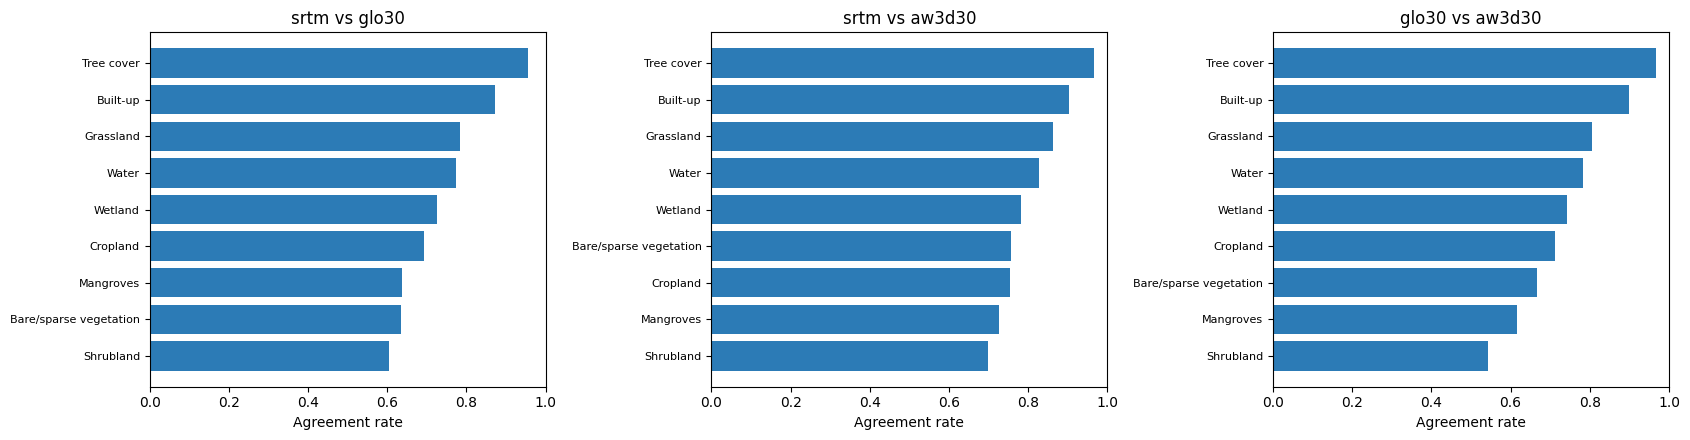

In [33]:
if RUN_MODE == 'PREPARE_MAPS':
    lc_band = landcover.rename('lc')

    WORLDCOVER_NAMES = {
        10: 'Tree cover', 20: 'Shrubland', 30: 'Grassland', 40: 'Cropland',
        50: 'Built-up', 60: 'Bare/sparse vegetation', 70: 'Snow/ice', 80: 'Water',
        90: 'Wetland', 95: 'Mangroves', 100: 'Moss/lichen',
    }

    def grouped_mean_by_lc(img):
        # Rata-rata img per kelas tutupan lahan WorldCover.
        res = (img.rename('v').addBands(lc_band)
               .reduceRegion(
                   reducer=ee.Reducer.mean().group(groupField=1, groupName='lc'),
                   geometry=roi, scale=30, maxPixels=1e13, tileScale=TILE_SCALE
               ).getInfo())
        out = {}
        for g in res.get('groups', []):
            if g.get('mean') is not None:
                out[int(g['lc'])] = g['mean']
        return out

    wc_rows = []
    for p in pairs:
        pair_label = f'{p[0]} vs {p[1]}'

        mean_dp = grouped_mean_by_lc(delta_abs[p])
        for lc_code, v in mean_dp.items():
            wc_rows.append({'pair': pair_label, 'metric': 'mean_abs_delta_prob',
                            'lc_code': lc_code, 'lc_name': WORLDCOVER_NAMES.get(lc_code, str(lc_code)),
                            'value': v})

        agree = grouped_mean_by_lc(agreement_map[p])
        for lc_code, v in agree.items():
            wc_rows.append({'pair': pair_label, 'metric': 'agreement_rate',
                            'lc_code': lc_code, 'lc_name': WORLDCOVER_NAMES.get(lc_code, str(lc_code)),
                            'value': v})

        changed = risk_class[p[0]].neq(risk_class[p[1]]).rename('changed')
        prop_changed = grouped_mean_by_lc(changed)
        for lc_code, v in prop_changed.items():
            wc_rows.append({'pair': pair_label, 'metric': 'prop_class_changed',
                            'lc_code': lc_code, 'lc_name': WORLDCOVER_NAMES.get(lc_code, str(lc_code)),
                            'value': v})

    worldcover_df = pd.DataFrame(wc_rows)
    worldcover_df.to_csv(os.path.join(OUTPUT_DIR, 'worldcover_sensitivity.csv'), index=False)
    display(worldcover_df)

    # Visualisasi: agreement rate per kelas tutupan lahan.
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for ax, p in zip(np.atleast_1d(axes), pairs):
        sub = (worldcover_df[(worldcover_df['pair'] == f'{p[0]} vs {p[1]}') &
                             (worldcover_df['metric'] == 'agreement_rate')]
               .sort_values('value'))
        if len(sub):
            ax.barh(sub['lc_name'], sub['value'], color='#2c7bb6')
        ax.set_xlim(0, 1)
        ax.set_xlabel('Agreement rate')
        ax.set_title(f'{p[0]} vs {p[1]}')
        ax.tick_params(axis='y', labelsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'agreement_per_landcover.png'), dpi=200, bbox_inches='tight')
    plt.show()

In [34]:
# v27: mode cached menampilkan tabel statistik spasial BEKU (hasil GEE dari PREPARE_MAPS), checksum diperiksa.
if RUN_MODE == 'USE_CACHED_DATA':
    for _f in ['sensitivity_summary.csv', 'area_per_risk_class_km2.csv', 'worldcover_sensitivity.csv',
               'transition_srtm_vs_glo30.csv', 'transition_srtm_vs_aw3d30.csv', 'transition_glo30_vs_aw3d30.csv']:
        _t = load_gee_table(_f)
        if _t is not None:
            print('==', _f)
            print(_t.head(12).to_string(index=False))

## 18. Export peta dan data ke Google Drive

**v27:** ekspor peta memakai unduhan langsung per tile (`computePixels`) dengan status `PENDING/RUNNING/COMPLETED/FAILED` di `data/export_status.json`. Kode `Export.toDrive` v26 dipertahankan di cell berikutnya, nonaktif secara default.

In [35]:
# =========================================================
# v27 - EKSPOR PETA KE GeoTIFF (mode PREPARE_MAPS)
# Pengganti Export.toDrive v26. Alasannya:
#  - task toDrive oleh service account mendarat di Drive milik service account,
#    bukan Drive pengguna, dan v26 hanya mencetak "Export started" tanpa memeriksa hasil.
#  - Di sini raster diunduh langsung per tile (ee.data.computePixels) pada grid yang dipatok
#    eksplisit, ditulis ke folder data, diverifikasi, baru berstatus COMPLETED.
# Kode Export.toDrive v26 tetap ada di cell berikutnya (nonaktif secara default).
# =========================================================
def build_grid_from_roi():
    bb = roi.bounds(1, ANALYSIS_CRS).getInfo()
    ring = bb['coordinates'][0]
    xs, ys = [c[0] for c in ring], [c[1] for c in ring]
    if max(abs(v) for v in xs + ys) < 1000:
        raise RuntimeError('Koordinat bounding box bukan meter UTM (nilai terlalu kecil). '
                           'Periksa roi.bounds(maxError, proj).')
    return make_grid(min(xs), min(ys), max(xs), max(ys), crs=ANALYSIS_CRS, res=ANALYSIS_SCALE)


def fetch_tile_gee(image, tile):
    # Satu tile GeoTIFF pada grid persis yang diminta (dimensi + affine + CRS).
    params = {
        'expression': image,
        'fileFormat': 'GEO_TIFF',
        'grid': {
            'dimensions': {'width': tile['width'], 'height': tile['height']},
            'affineTransform': {'scaleX': GRID['res'], 'shearX': 0, 'translateX': tile['x0'],
                                'shearY': 0, 'scaleY': -GRID['res'], 'translateY': tile['y1']},
            'crsCode': GRID['crs'],
        },
    }
    return ee.data.computePixels(params)


if RUN_MODE == 'PREPARE_MAPS':
    # 1. Bekukan tabel statistik spasial hasil GEE (sudah dihitung di cell 39, 40, 42).
    for _f in ['sensitivity_summary.csv', 'area_per_risk_class_km2.csv', 'worldcover_sensitivity.csv',
               'transition_srtm_vs_glo30.csv', 'transition_srtm_vs_aw3d30.csv',
               'transition_glo30_vs_aw3d30.csv']:
        freeze_gee_table(_f)

    # 2. Grid dan daftar raster.
    GRID = build_grid_from_roi()
    print('Grid ekspor:', GRID)
    _aoi_px = None
    try:
        _aoi_px = int(round(float(prob_map[DEM_NAMES[0]].mask().rename('m').reduceRegion(
            reducer=ee.Reducer.sum(), geometry=roi, scale=ANALYSIS_SCALE,
            maxPixels=1e13, tileScale=TILE_SCALE).get('m').getInfo())))
        print('Piksel valid peta (GEE, grid asli):', _aoi_px)
    except Exception as _e:
        print('Hitungan piksel valid GEE dilewati:', _e)
    _st = status_load()
    _st['grid'] = GRID
    _st['aoi_pixel_count_gee'] = _aoi_px
    status_save(_st)

    _jobs = []
    for _d in DEM_NAMES:
        _jobs.append((f'prob_{_d}', 'prob', prob_map[_d]))
        _jobs.append((f'risk_class_{_d}', 'risk', risk_class[_d]))
    for _p in pairs:
        _jobs.append((f'delta_abs_{_p[0]}_vs_{_p[1]}', 'delta', delta_abs[_p]))
        _jobs.append((f'agreement_{_p[0]}_vs_{_p[1]}', 'agreement', agreement_map[_p]))
    _jobs.append(('proxy_flood_label_sentinel1', 'label', flood_label))

    # 3. Unduh, mosaik, tulis, verifikasi. Satu raster gagal tidak menghentikan yang lain.
    for _name, _kind, _img in _jobs:
        print(f'== {_name} ({_kind})')
        export_raster(_name, _kind, _img.toFloat().unmask(EXPORT_NODATA), GRID, fetch_tile_gee)

    # 4. Verifikasi menyeluruh dan catat ke manifest/status.
    EXPORT_CHECKS = verify_all_rasters(GRID, _aoi_px)
    _nfail = print_checks(EXPORT_CHECKS)
    _st = status_load()
    _st['validation'] = {'checked_at_utc': _utcnow(), 'checks': EXPORT_CHECKS}
    status_save(_st)
    _stm = status_load()['rasters']
    manifest_update(maps={
        'grid': GRID, 'nodata': EXPORT_NODATA, 'breaks': [float(b) for b in BREAKS],
        'risk_class_method': RISK_CLASS_METHOD, 'rf_gee': RF_GEE,
        'note_models': 'Peta: ee.Classifier.smileRandomForest 300 pohon (GEE). Evaluasi: sklearn RandomForest 400 pohon. Dua model berbeda.',
        'rasters': {n: {'status': r['status'], 'sha256': r.get('sha256')} for n, r in _stm.items()},
        'created_at_utc': _utcnow()})
    _failed = [n for n, r in _stm.items() if r['status'] != 'COMPLETED']
    if _failed or _nfail:
        print('\nPERHATIAN: ada raster belum COMPLETED atau verifikasi FAIL. Lihat pesan di atas dan '
              'data/export_status.json. Jalankan ulang cell ini untuk melanjutkan (raster COMPLETED dilewati).')
    else:
        print('\nSemua raster COMPLETED dan lolos verifikasi.')
else:
    print('Ekspor peta dilewati (RUN_MODE != PREPARE_MAPS).')

Grid ekspor: {'crs': 'EPSG:32749', 'res': 30.0, 'x0': 419280.0, 'y1': 9258540.0, 'width': 2074, 'height': 1592}
Piksel valid peta (GEE, grid asli): 1438214
== prob_srtm (prob)
  prob_srtm tile 1/6 OK (39 s)
  prob_srtm tile 2/6 OK (110 s)
  prob_srtm tile 3/6 OK (23 s)
  prob_srtm tile 4/6 OK (47 s)
  prob_srtm tile 5/6 OK (23 s)
  prob_srtm tile 6/6 OK (16 s)
prob_srtm: COMPLETED | valid=3292156 nodata=9652 rentang=[0, 0.9875]
== risk_class_srtm (risk)
  risk_class_srtm tile 1/6 OK (37 s)
  risk_class_srtm tile 2/6 OK (142 s)
  risk_class_srtm tile 3/6 OK (23 s)
  risk_class_srtm tile 4/6 OK (34 s)
  risk_class_srtm tile 5/6 OK (19 s)
  risk_class_srtm tile 6/6 OK (26 s)
risk_class_srtm: COMPLETED | valid=3301808 nodata=0 rentang=[1, 5]
== prob_glo30 (prob)
  prob_glo30 tile 1/6 OK (75 s)


  prob_glo30 tile 2/6 OK (128 s)
  prob_glo30 tile 3/6 OK (17 s)
  prob_glo30 tile 4/6 OK (34 s)
  prob_glo30 tile 5/6 OK (40 s)
  prob_glo30 tile 6/6 OK (14 s)
prob_glo30: COMPLETED | valid=3292156 nodata=9652 rentang=[0, 0.9874]
== risk_class_glo30 (risk)
  risk_class_glo30 tile 1/6 OK (59 s)
  risk_class_glo30 tile 2/6 OK (130 s)
  risk_class_glo30 tile 3/6 OK (32 s)
  risk_class_glo30 tile 4/6 OK (48 s)


  risk_class_glo30 tile 5/6 OK (23 s)
  risk_class_glo30 tile 6/6 OK (16 s)
risk_class_glo30: COMPLETED | valid=3301808 nodata=0 rentang=[1, 5]
== prob_aw3d30 (prob)
  prob_aw3d30 tile 1/6 OK (97 s)


  prob_aw3d30 tile 2/6 percobaan 1/3 gagal: EEException: Earth Engine memory capacity exceeded.


  prob_aw3d30 tile 2/6 percobaan 2/3 gagal: EEException: Earth Engine memory capacity exceeded.


  prob_aw3d30 tile 2/6 OK (1100 s)
  prob_aw3d30 tile 3/6 OK (22 s)


  prob_aw3d30 tile 4/6 OK (41 s)
  prob_aw3d30 tile 5/6 OK (27 s)
  prob_aw3d30 tile 6/6 OK (40 s)
prob_aw3d30: COMPLETED | valid=3277653 nodata=24155 rentang=[0, 0.9878]
== risk_class_aw3d30 (risk)
  risk_class_aw3d30 tile 1/6 OK (34 s)
  risk_class_aw3d30 tile 2/6 OK (184 s)
  risk_class_aw3d30 tile 3/6 OK (29 s)
  risk_class_aw3d30 tile 4/6 OK (51 s)
  risk_class_aw3d30 tile 5/6 OK (37 s)
  risk_class_aw3d30 tile 6/6 OK (12 s)
risk_class_aw3d30: COMPLETED | valid=3301808 nodata=0 rentang=[1, 5]
== delta_abs_srtm_vs_glo30 (delta)
  delta_abs_srtm_vs_glo30 tile 1/6 OK (89 s)
  delta_abs_srtm_vs_glo30 tile 2/6 OK (306 s)
  delta_abs_srtm_vs_glo30 tile 3/6 OK (31 s)
  delta_abs_srtm_vs_glo30 tile 4/6 OK (75 s)
  delta_abs_srtm_vs_glo30 tile 5/6 OK (34 s)
  delta_abs_srtm_vs_glo30 tile 6/6 OK (27 s)
delta_abs_srtm_vs_glo30: COMPLETED | valid=3292156 nodata=9652 rentang=[0, 0.87]
== agreement_srtm_vs_glo30 (agreement)
  agreement_srtm_vs_glo30 tile 1/6 OK (38 s)
  agreement_srtm_vs_glo30 

  agreement_srtm_vs_glo30 tile 5/6 OK (48 s)
  agreement_srtm_vs_glo30 tile 6/6 OK (17 s)
agreement_srtm_vs_glo30: COMPLETED | valid=3301808 nodata=0 rentang=[0, 1]
== delta_abs_srtm_vs_aw3d30 (delta)
  delta_abs_srtm_vs_aw3d30 tile 1/6 OK (46 s)
  delta_abs_srtm_vs_aw3d30 tile 2/6 OK (202 s)
  delta_abs_srtm_vs_aw3d30 tile 3/6 OK (23 s)
  delta_abs_srtm_vs_aw3d30 tile 4/6 OK (54 s)
  delta_abs_srtm_vs_aw3d30 tile 5/6 OK (66 s)
  delta_abs_srtm_vs_aw3d30 tile 6/6 OK (16 s)
delta_abs_srtm_vs_aw3d30: COMPLETED | valid=3277653 nodata=24155 rentang=[0, 0.7282]
== agreement_srtm_vs_aw3d30 (agreement)
  agreement_srtm_vs_aw3d30 tile 1/6 OK (38 s)
  agreement_srtm_vs_aw3d30 tile 2/6 OK (105 s)
  agreement_srtm_vs_aw3d30 tile 3/6 OK (18 s)
  agreement_srtm_vs_aw3d30 tile 4/6 OK (52 s)
  agreement_srtm_vs_aw3d30 tile 5/6 OK (24 s)
  agreement_srtm_vs_aw3d30 tile 6/6 OK (13 s)
agreement_srtm_vs_aw3d30: COMPLETED | valid=3301808 nodata=0 rentang=[0, 1]
== delta_abs_glo30_vs_aw3d30 (delta)
  delta

In [36]:
# v26 (LEGACY, nonaktif): Export.toDrive oleh service account. Aktifkan hanya dengan EXPORT_TO_DRIVE_LEGACY = True.
if EXPORT_TO_DRIVE_LEGACY and RUN_MODE == 'PREPARE_MAPS':
    # Guard EXPORT_TO_DRIVE v24 (pelajaran v21: satu task gagal TIDAK boleh
    # menghentikan kernel; kegagalan di-log, ekspor lainnya lanjut).
    EXPORT_TO_DRIVE = True
    DRIVE_FOLDER = 'GEE_DEM_Sensitivity_Semarang_Demak'

    def export_image(img, name):
        if not EXPORT_TO_DRIVE:
            print('EXPORT_TO_DRIVE = False - lewati', name)
            return
        try:
            task = ee.batch.Export.image.toDrive(
                image=img.toFloat(),
                description=name,
                folder=DRIVE_FOLDER,
                fileNamePrefix=name,
                region=roi,
                scale=30,
                maxPixels=1e13
            )
            task.start()
            print('Export started:', name)
        except Exception as e:
            print(f'Export GAGAL ({name}): {e}')

    if EXPORT_TO_DRIVE:
        # Peta probabilitas, kelas kerawanan, delta, dan kesesuaian.
        for name in DEM_NAMES:
            export_image(prob_map[name], f'prob_{name}')
            export_image(risk_class[name], f'risk_class_{name}')
        for p in pairs:
            export_image(delta_abs[p], f'delta_abs_{p[0]}_vs_{p[1]}')
            export_image(agreement_map[p], f'agreement_{p[0]}_vs_{p[1]}')

        # Label banjir dan sampel training.
        export_image(flood_label.toByte(), 'proxy_flood_label_sentinel1')
        try:
            task_table = ee.batch.Export.table.toDrive(
                collection=sample_fc,
                description='training_sample_dem_sensitivity',
                folder=DRIVE_FOLDER,
                fileNamePrefix='training_sample_dem_sensitivity',
                fileFormat='CSV'
            )
            task_table.start()
            print('Export started: training_sample_dem_sensitivity (CSV)')
        except Exception as e:
            print(f'Export tabel sampel GAGAL: {e}')
    else:
        print('EXPORT_TO_DRIVE = False. Ubah menjadi True jika ingin export ke Google Drive.')
    print('Catatan: CSV metrik/sensitivitas sudah tersimpan di OUTPUT_DIR:', OUTPUT_DIR)

## 18b. Visualisasi lokal peta dari GeoTIFF (v27)

Membaca `data/rasters/*.tif`. Tidak memanggil GEE dan bekerja di Kaggle maupun Colab.

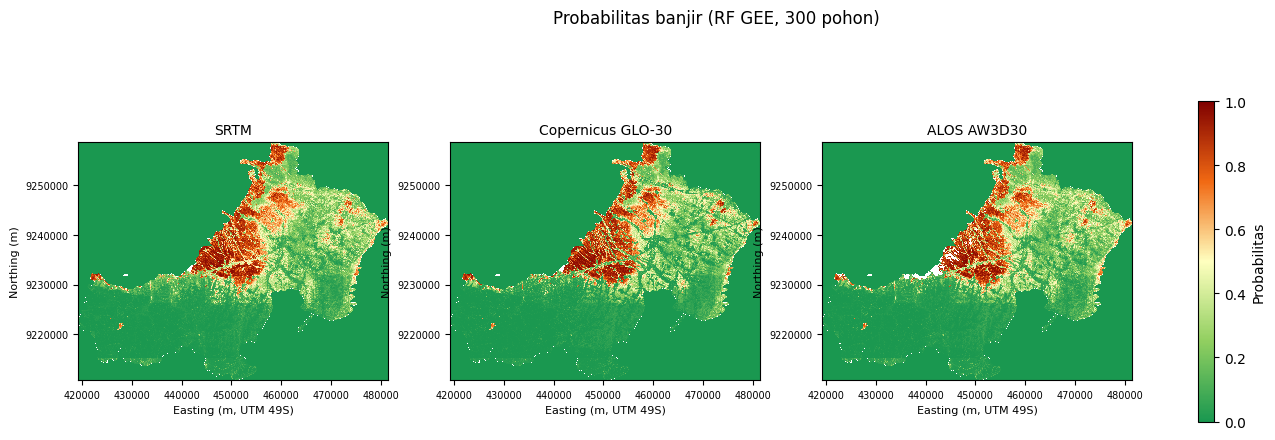

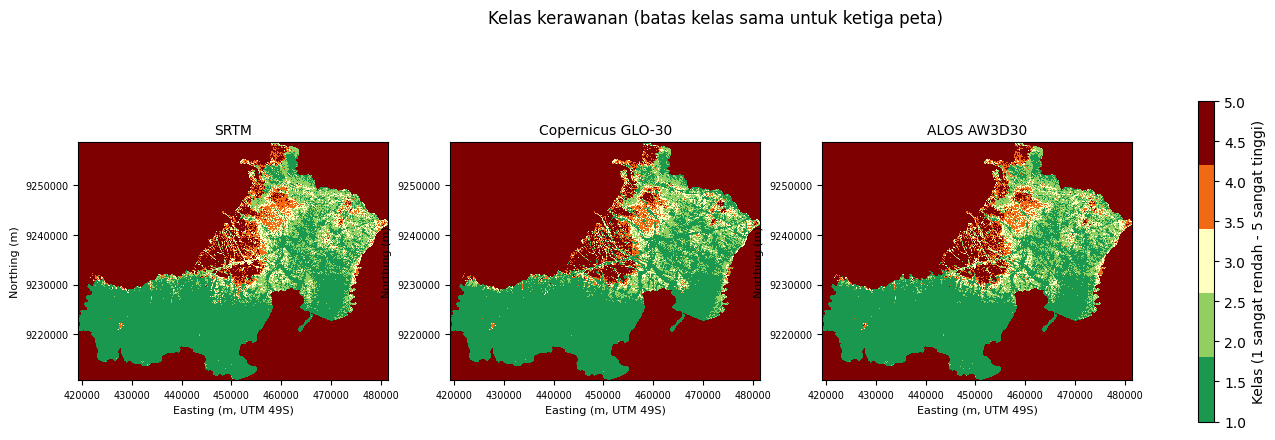

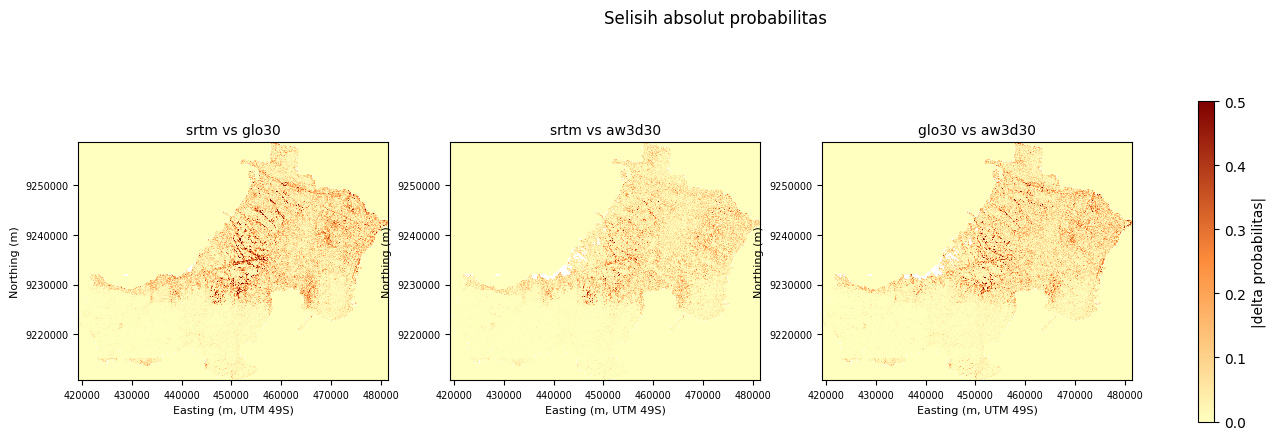

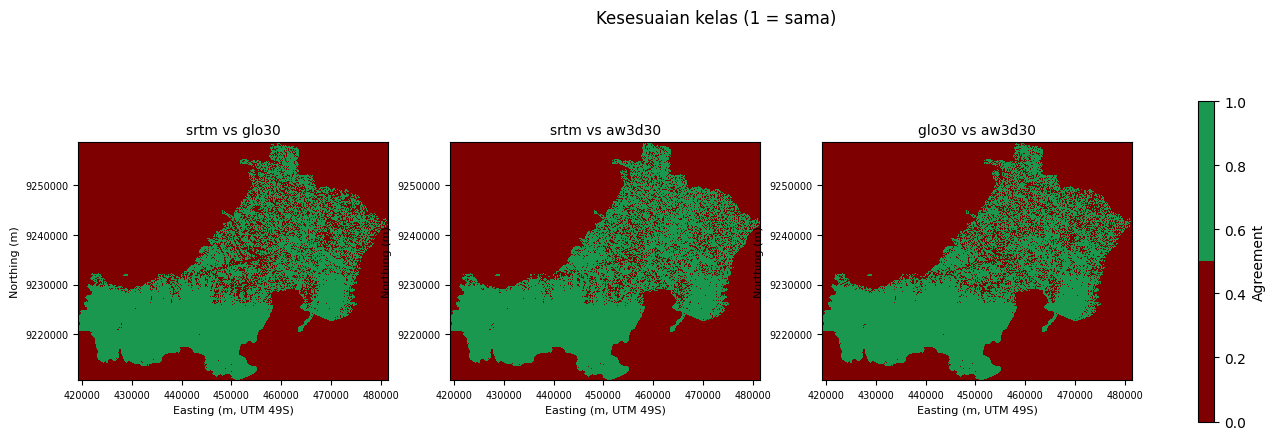

Figure peta lokal tersimpan di: /content/drive/MyDrive/Analisis Flood DEM Susceptibility/outputs/maps_local


In [37]:
# =========================================================
# v27 - VISUALISASI LOKAL PETA (semua mode, tanpa GEE)
# Membaca GeoTIFF dari data/rasters. Jika belum ada, tampilkan pesan, evaluasi tidak terpengaruh.
# =========================================================
from matplotlib.colors import ListedColormap, LinearSegmentedColormap


def _load_local(name):
    arr, valid = _raster_array(name)
    rasterio = _rio()
    with rasterio.open(os.path.join(PATHS['rasters'], name + '.tif')) as ds:
        b = ds.bounds
    return np.ma.masked_where(~valid, arr), (b.left, b.right, b.bottom, b.top)


def _panel(ax, name, title, cmap, vmin, vmax):
    img, ext = _load_local(name)
    im = ax.imshow(img, extent=ext, cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Easting (m, UTM 49S)', fontsize=8)
    ax.set_ylabel('Northing (m)', fontsize=8)
    ax.tick_params(labelsize=7)
    ax.ticklabel_format(style='plain')
    return im


def show_local_maps():
    st = status_load() if os.path.isfile(PATHS['export_status']) else None
    need = ([f'prob_{d}' for d in DEM_NAMES] + [f'risk_class_{d}' for d in DEM_NAMES] +
            [f'delta_abs_{a}_vs_{b}' for a, b in MAP_PAIRS] + [f'agreement_{a}_vs_{b}' for a, b in MAP_PAIRS])
    missing = [n for n in need if not st or st['rasters'].get(n, {}).get('status') != 'COMPLETED'
               or not os.path.isfile(os.path.join(PATHS['rasters'], n + '.tif'))]
    if missing:
        print('Peta GeoTIFF belum tersedia lengkap (' + str(len(missing)) + ' raster belum COMPLETED).')
        print('Jalankan notebook dengan RUN_MODE = \'PREPARE_MAPS\' untuk membentuknya. '
              'Bagian evaluasi tidak terpengaruh.')
        return False
    for n in need:     # integritas file sebelum dipakai
        if sha256_file(os.path.join(PATHS['rasters'], n + '.tif')) != st['rasters'][n]['sha256']:
            raise FrozenDataError(f'Raster {n}.tif berubah sejak diekspor (SHA-256 berbeda).')
    cm_prob = LinearSegmentedColormap.from_list('prob', PROB_VIS['palette'])
    cm_risk = ListedColormap(RISK_VIS['palette'])
    cm_delta = LinearSegmentedColormap.from_list('delta', DELTA_VIS['palette'])
    cm_agree = ListedColormap(['#7f0000', '#1a9850'])

    def row(title, items, cmap, vmin, vmax, fname, cbar_label):
        fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
        for ax, (nm, tt) in zip(axes, items):
            im = _panel(ax, nm, tt, cmap, vmin, vmax)
        fig.colorbar(im, ax=list(axes), shrink=0.8, label=cbar_label)
        fig.suptitle(title)
        fig.savefig(os.path.join(PATHS['maps_local'], fname), dpi=200, bbox_inches='tight')
        plt.show()

    lab = {d: DEM_CONFIGS[d]['label'] for d in DEM_NAMES}
    row('Probabilitas banjir (RF GEE, 300 pohon)', [(f'prob_{d}', lab[d]) for d in DEM_NAMES],
        cm_prob, 0, 1, 'local_prob_maps.png', 'Probabilitas')
    row('Kelas kerawanan (batas kelas sama untuk ketiga peta)', [(f'risk_class_{d}', lab[d]) for d in DEM_NAMES],
        cm_risk, 1, 5, 'local_risk_class_maps.png', 'Kelas (1 sangat rendah - 5 sangat tinggi)')
    row('Selisih absolut probabilitas', [(f'delta_abs_{a}_vs_{b}', f'{a} vs {b}') for a, b in MAP_PAIRS],
        cm_delta, 0, 0.5, 'local_delta_maps.png', '|delta probabilitas|')
    row('Kesesuaian kelas (1 = sama)', [(f'agreement_{a}_vs_{b}', f'{a} vs {b}') for a, b in MAP_PAIRS],
        cm_agree, 0, 1, 'local_agreement_maps.png', 'Agreement')
    print('Figure peta lokal tersimpan di:', PATHS['maps_local'])
    return True


LOCAL_MAPS_SHOWN = show_local_maps()

## 18c. Global Moran's I pada peta probabilitas (v27)

Membaca GeoTIFF probabilitas per DEM. Jika raster belum tersedia, hasil dinyatakan belum tersedia (tidak dihitung).

In [38]:
# =========================================================
# v27 - GLOBAL MORAN'S I pada PETA probabilitas kerawanan (raster GEE 300 pohon) per DEM.
# Membaca GeoTIFF dari data/rasters. Jika raster belum ada (PREPARE_MAPS belum dijalankan),
# hasil dinyatakan BELUM TERSEDIA dan TIDAK dihitung. Peta berasal dari model yang dilatih pada
# seluruh sampel, jadi ini ukuran struktur spasial permukaan prediksi, bukan ukuran kinerja OOF.
# W = queen 8 tetangga, row-standardized, grid yang sama untuk ketiga DEM.
# =========================================================
RUN_MORAN_MAP = True


def run_moran_map():
    st = status_load() if os.path.isfile(PATHS['export_status']) else None
    names = [f'prob_{d}' for d in DEM_NAMES]
    if not st or any(st['rasters'].get(n, {}).get('status') != 'COMPLETED' for n in names):
        print('Raster probabilitas belum COMPLETED. Moran\'s I peta BELUM DIHITUNG (hasil belum tersedia). '
              'Jalankan PREPARE_MAPS lebih dulu.')
        return None
    rows = []
    for d in DEM_NAMES:
        p = os.path.join(PATHS['rasters'], f'prob_{d}.tif')
        if sha256_file(p) != st['rasters'][f'prob_{d}']['sha256']:
            raise FrozenDataError(f'prob_{d}.tif berubah sejak diekspor (SHA-256 berbeda).')
        arr, valid = _raster_array(f'prob_{d}')
        t0 = time.time()
        r = moran_raster(arr, valid)
        r.update({'scope': 'peta_probabilitas', 'dem': d, 'weights': 'queen 8 tetangga, row-standardized',
                  'perm_method': 'permutasi kondisional (acak nilai lintas piksel valid)', 'seed': MORAN_SEED})
        rows.append(r)
        print(f'{d}: I={r["I"]:.4f} (E[I]={r["E_I"]:.2e}), n={r["n"]}, B={r["n_perm"]}, '
              f'p_dua_sisi={r["p_two_sided"]:.4f} ({time.time() - t0:.0f} s)')
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(OUTPUT_DIR, 'moran_prob_map_global.csv'), index=False)
    print('Catatan: pada n sangat besar, p permutasi hampir selalu mencapai batas resolusi 1/(B+1). '
          'Yang informatif adalah besar I, bukan p.')
    return df


moran_map_df = run_moran_map() if RUN_MORAN_MAP else None

srtm: I=0.9701 (E[I]=-3.04e-07), n=3292156, B=999, p_dua_sisi=0.0010 (171 s)
glo30: I=0.9648 (E[I]=-3.04e-07), n=3292156, B=999, p_dua_sisi=0.0010 (184 s)
aw3d30: I=0.9673 (E[I]=-3.05e-07), n=3277652, B=999, p_dua_sisi=0.0010 (179 s)
Catatan: pada n sangat besar, p permutasi hampir selalu mencapai batas resolusi 1/(B+1). Yang informatif adalah besar I, bukan p.


## 19. Metodologi utama

1. **Flood inventory (dikunci).** Label banjir dibentuk satu kali dari perubahan *backscatter* Sentinel-1 SAR pra/pasca kejadian (Maret 2024), dengan masking air permanen JRC dan filter noise *connected pixels*. Label ini dipakai identik pada ketiga eksperimen.
2. **Faktor perlakuan.** Satu-satunya komponen yang berubah adalah sumber produk elevasi: SRTM, Copernicus DEM GLO-30, dan ALOS AW3D30. Dari masing-masing dihitung elevasi, slope, dan aspect dengan prosedur identik (`ee.Terrain`), termasuk penanganan void mask AW3D30 dan pelaporan offset vertikal EGM96/EGM2008.
3. **Prediktor non-DEM (dikunci).** HAND, log-upstream area, river width, jarak sungai, jarak air permanen, curah hujan antecedent 7/30 hari, NDVI, NDWI, MNDWI, NDBI, dan tutupan lahan — mengikuti set baseline artikel SMDS.
4. **Sampling dan split (dikunci).** Stratified sampling satu kali dari gabungan semua band dengan seed tetap; titik dan jumlah sampel identik untuk ketiga konfigurasi. Train/test split memakai seed sama sehingga data uji identik.
5. **Random Forest (dikunci).** Evaluasi memakai sklearn (400 pohon, min samples leaf 2, class weight balanced); pemetaan spasial memakai `ee.Classifier.smileRandomForest` (300 pohon) pada sampel yang sama.
6. **Evaluasi.** ROC-AUC, accuracy, precision, recall, F1 pada data uji identik; ambang klasifikasi via indeks Youden. Sensitivitas performa = delta metrik antarproduk.
7. **Sensitivitas spasial.** Peta |delta probabilitas| pairwise, tingkat kesesuaian kelas, matriks perpindahan kelas, dan luas area per kelas.
8. **Stratifikasi WorldCover.** Seluruh metrik sensitivitas dihitung ulang per kelas tutupan lahan untuk menguji apakah sensitivitas sumber elevasi berbeda antar jenis permukaan.

## 20. Batasan penelitian

1. Label banjir berasal dari deteksi Sentinel-1 (*proxy label*), bukan validasi lapangan; galat deteksi SAR pada area urban padat, vegetasi rapat, dan tambak dapat terjadi.
2. Masking slope pada pembentukan label mengikuti baseline (SRTM) dan
   dikonsistenkan untuk semua konfigurasi. Justifikasi empiris: label
   hidup di medan datar (98,8-99,97% titik banjir < 5 deg pada ketiga
   DEM), sehingga filter terutama membuang artefak layover/foreshortening
   di lereng selatan; variasi slope antar-DEM pada domain label hampir nol.
3. SRTM memakai acuan EGM96 sedangkan Copernicus/AW3D30 memakai EGM2008; offset rata-rata dilaporkan (koreksi opsional). Ketiga produk bukan *bare-earth* DTM murni — SRTM adalah DEM radar pita-C, Copernicus GLO-30 dan AW3D30 adalah DSM.
4. Hasil sensitivitas bersifat konteks-spesifik: satu wilayah, satu kejadian banjir, dan satu set prediktor baseline.
5. Interpretasi kelas kerawanan bergantung pada batas klasifikasi; batas kelas yang sama dipakai untuk ketiga peta agar perbandingan valid.
6. Output berupa kerawanan (susceptibility), bukan prediksi genangan real-time.

## 20b. Metodologi tambahan: autokorelasi spasial, spatial leakage, dan Global Moran's I (v27)

**Autokorelasi spasial.** Nilai pada lokasi yang berdekatan cenderung lebih mirip daripada lokasi yang berjauhan. Pada data banjir hal ini wajar, karena genangan, elevasi, dan jarak ke sungai berubah secara kontinu di ruang. Akibatnya amatan tidak saling bebas dan pembagian data acak (random split) cenderung memberi estimasi kinerja yang terlalu optimistis.

**Spatial leakage.** Kebocoran spasial terjadi saat data uji berdekatan dengan data latih sehingga model dapat "mengingat" lingkungan lokasi uji dan bukan mempelajari hubungan yang dapat digeneralisasi. **Spatial cross-validation** (16 blok kuantil lon/lat, 4 fold, retrain per fold) mengurangi risiko ini dengan memisahkan blok uji dari blok latih. Pencegahan leakage bergantung pada rancangan pembagian spasial itu, bukan pada uji statistik apa pun. Blok yang bersebelahan tidak diberi zona penyangga (buffer), sehingga titik di tepi blok tetap dapat dekat dengan data latih.

**Global Moran's I (diagnostik pendukung).** Untuk nilai $x_i$ pada $n$ lokasi dengan bobot spasial $w_{ij}$ (distandardisasi baris, $S_0=\sum_{ij}w_{ij}=n$) dan $z_i=x_i-\bar{x}$:

$$I=\frac{n}{S_0}\,\frac{\sum_{i}\sum_{j}w_{ij}z_iz_j}{\sum_i z_i^2},\qquad E[I]=-\frac{1}{n-1}.$$

* Hipotesis: $H_0$: nilai tersebar acak secara spasial (tidak ada autokorelasi spasial), $H_1$: ada autokorelasi spasial (dua sisi).
* Taraf signifikansi $\alpha=0{,}05$. **Tolak $H_0$ jika $p$-value lebih kecil dari $\alpha$.**
* $p$-value berbasis **permutasi kondisional**: nilai diacak lintas lokasi tetap sebanyak $B=9.999$ kali (seed 42), $p=\dfrac{1+\#\{|I_{perm}-E[I]|\ge|I_{obs}-E[I]|\}}{B+1}$, sehingga $p$ terkecil yang dapat dilaporkan adalah $1/(B+1)=0{,}0001$. Untuk peta raster dipakai $B=999$.
* Data yang dianalisis: (a) probabilitas OOF dan (b) residual OOF $r_i=y_i-\hat{p}^{OOF}_i$ pada titik sampel, serta (c) peta probabilitas raster per DEM. Prediksi data latih tidak dipakai.
* Unit analisis adalah titik sampel, bukan 16 blok (satu blok hanya berisi 1 titik dan beberapa blok tidak memuat salah satu kelas, sehingga agregasi ke 16 unit tidak layak). Weights kNN ($k=8$, uji kepekaan $k=5,12$) dipilih karena titik tersebar tidak beraturan dengan kepadatan berbeda dan kNN menjamin tidak ada titik tanpa tetangga. Definisi weights **sama** untuk ketiga DEM.
* Hasil tidak signifikan tidak boleh dibaca sebagai bukti tidak ada autokorelasi. Moran's I tidak menghilangkan dan tidak membuktikan ketiadaan spatial leakage.

## 21. Laporan pembanding v26 vs v27 (v27)

Membandingkan `outputs/` dengan `data/reference_v26/` per komponen. Komponen tanpa hasil dinyatakan **BELUM DIUJI**, bukan lolos.

In [39]:
# =========================================================
# v27 - LAPORAN PEMBANDING v26 vs v27 (semua mode, tanpa GEE)
# Membandingkan CSV hasil run ini (outputs/) dengan hasil v26 (data/reference_v26/).
# Tiap komponen dilaporkan TERPISAH. Komponen yang tidak ada hasilnya dinyatakan BELUM DIUJI.
# Selisih tidak disamarkan: IDENTIK hanya bila semua nilai persis sama.
# =========================================================
COMPARE_COMPONENTS = {
    'evaluasi_utama': ['model_metrics.csv', 'delta_metrics_vs_srtm.csv', 'spatial_cv_metrics.csv',
                       'spatial_cv_test_predictions.csv', 'spatial_cv_delta_auc_bootstrap.csv',
                       'spatial_cv_delta_auc_bootstrap_pixel_legacy.csv', 'sample_audit.csv',
                       'training_sample_features.csv'],
    'multi_seed': ['multiseed_holdout.csv', 'multiseed_spatial_cv.csv', 'multiseed_summary.csv',
                   'multiseed_delta_auc.csv', 'multiseed_test_predictions.csv'],
    'statistik_spasial_peta': ['sensitivity_summary.csv', 'area_per_risk_class_km2.csv',
                               'transition_srtm_vs_glo30.csv', 'transition_srtm_vs_aw3d30.csv',
                               'transition_glo30_vs_aw3d30.csv', 'worldcover_sensitivity.csv'],
    'statistik_dem_gee': ['dem_stats.csv'],
}


def compare_csv(new_path, ref_path):
    if not os.path.isfile(ref_path):
        return 'TIDAK_ADA_REFERENSI', None, None, ''
    if not os.path.isfile(new_path):
        return 'BELUM_DIUJI', None, None, 'hasil v27 belum ada'
    a, b = pd.read_csv(new_path), pd.read_csv(ref_path)
    if list(a.columns) != list(b.columns) or a.shape != b.shape:
        return 'STRUKTUR_BEDA', None, None, f'v27 {a.shape} vs v26 {b.shape}'
    max_abs, max_rel, same = 0.0, 0.0, True
    for c in a.columns:
        if pd.api.types.is_numeric_dtype(a[c]) and pd.api.types.is_numeric_dtype(b[c]):
            x, y = a[c].to_numpy(dtype='float64'), b[c].to_numpy(dtype='float64')
            if not np.array_equal(x, y, equal_nan=True):
                same = False
                d = np.abs(x - y)
                d = d[np.isfinite(d)]
                if d.size:
                    max_abs = max(max_abs, float(d.max()))
                    den = np.maximum(np.abs(y), 1e-12)
                    max_rel = max(max_rel, float((np.abs(x - y) / den)[np.isfinite(x - y)].max()))
        elif not a[c].equals(b[c]):
            same = False
    return ('IDENTIK' if same else 'SELISIH_NUMERIK'), max_abs, max_rel, ''


def run_comparison(new_dir=None, ref_dir=None, save=True):
    new_dir, ref_dir = new_dir or PATHS['outputs'], ref_dir or PATHS['reference_v26']
    sums_p = os.path.join(ref_dir, 'SHA256SUMS.json')
    if os.path.isfile(sums_p):
        with open(sums_p, 'r', encoding='utf-8') as fh:
            sums = json.load(fh)
        bad = [f for f, h in sums.items() if os.path.isfile(os.path.join(ref_dir, f))
               and sha256_file(os.path.join(ref_dir, f)) != h]
        if bad:
            raise FrozenDataError(f'Berkas referensi v26 berubah (SHA-256 berbeda): {bad}')
        print(f'Referensi v26 utuh ({len(sums)} berkas, checksum cocok).')
    else:
        print('PERINGATAN: SHA256SUMS.json referensi v26 tidak ada. Integritas referensi tidak diperiksa.')
    rows = []
    for comp, files in COMPARE_COMPONENTS.items():
        for f in files:
            st, ma, mr, note = compare_csv(os.path.join(new_dir, f), os.path.join(ref_dir, f))
            rows.append({'komponen': comp, 'berkas': f, 'status': st,
                         'maks_selisih_abs': ma, 'maks_selisih_rel': mr, 'catatan': note})
    rep = pd.DataFrame(rows)
    if save:
        rep.to_csv(os.path.join(new_dir, 'validation_v26_vs_v27.csv'), index=False)
    return rep


COMPARISON = run_comparison()
print(COMPARISON.to_string(index=False))
print()
for _comp, _g in COMPARISON.groupby('komponen', sort=False):
    _tested = _g[~_g['status'].isin(['BELUM_DIUJI', 'TIDAK_ADA_REFERENSI'])]
    _same = int((_tested['status'] == 'IDENTIK').sum())
    print(f'{_comp:<24}: diuji {len(_tested)}/{len(_g)} berkas | identik {_same}/{len(_tested)}'
          + ('' if len(_tested) else '  -> BELUM DIUJI'))
print('\nCatatan tafsir: selisih dapat berasal dari (1) data GEE yang ditarik ulang berbeda dari run v26, '
      '(2) versi library berbeda (lihat outputs/run_environment.json), atau (3) kode. '
      'Pisahkan penyebabnya sebelum menyimpulkan. Status IDENTIK pada satu komponen tidak '
      'membuktikan komponen lain.')

PERINGATAN: SHA256SUMS.json referensi v26 tidak ada. Integritas referensi tidak diperiksa.
              komponen                                          berkas              status maks_selisih_abs maks_selisih_rel catatan
        evaluasi_utama                               model_metrics.csv TIDAK_ADA_REFERENSI             None             None        
        evaluasi_utama                       delta_metrics_vs_srtm.csv TIDAK_ADA_REFERENSI             None             None        
        evaluasi_utama                          spatial_cv_metrics.csv TIDAK_ADA_REFERENSI             None             None        
        evaluasi_utama                 spatial_cv_test_predictions.csv TIDAK_ADA_REFERENSI             None             None        
        evaluasi_utama              spatial_cv_delta_auc_bootstrap.csv TIDAK_ADA_REFERENSI             None             None        
        evaluasi_utama spatial_cv_delta_auc_bootstrap_pixel_legacy.csv TIDAK_ADA_REFERENSI             None    